# 🏡 주택 리모델링 가치 분석 — "집을 넓힐까, 설비를 들일까?"

> 주택 545채의 데이터로 **품질 점검 → EDA → 전처리 조합 비교 → 파생변수 모델**을 하나의 흐름으로 수행하고,
> 최종 모델로 **리모델링 의사결정**(면적 확장 vs 설비 추가)에 답했습니다.
> 편의·입지 옵션 6개를 **'보유 개수' 하나로 묶는 파생변수**로 변수를 11개 → 6개로 줄였고,
> **면적을 10% 넓히는 것(+3.1%)보다 옵션 하나를 들이는 것(+11.2%)이 가격에 3배 이상 유리**하다는 결론을 얻었습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | Housing · 545행 × 13개 변수 (결측 · 중복 없음) |
| **종속변수** | `price` 주택가격 (단위는 원본 데이터 기준) |
| **분석 질문** | ① 주택가격을 결정하는 요인은? ② 편의 옵션은 '종류'가 중요한가, '개수'가 중요한가? ③ 같은 집이라면 넓히는 것과 설비를 들이는 것 중 무엇이 가격에 유리한가? |
| **주요 기법** | Spearman 상관 · Mann-Whitney U · Welch ANOVA · Games-Howell · 파생변수 · 로그-로그 회귀 · 후진소거 OLS · HC3 |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드(1회), 분석 설정
1. **PART 1. 데이터 품질 점검** — `my_qtcheck`
2. **PART 2. EDA** — 단변량 → 이변량(옵션 6종 비교) → 다변량(옵션 개수 효과)
3. **PART 3. 회귀모델링** — 전처리 체크포인트 비교 → `amenity` 파생변수 모델 → EDA 판정 vs 모델 결과 → 최종 보고
4. **📌 종합 인사이트**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_ols` (helpers) · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [1]:
# ----- 라이브러리 참조
import numpy as np
from pandas import DataFrame, concat, set_option
from IPython.display import display, Markdown

from jussam import load_data      # 실습 데이터 로더
from helpers import *             # my_qtcheck · my_plot · my_stats · my_prep · my_ols

# ----- 출력 형식 (소수점 3자리, 컬럼 생략 없이)
set_option("display.float_format", "{:,.3f}".format)
set_option("display.max_columns", 50)

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: develop


### (2) 데이터 로드

In [3]:
origin = load_data("housing")
print(f'데이터 크기: {origin.shape}')
origin.head()

📚 주택 가격 데이터셋. 주택 면적, 침실 수, 가구 비치 여부, 주요 도로와의 근접성 등 특정 요소를 기반으로 주택 가격을 예측하는 간단하면서도 도전적인 프로젝트입니다. 데이터셋은 작지만, 다중공선성이 매우 높아 예측 모델 구축에 어려움이 있습니다. 이러한 난관을 극복하고 괜찮은 예측 모델을 만들 수 있을까요? (출처: https://www.kaggle.com/datasets/yasserh/housing-prices-dataset)

    field             description
--  ----------------  ----------------------------------------------------------------------------------------------------------------------------------------------------------------
 0  price             주택 가격 (USD 달러) - 예측 대상 변수
 1  area              주택 면적 (제곱 단위) - 주택의 건축 면적
 2  bedrooms          침실 수 (개수) - 주택의 침실 개수
 3  bathrooms         욕실 수 (개수) - 주택의 욕실 개수
 4  stories           주택 층 수 (개수) - 주택의 총 지상 층수
 5  mainroad          주요 도로 인접 여부 (이진형: Yes/No 또는 0/1) - 주택이 주요 도로에 인접해 있는지 여부
 6  guestroom         게스트룸 보유 여부 (이진형: Yes/No 또는 0/1) - 손님용 방이 있는지 여부
 7  basement          지하실 보유 여부 (이진형: Yes/No 또는 0/1) - 지하실이 있는지 여부
 8  hotwaterheating   온수 난방 시스템 보유 여부 (이진형: Yes/No 또는 0/1) - 온수 난방 시스템이 설치되어 있는지 여부
 9  a

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### (3) 분석 설정

| 구분 | 변수 | 의미 |
|---|---|---|
| 크기 | `area` · `bedrooms` · `bathrooms` · `stories` · `parking` | 면적 · 침실 수 · 욕실 수 · 층수 · 주차 대수 |
| 편의·입지 옵션 (yes/no) | `mainroad` · `guestroom` · `basement` · `hotwaterheating` · `airconditioning` · `prefarea` | 대로변 · 게스트룸 · 지하실 · 온수난방 · 에어컨 · 선호지역 |
| 가구 비치 | `furnishingstatus` | furnished(완비) · semi-furnished(반 비치) · unfurnished(미비치) |

- `amenity_cols` : 있으면 좋은 **편의·입지 옵션 6종**. PART 3에서 '보유 개수'로 묶는 파생변수를 만든다.

In [4]:
target = "price"                                  # 종속변수

# 있으면 좋은 편의·입지 옵션 6종 (yes/no) — PART 3에서 '보유 개수'로 묶는다
amenity_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
as_category = amenity_cols + ["furnishingstatus"]  # 명목형으로 지정할 컬럼

column_means = {
    "price": "가격", "area": "면적", "bedrooms": "침실수", "bathrooms": "욕실수",
    "stories": "층수", "parking": "주차대수", "mainroad": "대로변", "guestroom": "게스트룸",
    "basement": "지하실", "hotwaterheating": "온수난방", "airconditioning": "에어컨",
    "prefarea": "선호지역", "furnishingstatus": "가구비치", "amenity": "편의시설점수",
}

---
# PART 1. 데이터 품질 점검

### (1) 자료형 변환

In [5]:
df = my_qtcheck.set_type(data=origin, as_category=as_category)

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   price             545 non-null    int32   
 1   area              545 non-null    int32   
 2   bedrooms          545 non-null    int32   
 3   bathrooms         545 non-null    int32   
 4   stories           545 non-null    int32   
 5   mainroad          545 non-null    category
 6   guestroom         545 non-null    category
 7   basement          545 non-null    category
 8   hotwaterheating   545 non-null    category
 9   airconditioning   545 non-null    category
 10  parking           545 non-null    int32   
 11  prefarea          545 non-null    category
 12  furnishingstatus  545 non-null    category
dtypes: category(7), int32(6)
memory usage: 16.8 KB


### (2) 중복 · 결측치 점검

In [6]:
df = my_qtcheck.check_duplicates(data=df)
my_qtcheck.check_missing_values(data=df)

중복된 행의 수: 0


,Missing Count,Missing Ratio (%)
price,0,0.000
area,0,0.000
bedrooms,0,0.000
bathrooms,0,0.000
stories,0,0.000
mainroad,0,0.000
guestroom,0,0.000
basement,0,0.000
hotwaterheating,0,0.000
airconditioning,0,0.000


### (3) 명목형 변수 기술통계

In [8]:
cat_desc = my_qtcheck.categorical_summary(data=df)
cat_desc

컬럼 'mainroad'의 value_counts( ):


,count
mainroad,
no,77
yes,468


컬럼 'guestroom'의 value_counts( ):


,count
guestroom,
no,448
yes,97


컬럼 'basement'의 value_counts( ):


...

컬럼 'prefarea'의 value_counts( ):


,count
prefarea,
no,417
yes,128


컬럼 'furnishingstatus'의 value_counts( ):


,count
furnishingstatus,
furnished,140
semi-furnished,227
unfurnished,178


,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


### (4) 연속형 변수 기술통계 · 이상치 · 왜도/첨도 · 로그변환 판정

In [9]:
num_desc = my_qtcheck.numerical_summary(data=df)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,total_outliers,total_outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
price,545.000,"4,766,729.248","1,870,439.616","1,750,000.000","3,430,000.000","4,340,000.000","5,740,000.000","13,300,000.000",0.098,similar,"2,310,000.000","9,205,000.000","-35,000.000",15,0.028,0,0.000,15,0.028,1.212,right tail,1.960,leptokurtic,log
area,545.000,"5,150.541","2,170.141","1,650.000","3,600.000","4,600.000","6,360.000","16,200.000",0.120,diff,"2,760.000","10,500.000",-540.000,12,0.022,0,0.000,12,0.022,1.321,right tail,2.751,leptokurtic,log
bedrooms,545.000,2.965,0.738,1.000,2.000,3.000,3.000,6.000,0.012,similar,1.000,4.500,0.500,12,0.022,0,0.000,12,0.022,0.496,symmetric,0.728,leptokurtic,none
bathrooms,545.000,1.286,0.502,1.000,1.000,1.000,2.000,4.000,0.286,diff,1.000,3.500,-0.500,1,0.002,0,0.000,1,0.002,1.589,right tail,2.165,leptokurtic,log
stories,545.000,1.806,0.867,1.000,1.000,2.000,2.000,4.000,0.097,similar,1.000,3.500,-0.500,41,0.075,0,0.000,41,0.075,1.082,right tail,0.679,leptokurtic,log
parking,545.000,0.694,0.862,0.000,0.000,0.000,1.000,3.000,inf,large_diff,1.000,2.500,-1.500,12,0.022,0,0.000,12,0.022,0.842,right tail,-0.573,platykurtic,none


> 💡 **인사이트 — 품질 점검**
>
> - 545행 모두 **결측 0건 · 중복 0건**이다. yes/no 옵션 6개와 `furnishingstatus`를 category로 바꿨다.
> - 모듈은 4개 변수에 **log 변환**을 판정했다.
>   - `price`(왜도 1.21) · `area`(1.32) : 오른쪽 꼬리가 긴 우편향
>   - `bathrooms`(1.59) · `stories`(1.08) : 값이 몇 가지뿐인 정수형이지만 왜도 기준을 넘음
> - `stories`의 이상치 41건(7.5%)은 오류가 아니라 **3~4층짜리 소수의 집**이다. 값이 1~4층뿐인 정수 변수라 IQR 기준이 과민하게 반응한 것으로, 제거하지 않는다.

---
# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

In [10]:
nominal_cols = my_qtcheck.get_categorical_column_names(df)
continuous_cols = my_qtcheck.get_number_column_names(df)
continuous_cols.remove(target)

print("종속변수 :", target)
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : price
명목형   : ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
연속형   : ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']


## 2-1. 단변량 분석

### (1) 종속변수 분포

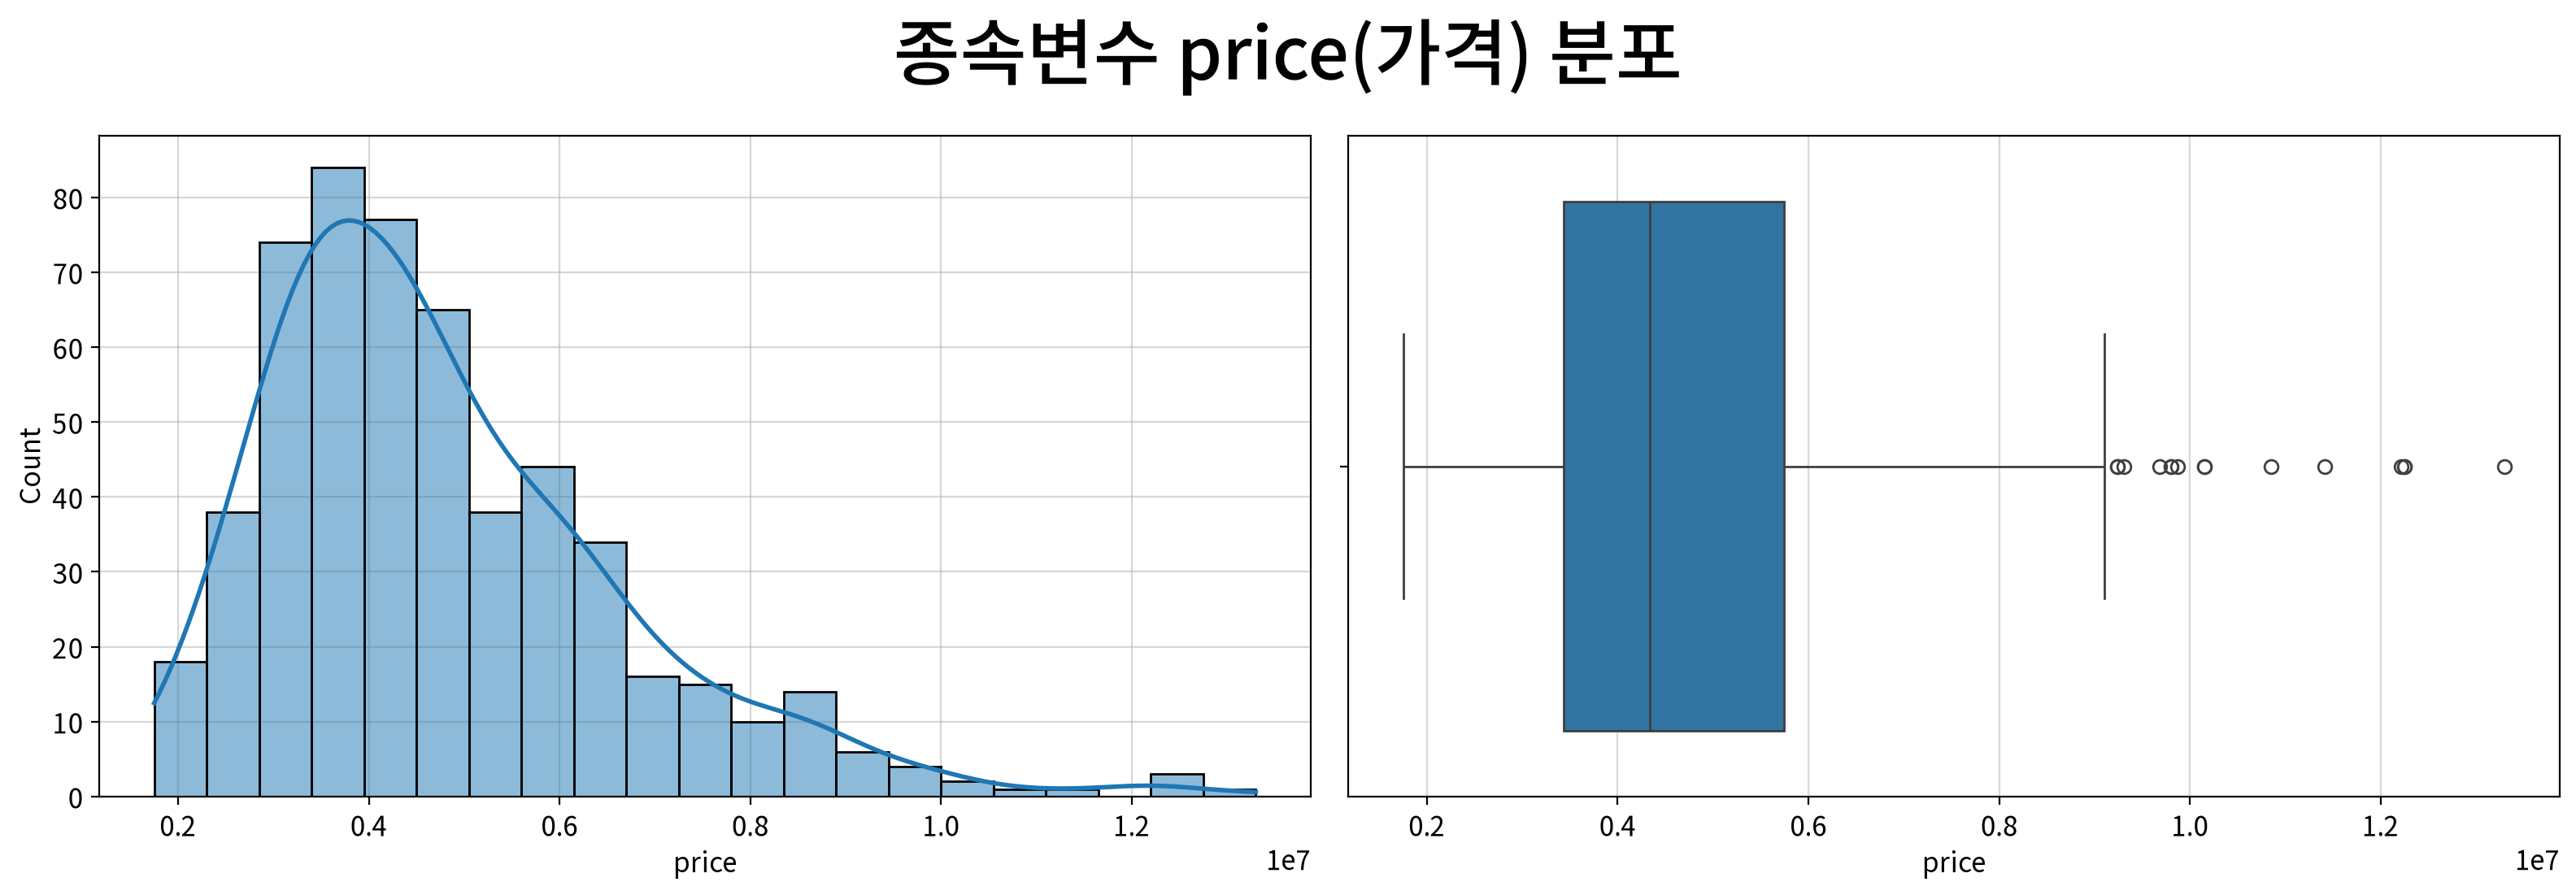

In [11]:
fig, ax = my_plot.init(rows=1, cols=2, width=800, height=560, title=f"종속변수 {target}({column_means[target]}) 분포")
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

### (2) 연속형 독립변수 분포

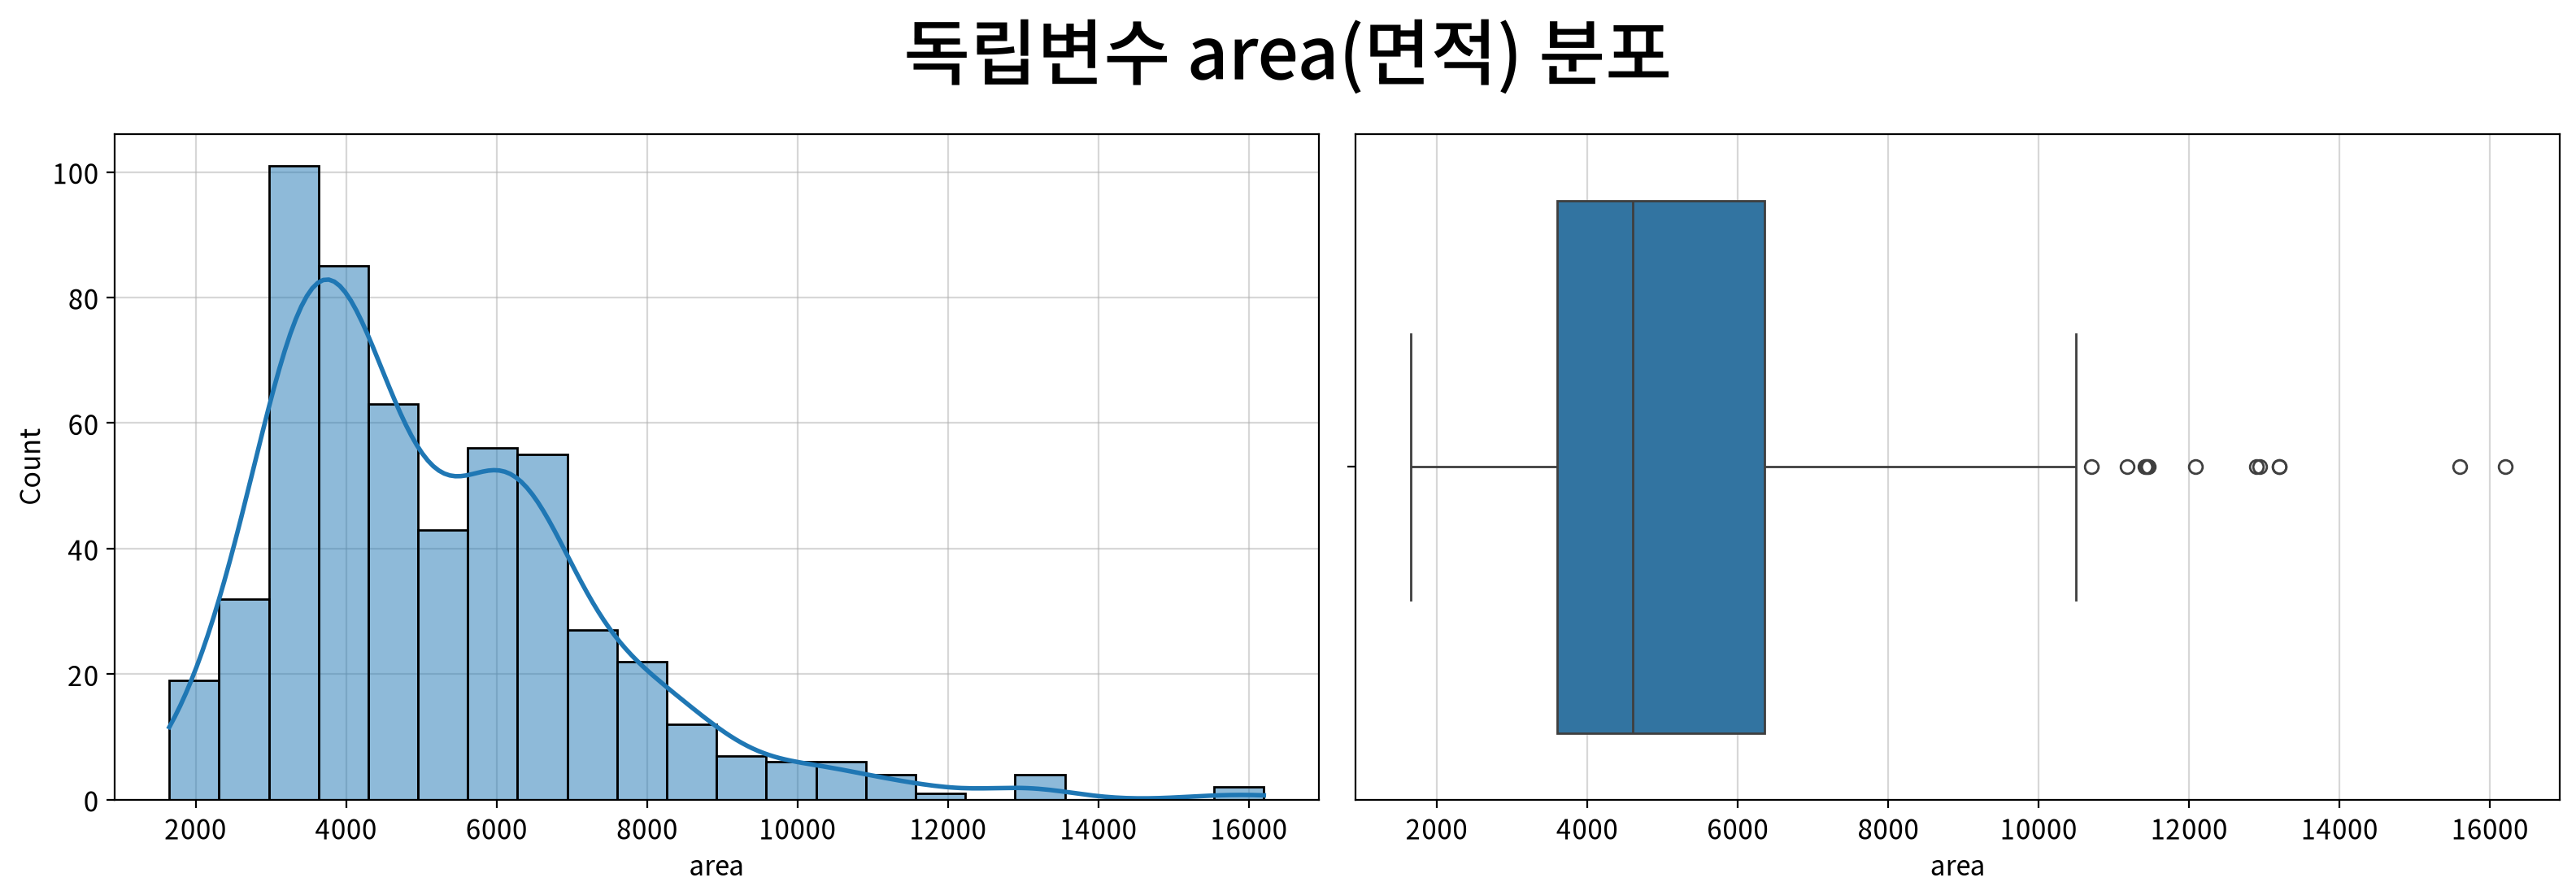

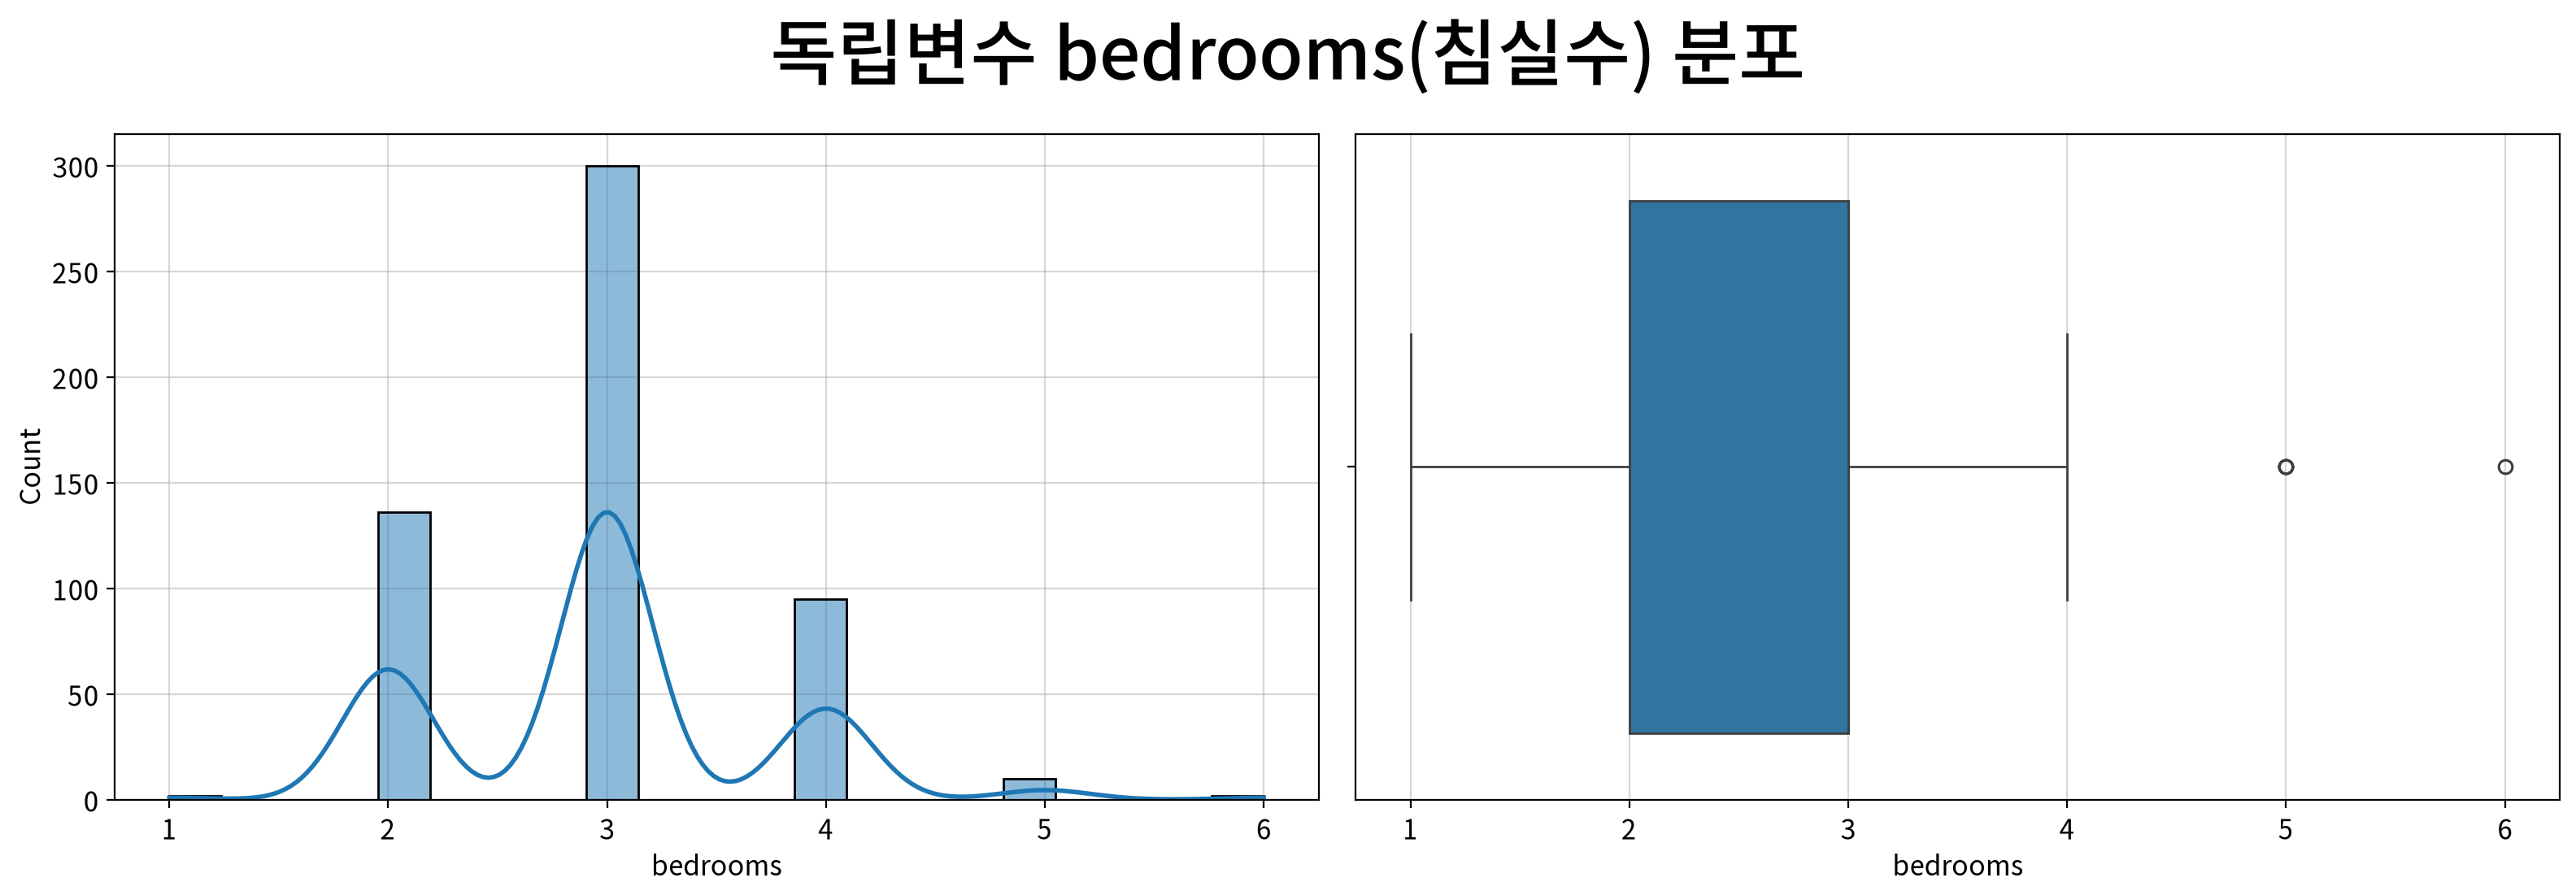

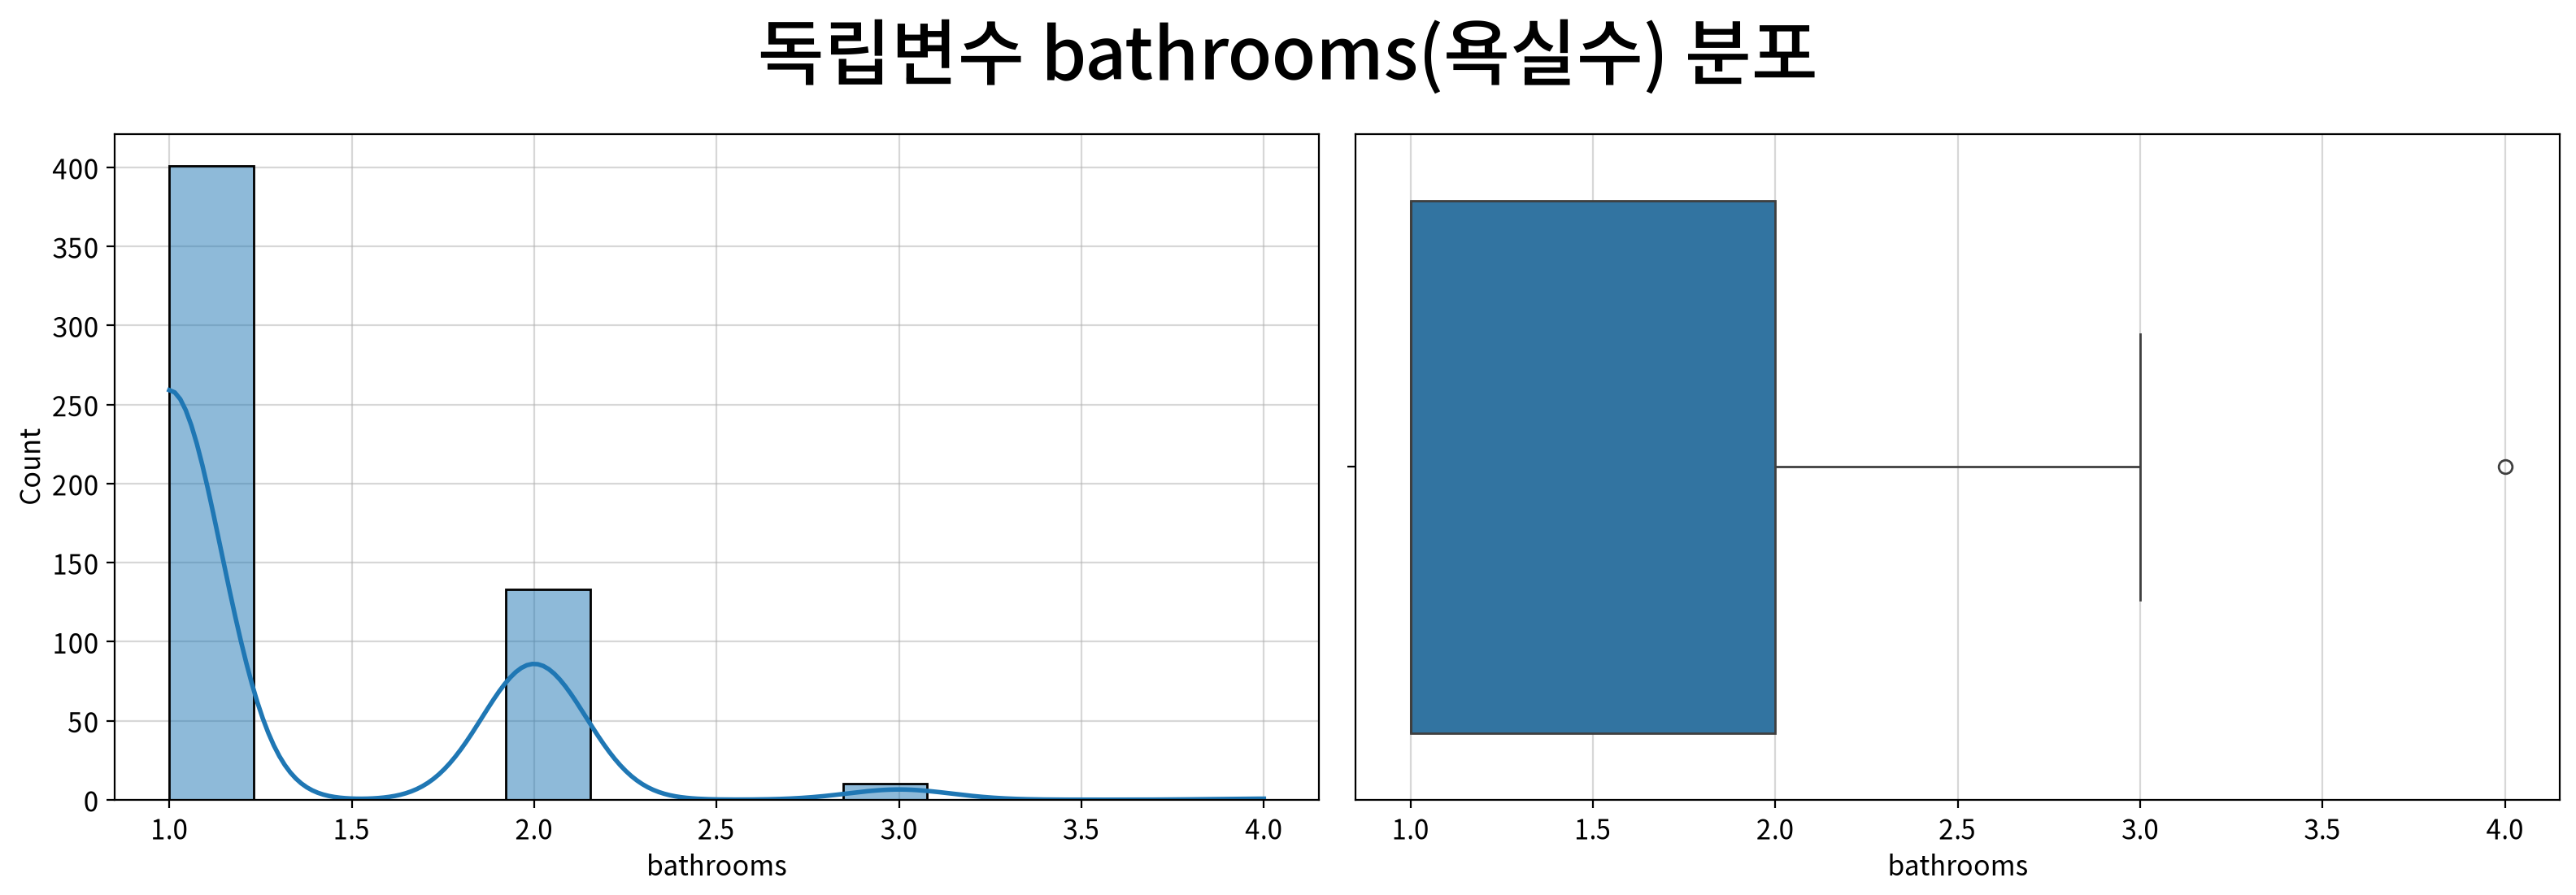

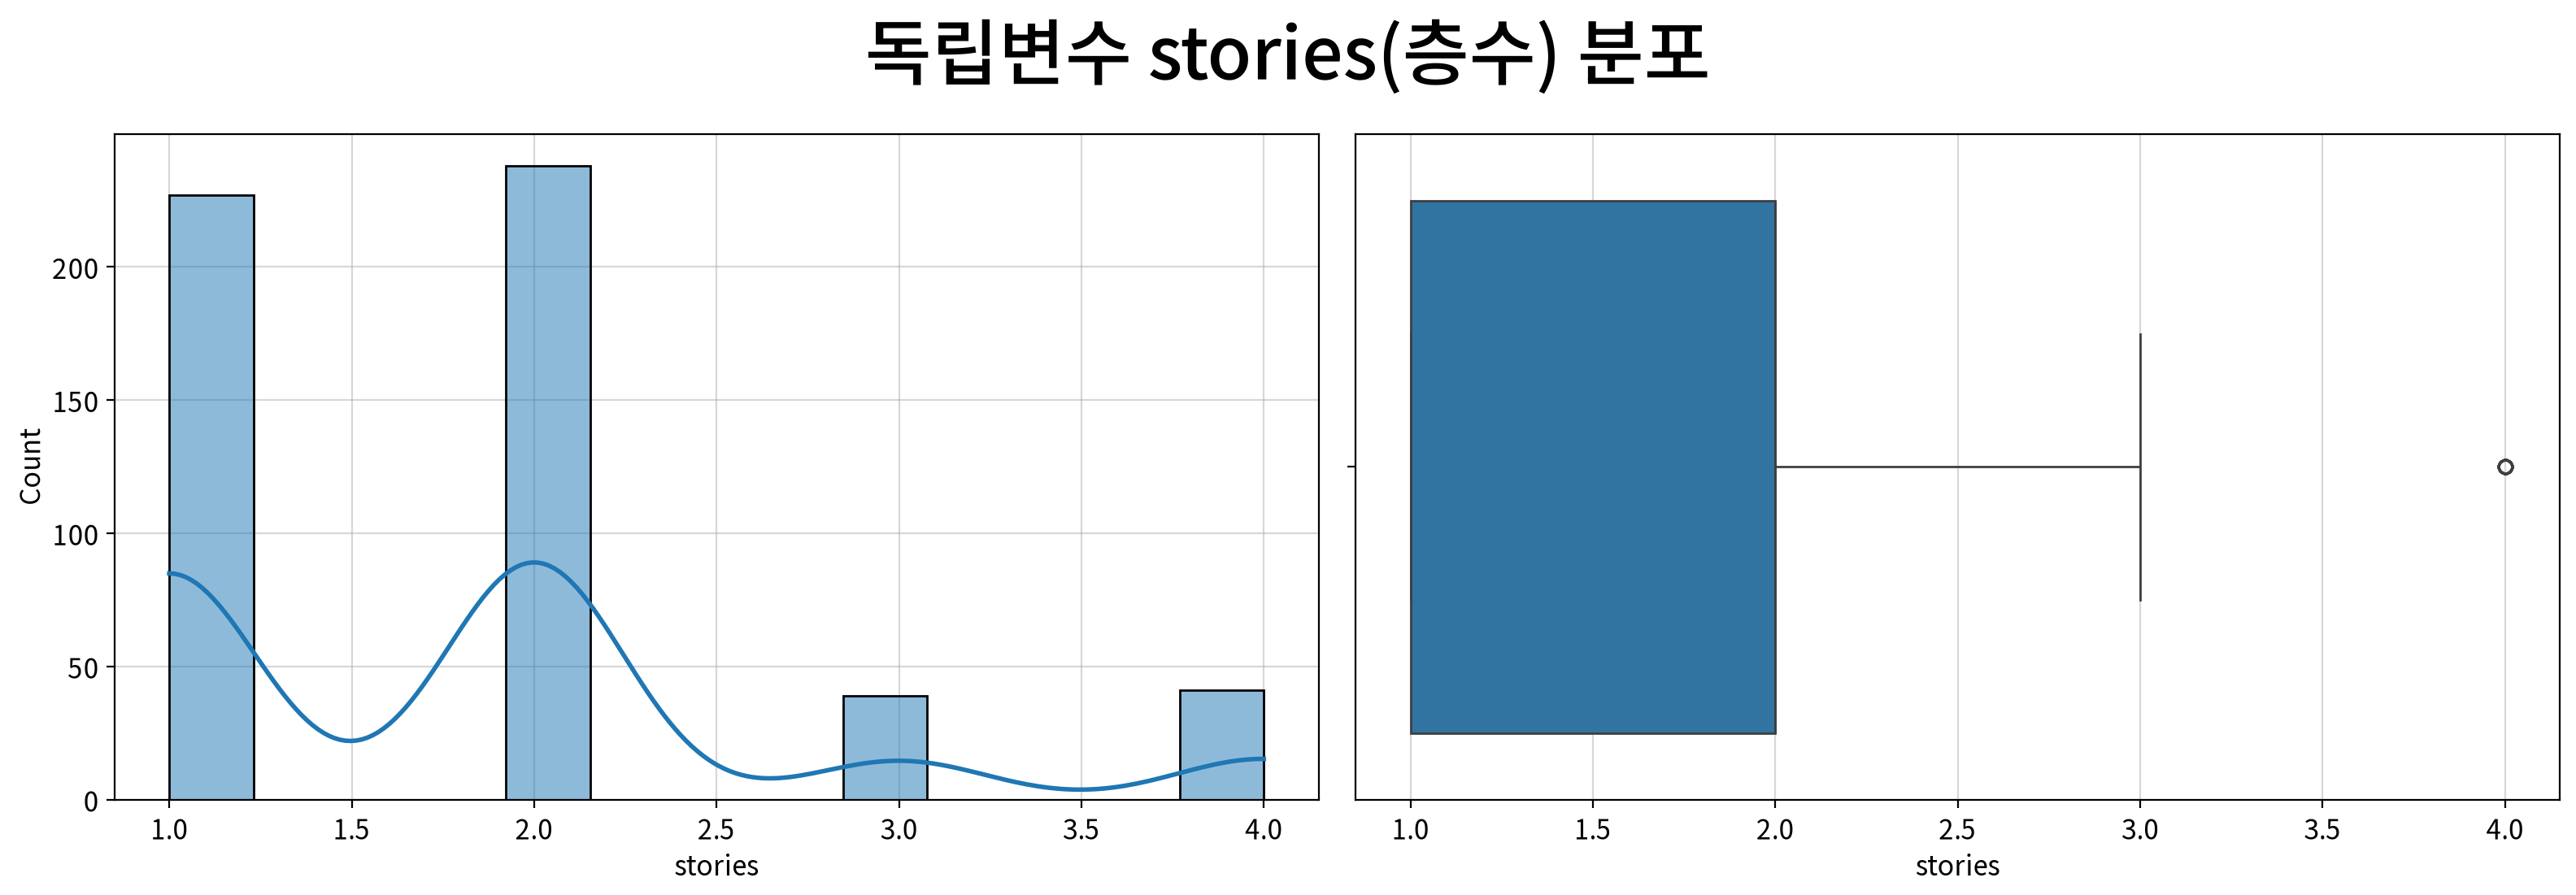

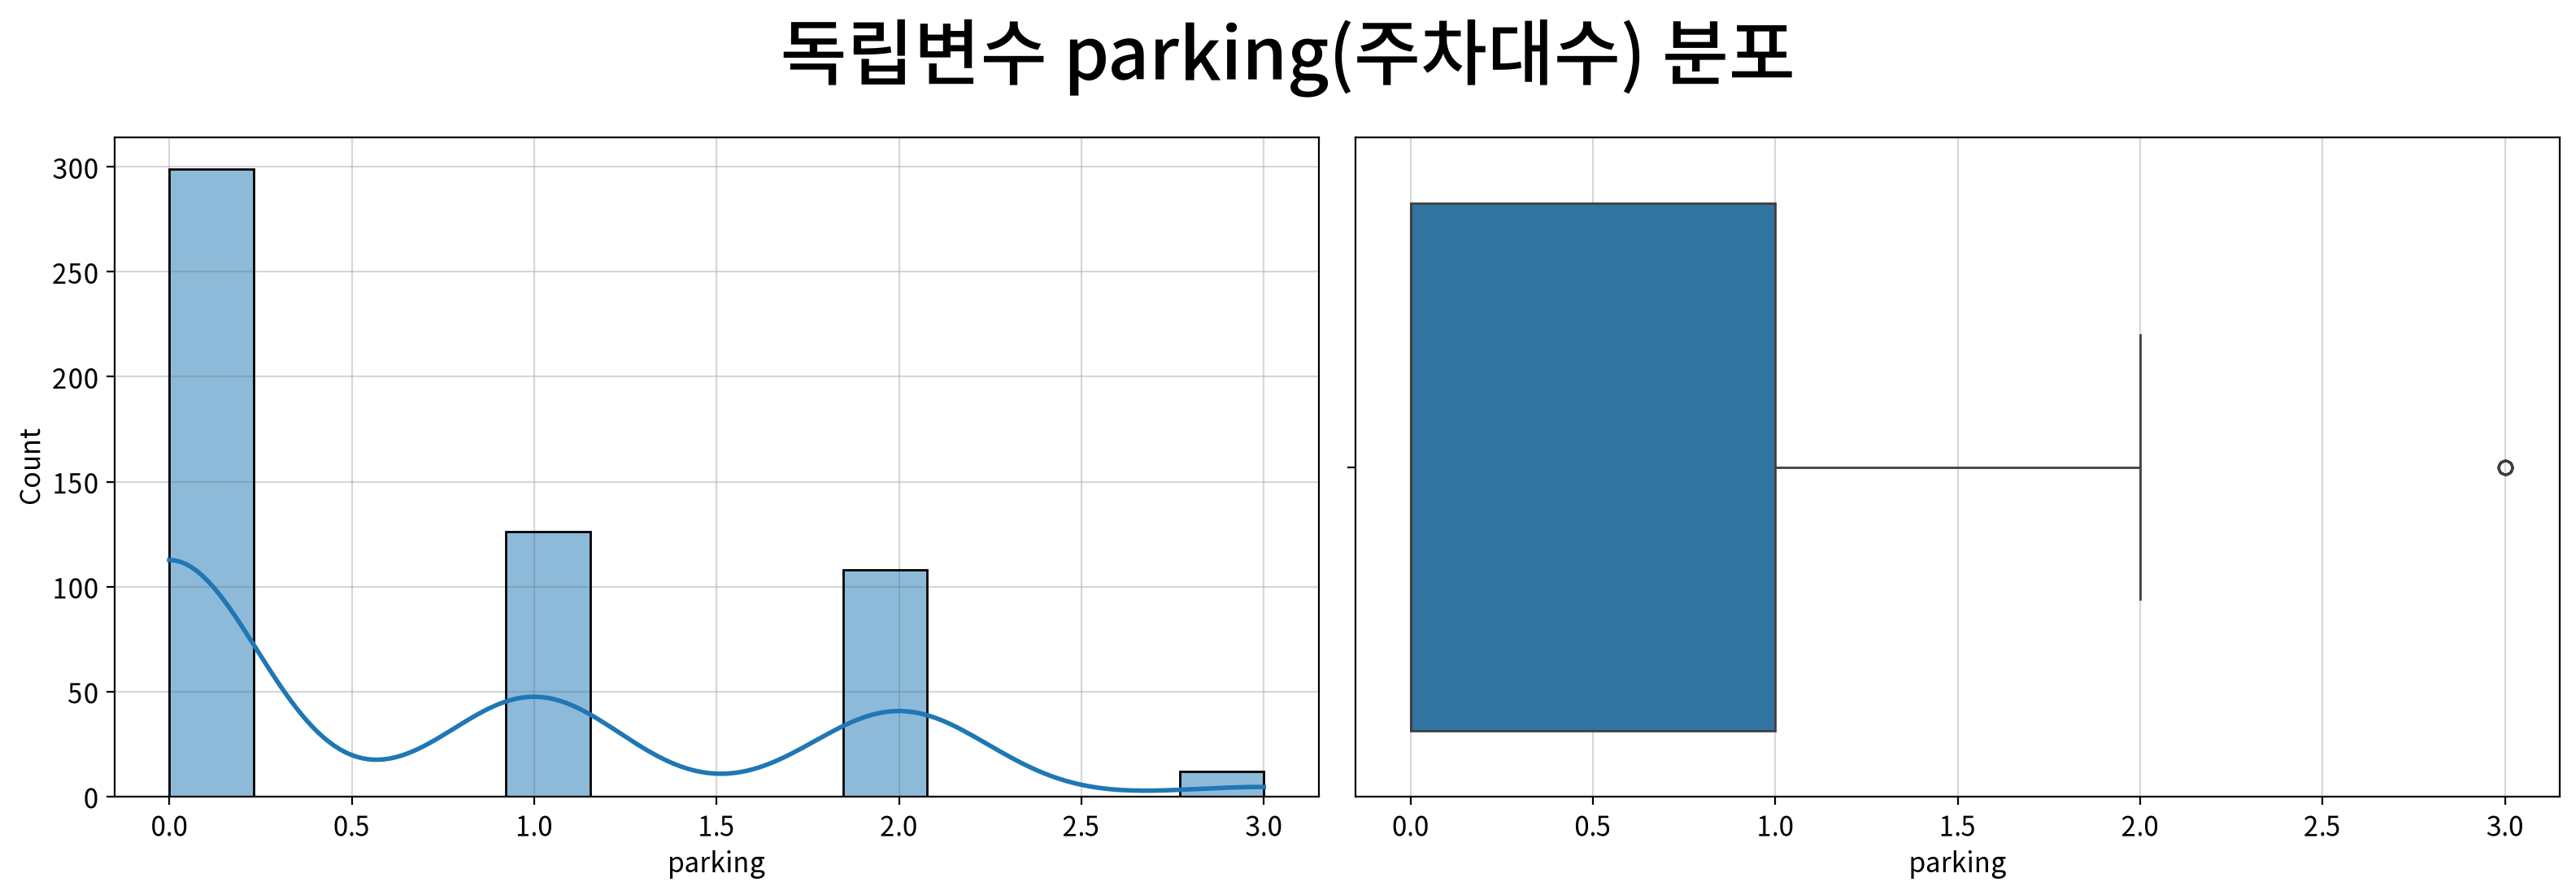

In [12]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=800, height=560,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

### (3) 명목형 독립변수 분포

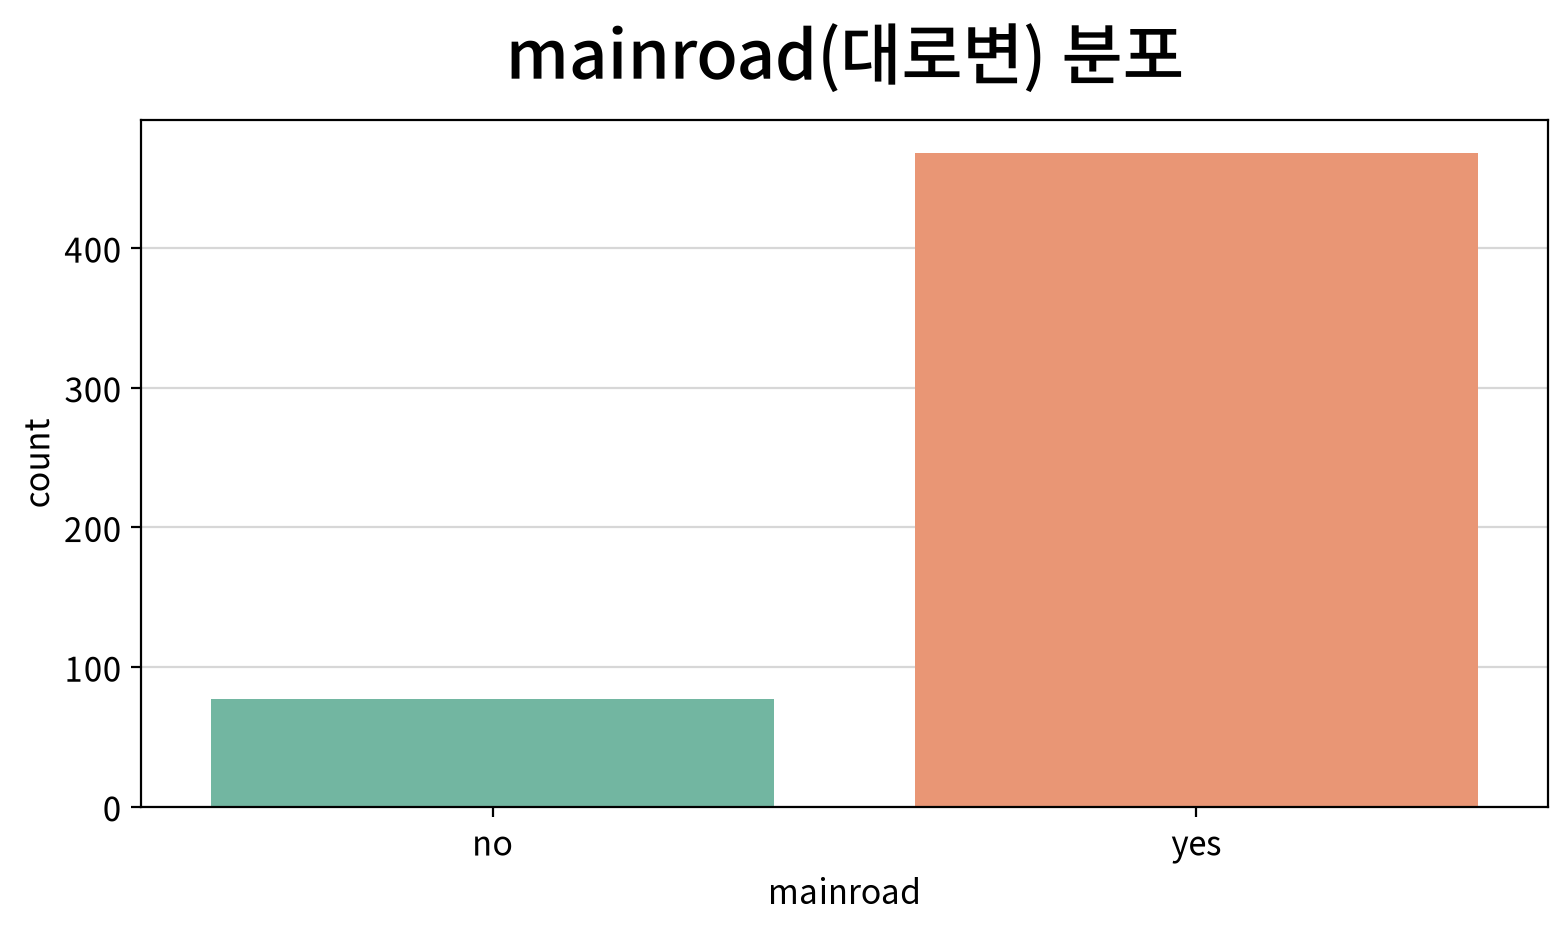

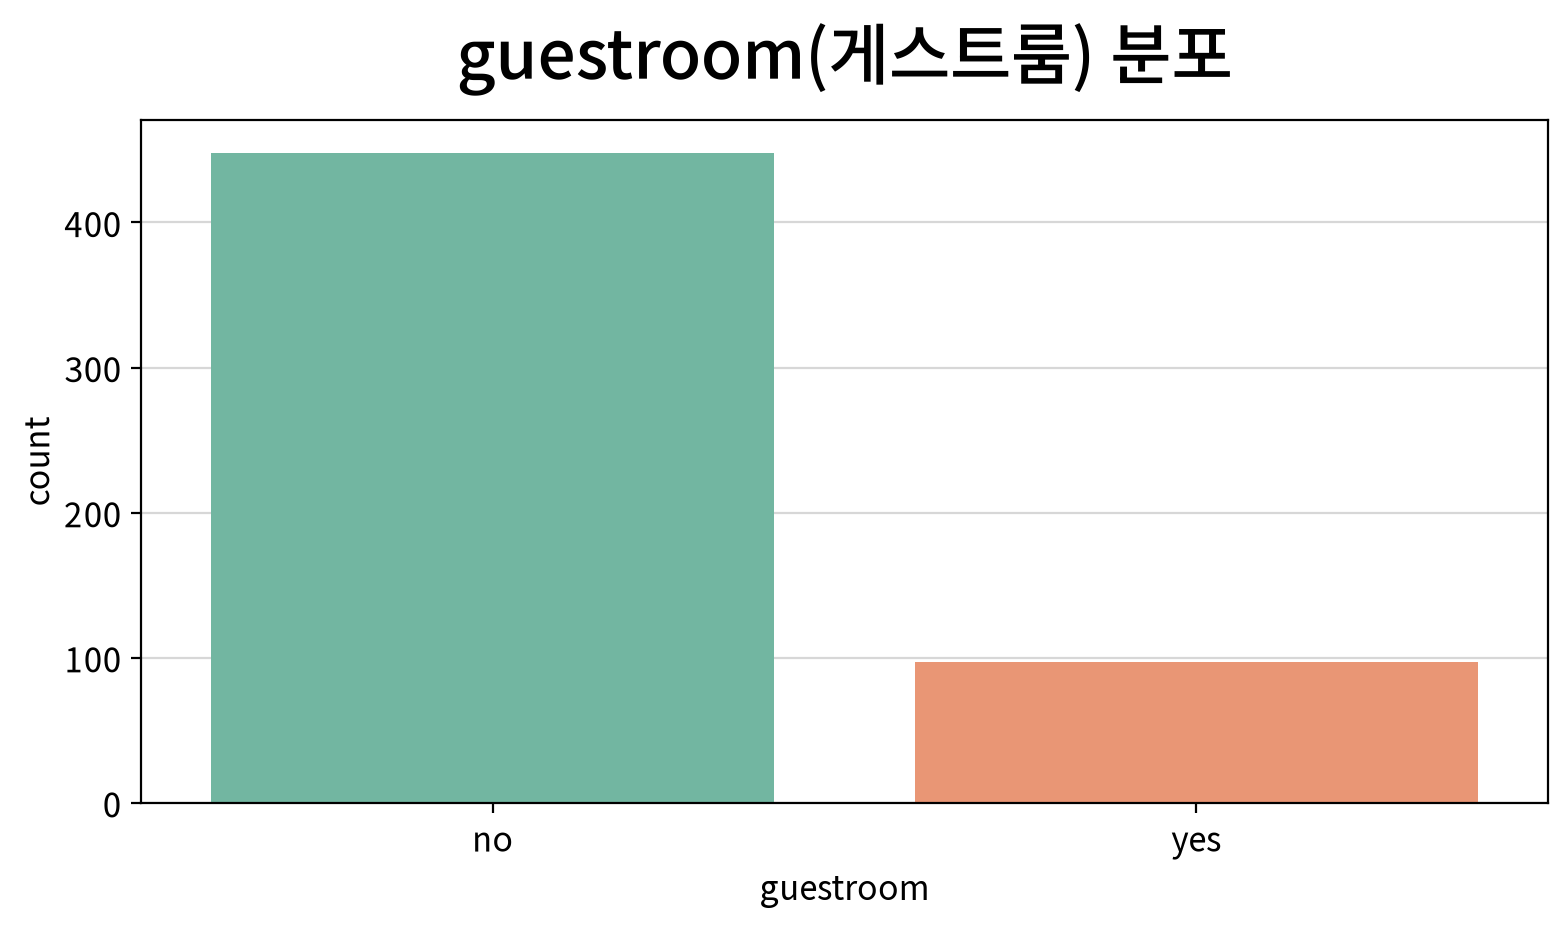

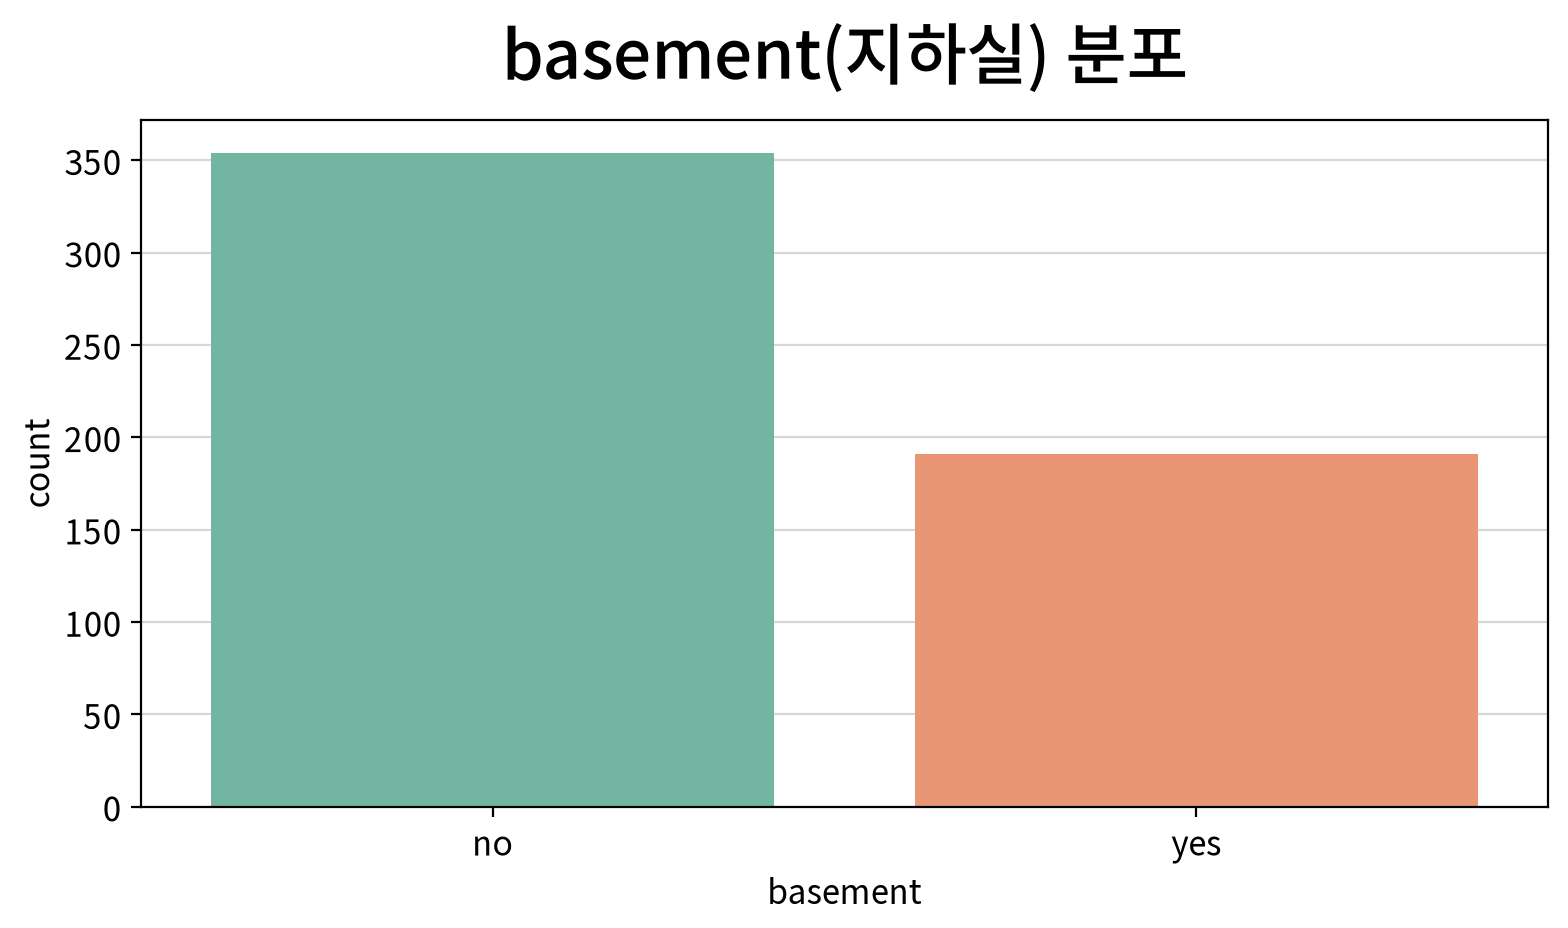

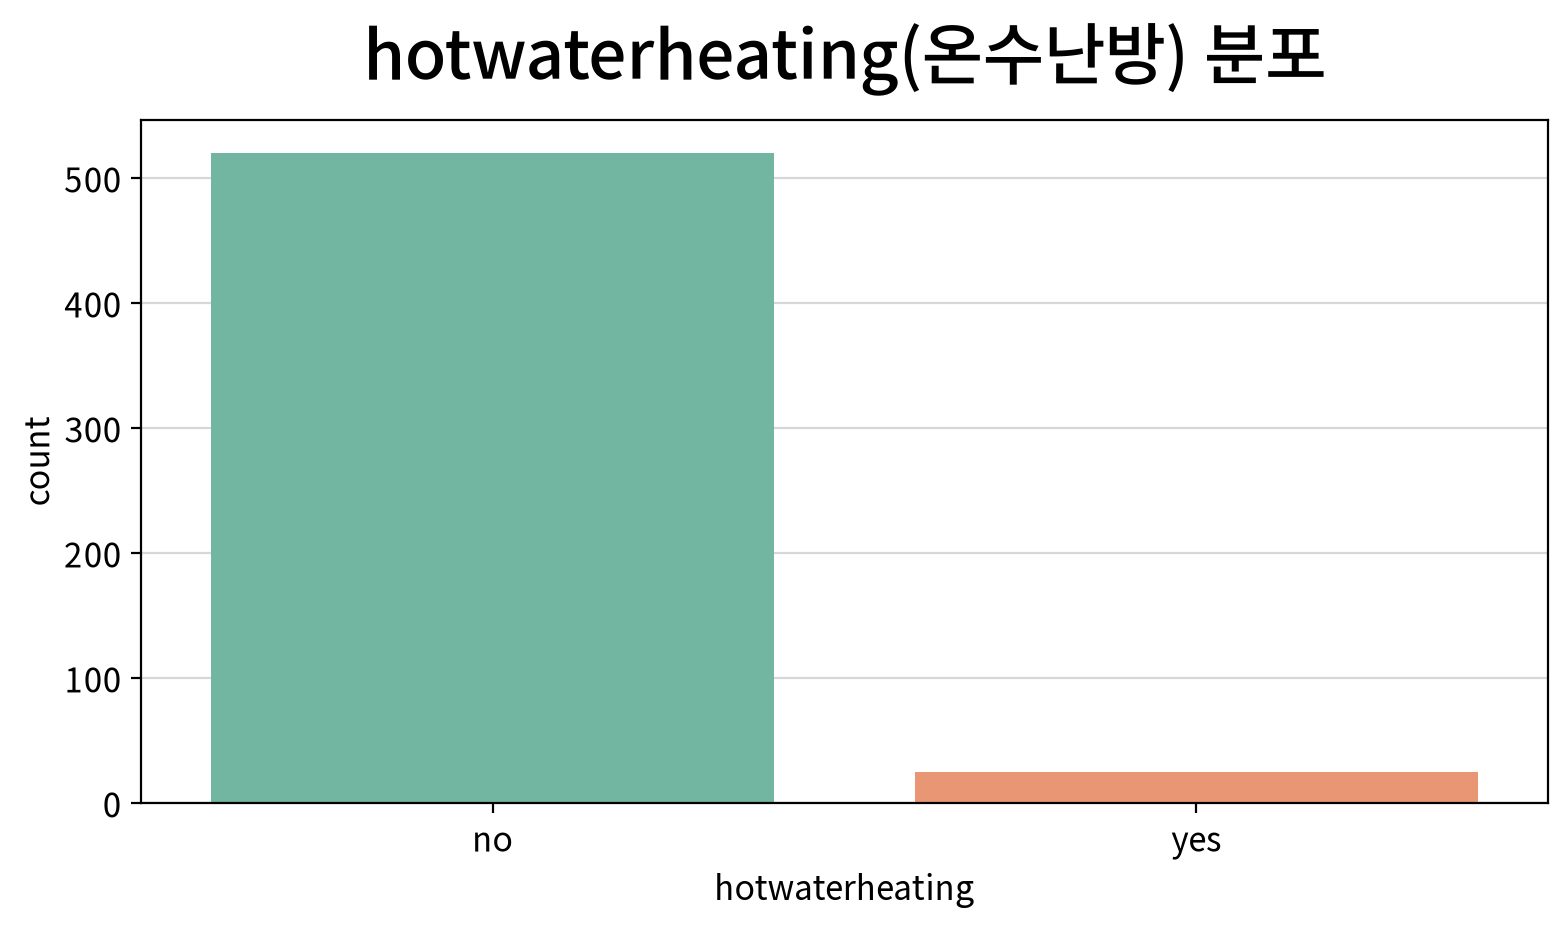

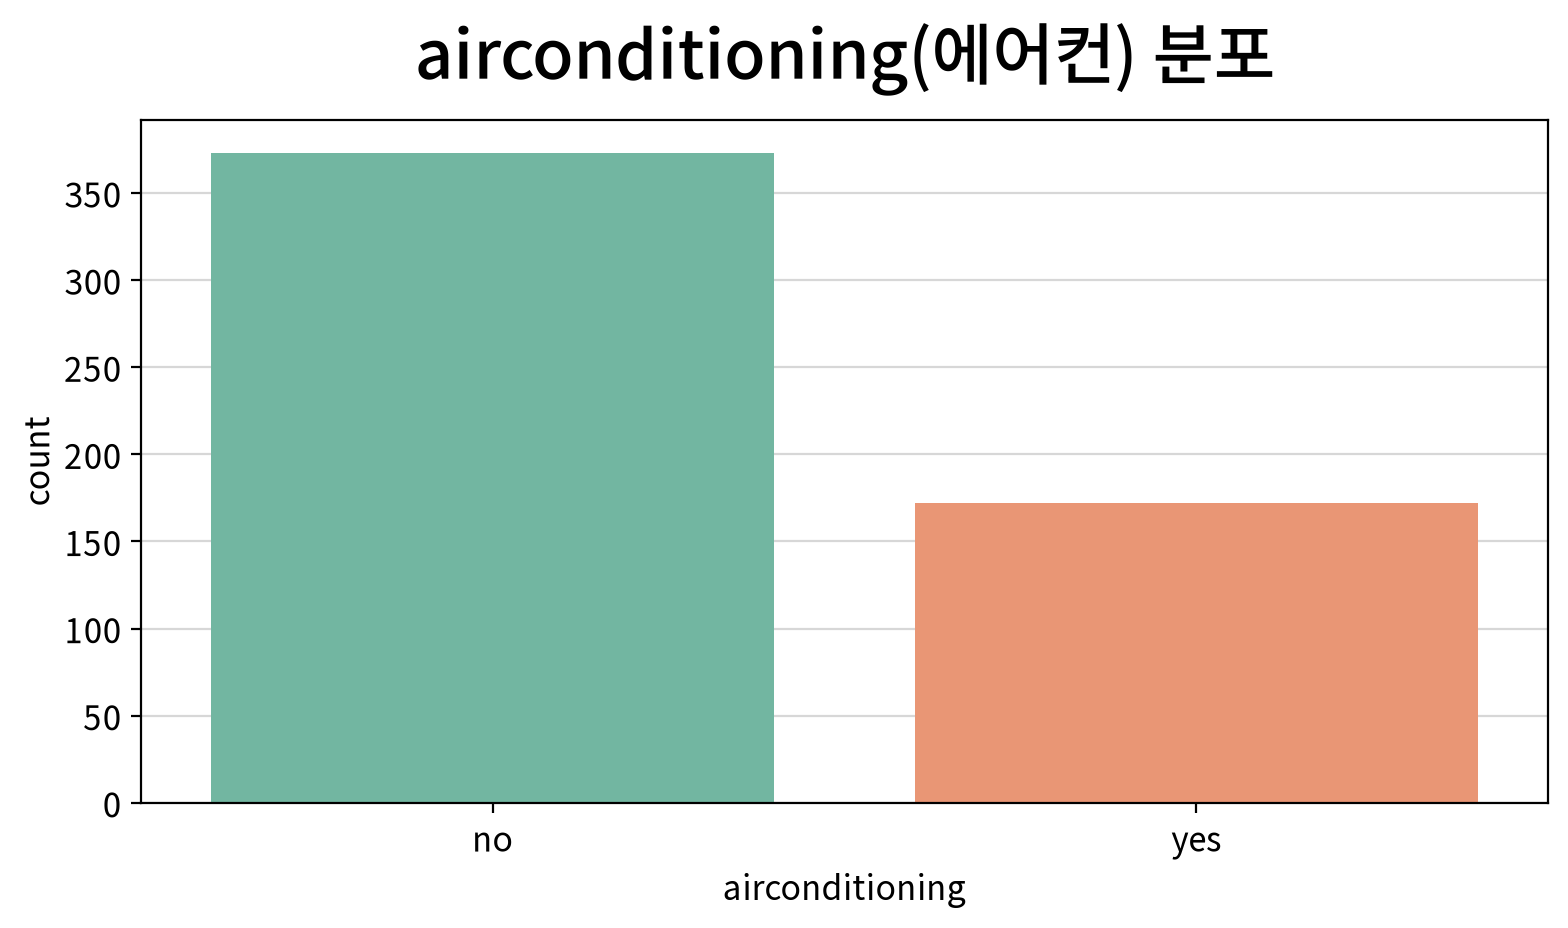

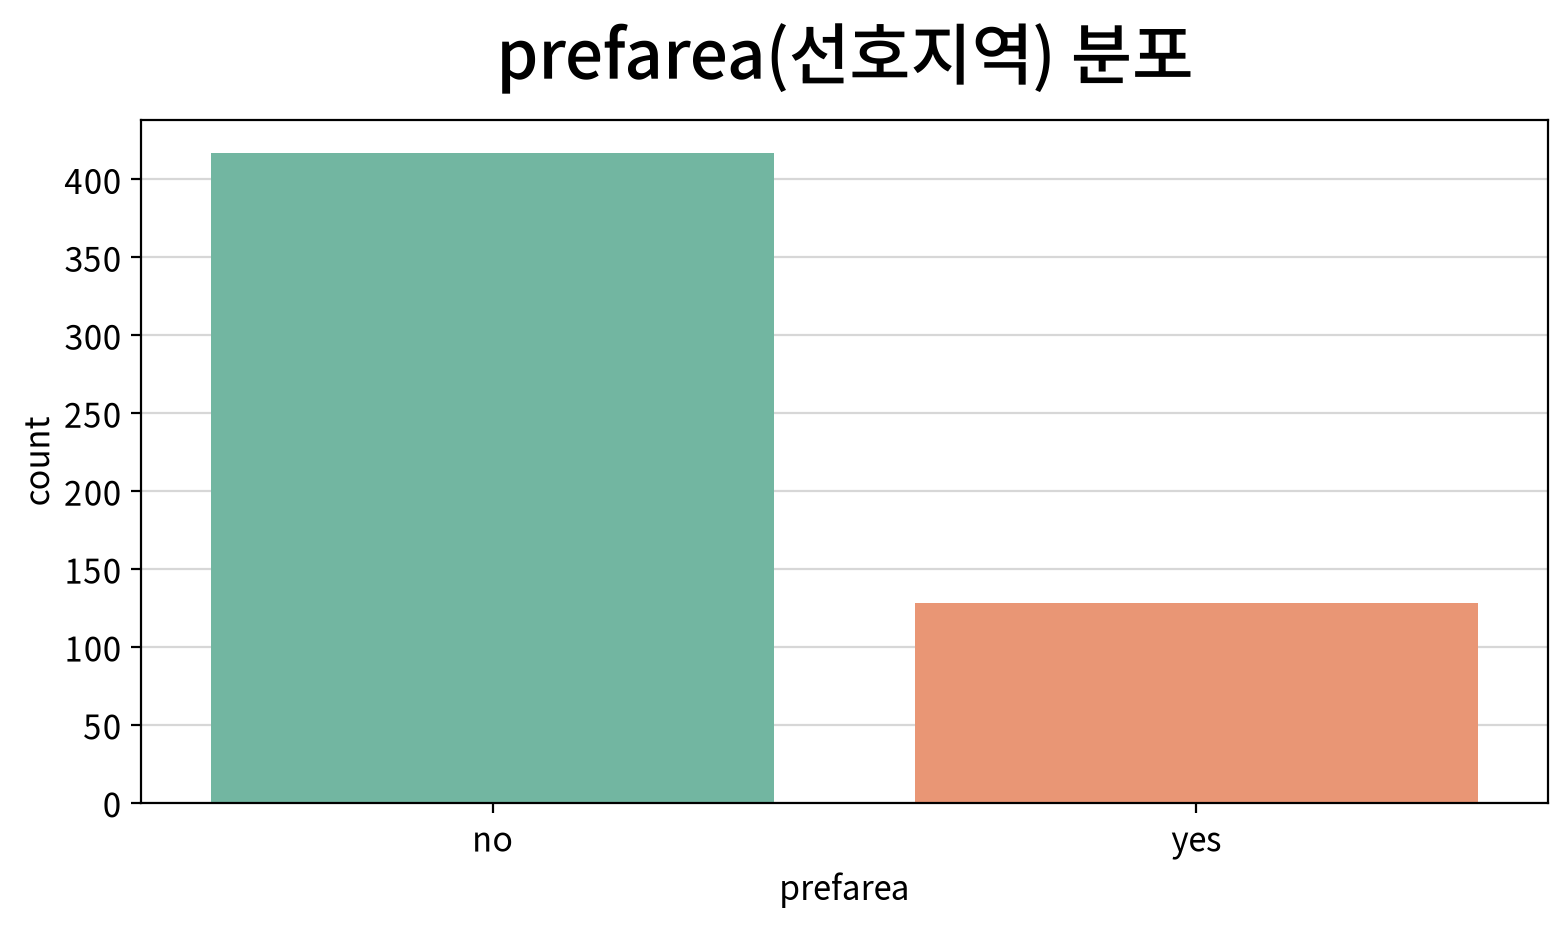

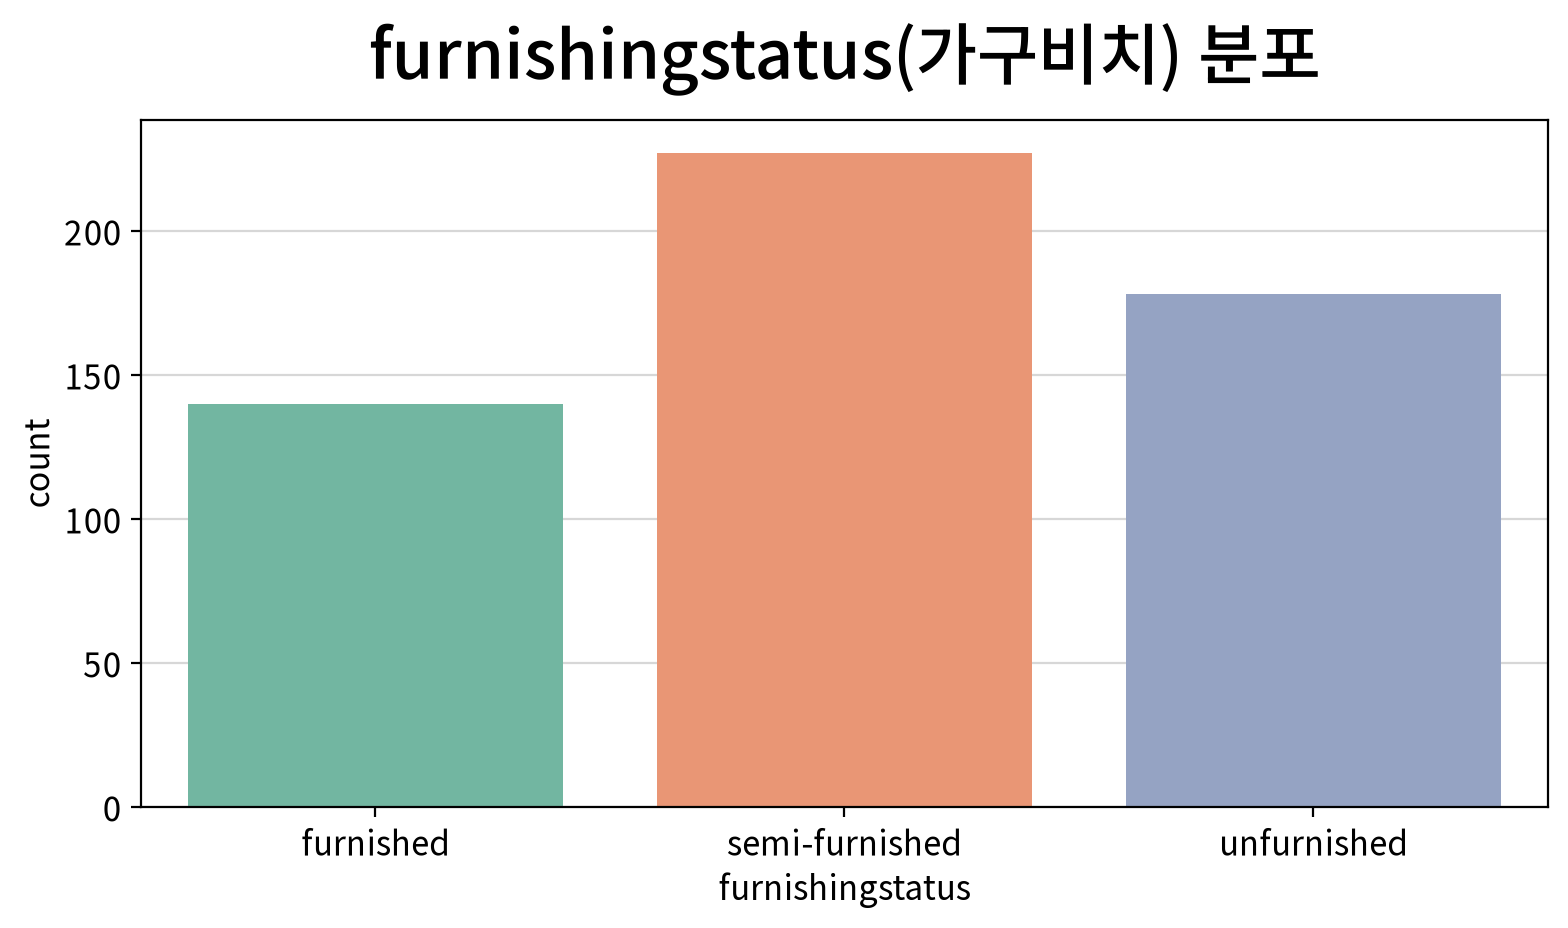

In [13]:
for n in nominal_cols:
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", width=800, height=480,
                      title=f"{n}({column_means[n]}) 분포")

> 💡 **인사이트 — 단변량**
>
> - **종속변수** `price`는 우편향(왜도 1.21)이고, 소수의 고가 주택이 오른쪽 꼬리를 만든다.
> - 그래프와 기술통계를 함께 보면, 모델 투입 전에 처리를 검토할 변수는 다음과 같다.
>
> | 변수 | 그래프 모양 | 이상치 비율 | 처리 방향 |
> |---|---|---|---|
> | `price` | 오른쪽 꼬리가 긴 우편향 (왜도 1.21) | 2.8% (상단) | **log** |
> | `area` | 오른쪽 꼬리가 긴 우편향 (왜도 1.32) | 2.2% (상단) | **log** |
> | `bedrooms` | 3개가 가장 많은 **이산형** (1~6개, 왜도 0.50) | 2.2% (상단) | 그대로 (변환 불필요) |
> | `bathrooms` | 1개가 대부분인 **이산형** (1~4개, 왜도 1.59) | 0.2% (상단) | **log** |
> | `stories` | 1~2층이 대부분인 **이산형** (1~4층, 왜도 1.08) | 7.5% (상단) | **log** |
> | `parking` | 0대가 가장 많은 **이산형** (0~3대, 왜도 0.84) | 2.2% (상단) | 그대로 (변환 불필요) |
>
> - 연속형 독립변수 5개 중 4개가 값이 몇 가지뿐인 **이산형**이다. 로그를 씌워도 막대의 간격만 바뀔 뿐 분포가 매끄러워지지 않으므로, 변환 효과는 PART 3에서 검증한다.
> - 옵션 보유율이 크게 다르다. `mainroad`(대로변)는 86%가 '있음'인 반면 **`hotwaterheating`(온수난방)은 4.6%(25채)** 뿐이다. 소수 집단의 비교는 검정력이 낮다는 점을 염두에 둔다.
> - `furnishingstatus`는 세 범주가 비교적 고르게 분포한다(완비 140 · 반 비치 227 · 미비치 178채).

## 2-2. 이변량 분석 — 각 독립변수가 가격을 설명하는가?

### (1) 연속형 × 연속형 : 상관분석

- 정규성 · 선형성 · 영향점을 점검해 **Pearson / Spearman을 자동 선택**한다.
- 채택 기준 : **유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)**

#### ▶︎ area(면적) → price

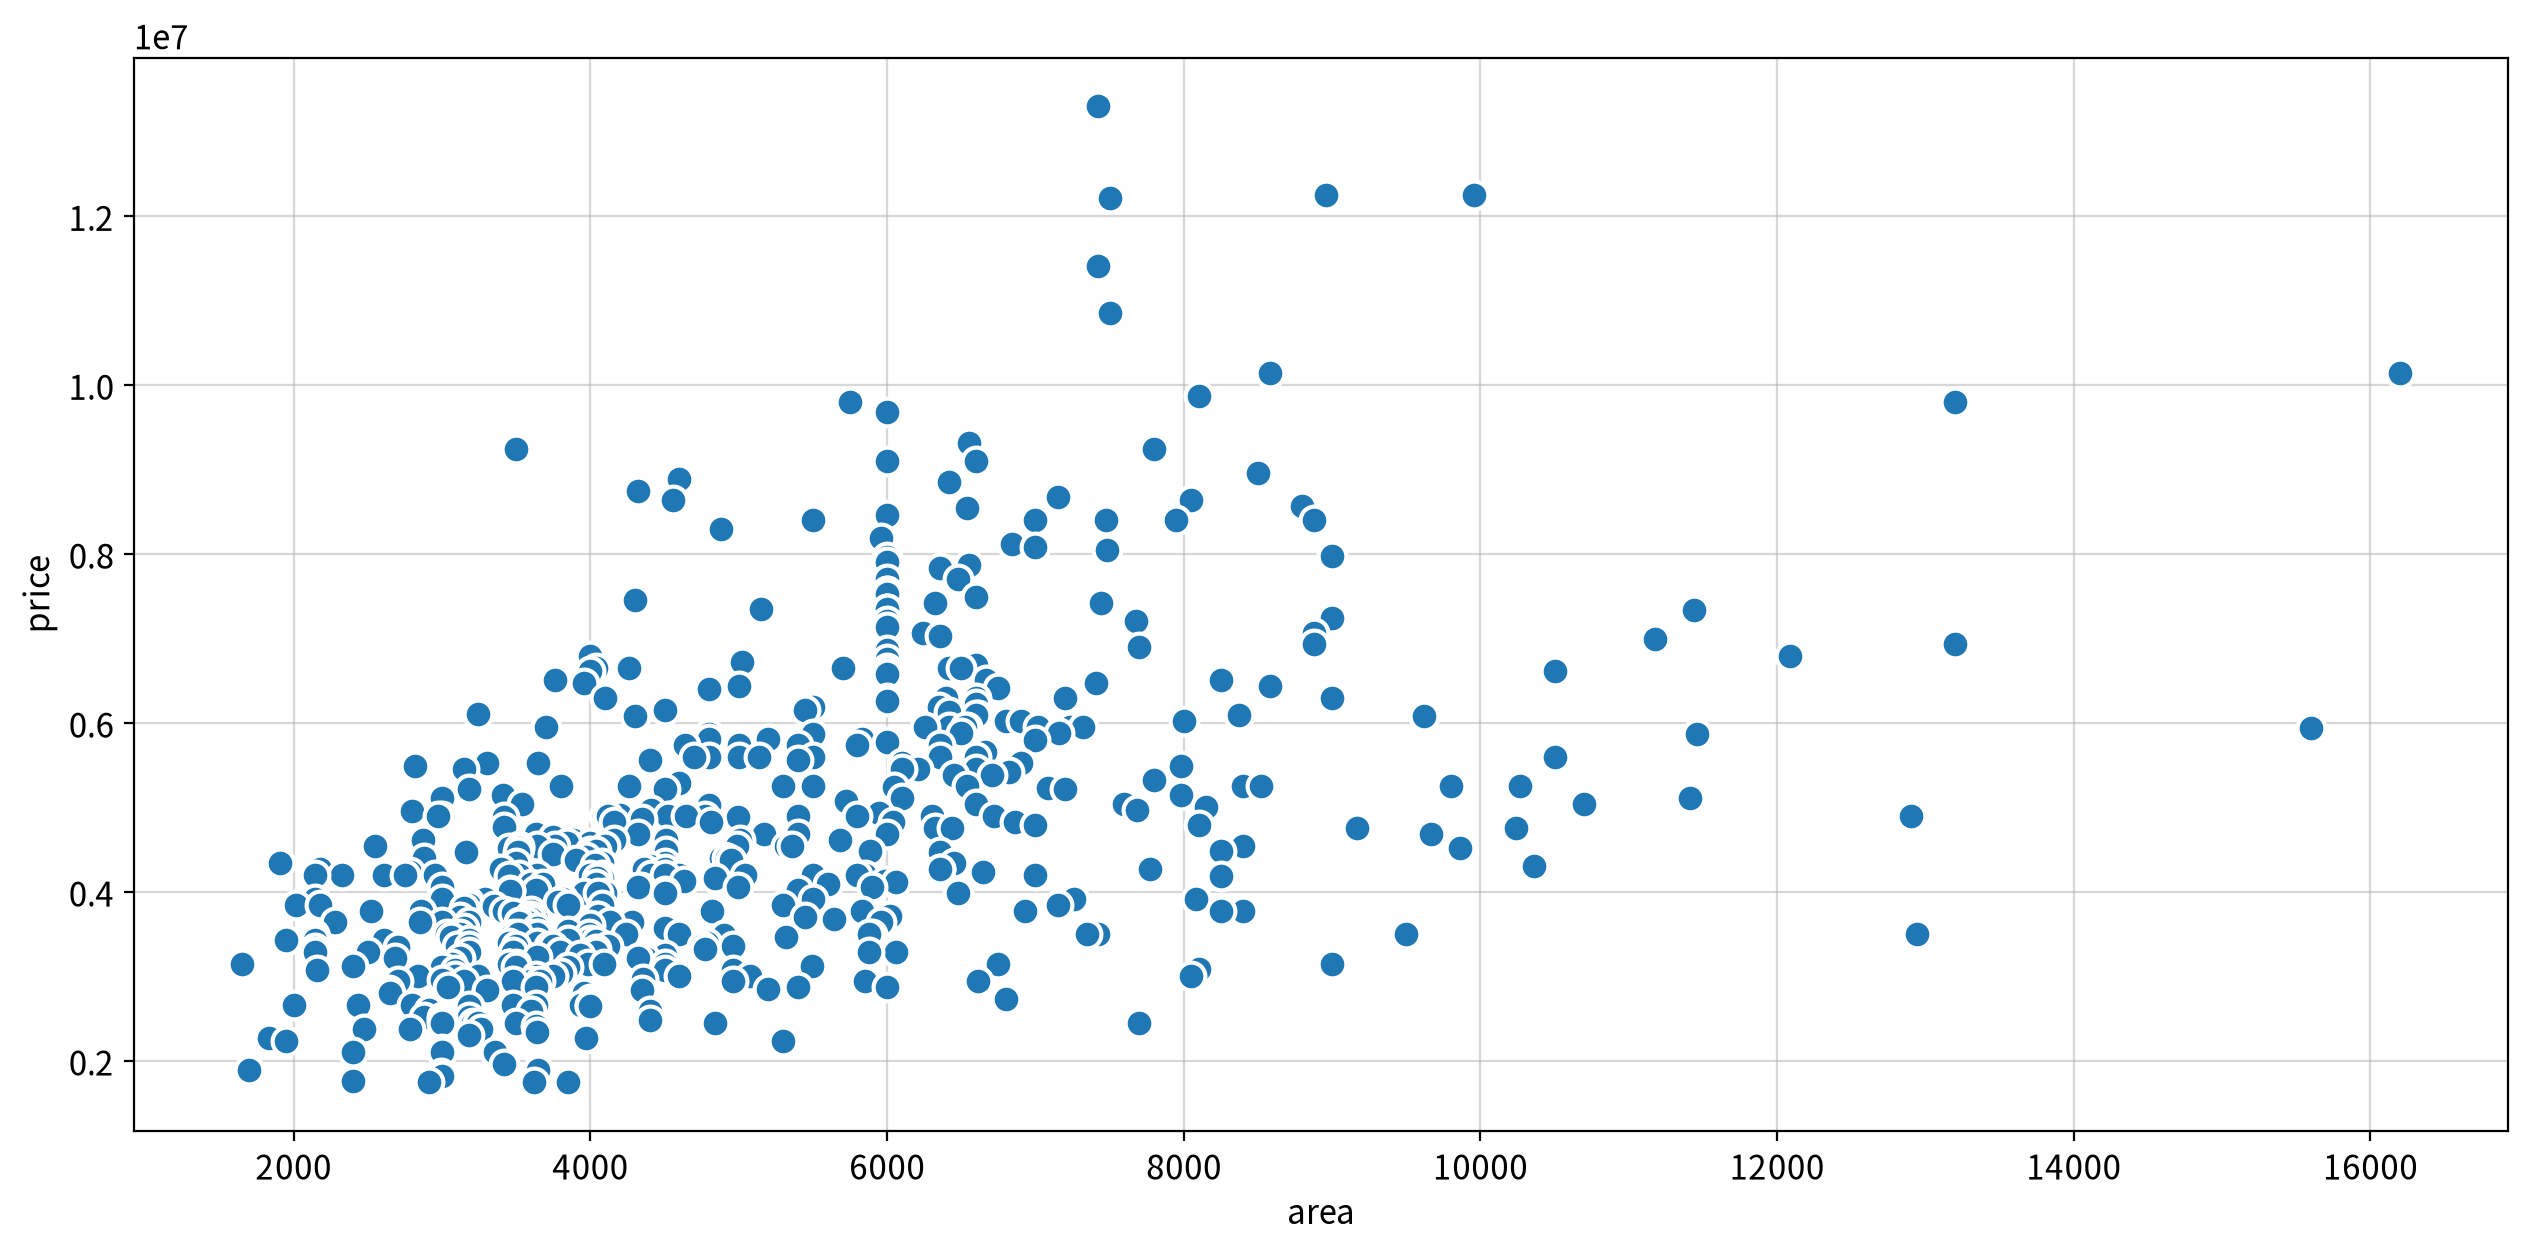

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
area,price,Spearman,0.603,0.000,Moderate,True,False,False,False,False,True


#### ▶︎ bedrooms(침실수) → price

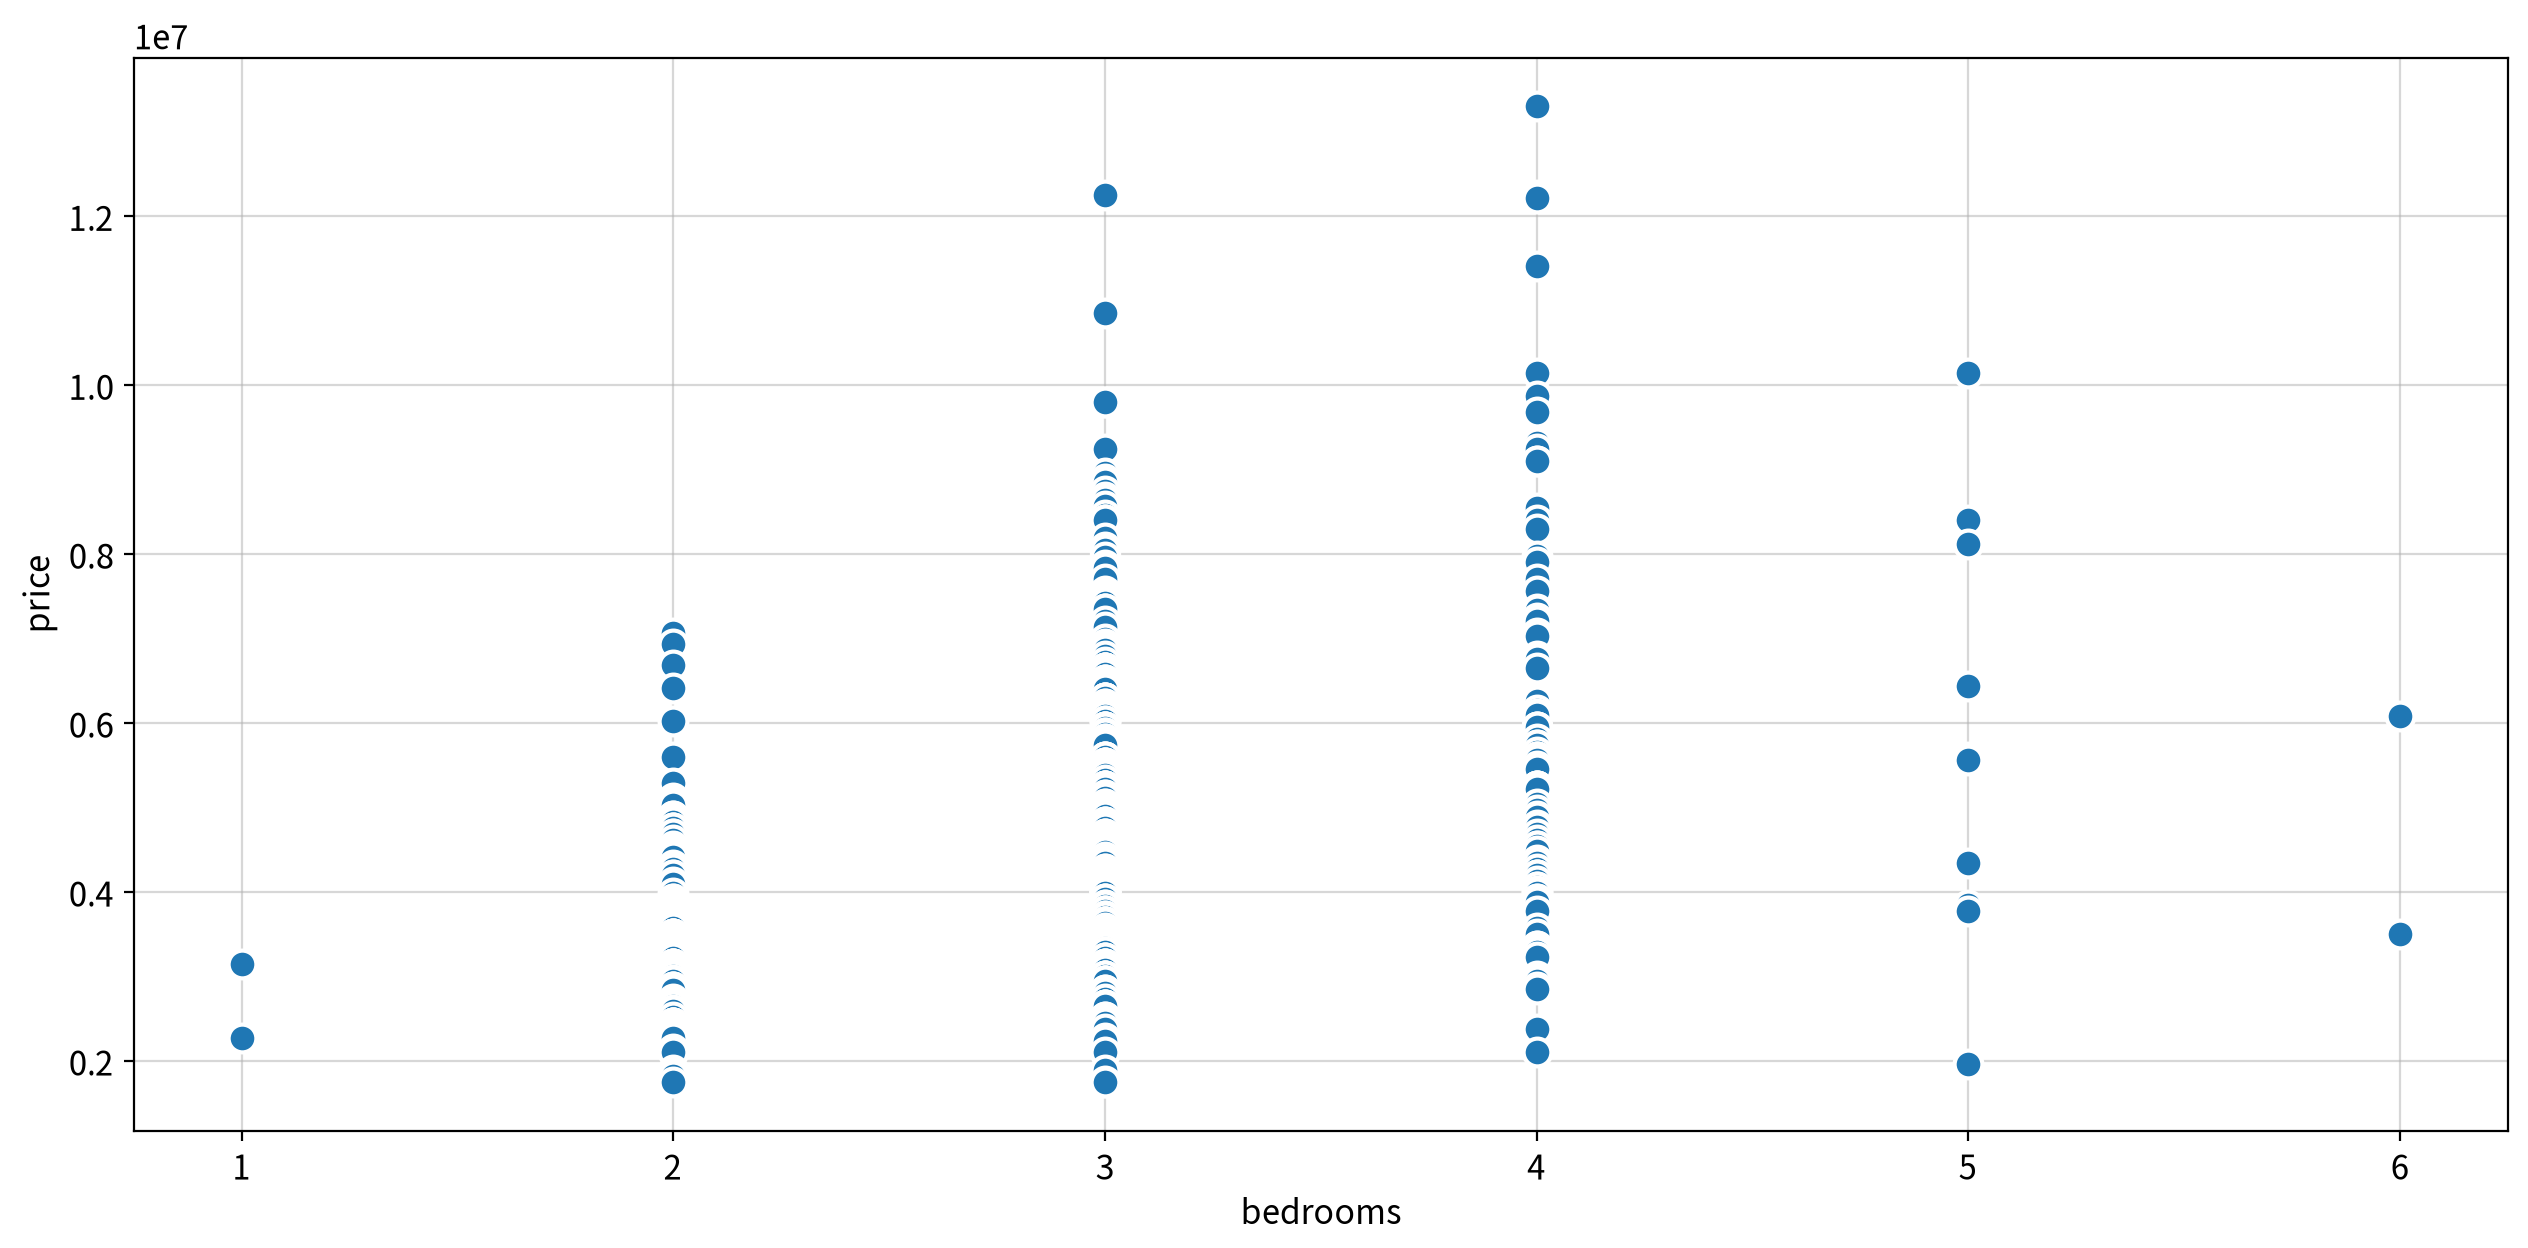

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
bedrooms,price,Spearman,0.391,0.000,Moderate,True,False,False,False,False,True


#### ▶︎ bathrooms(욕실수) → price

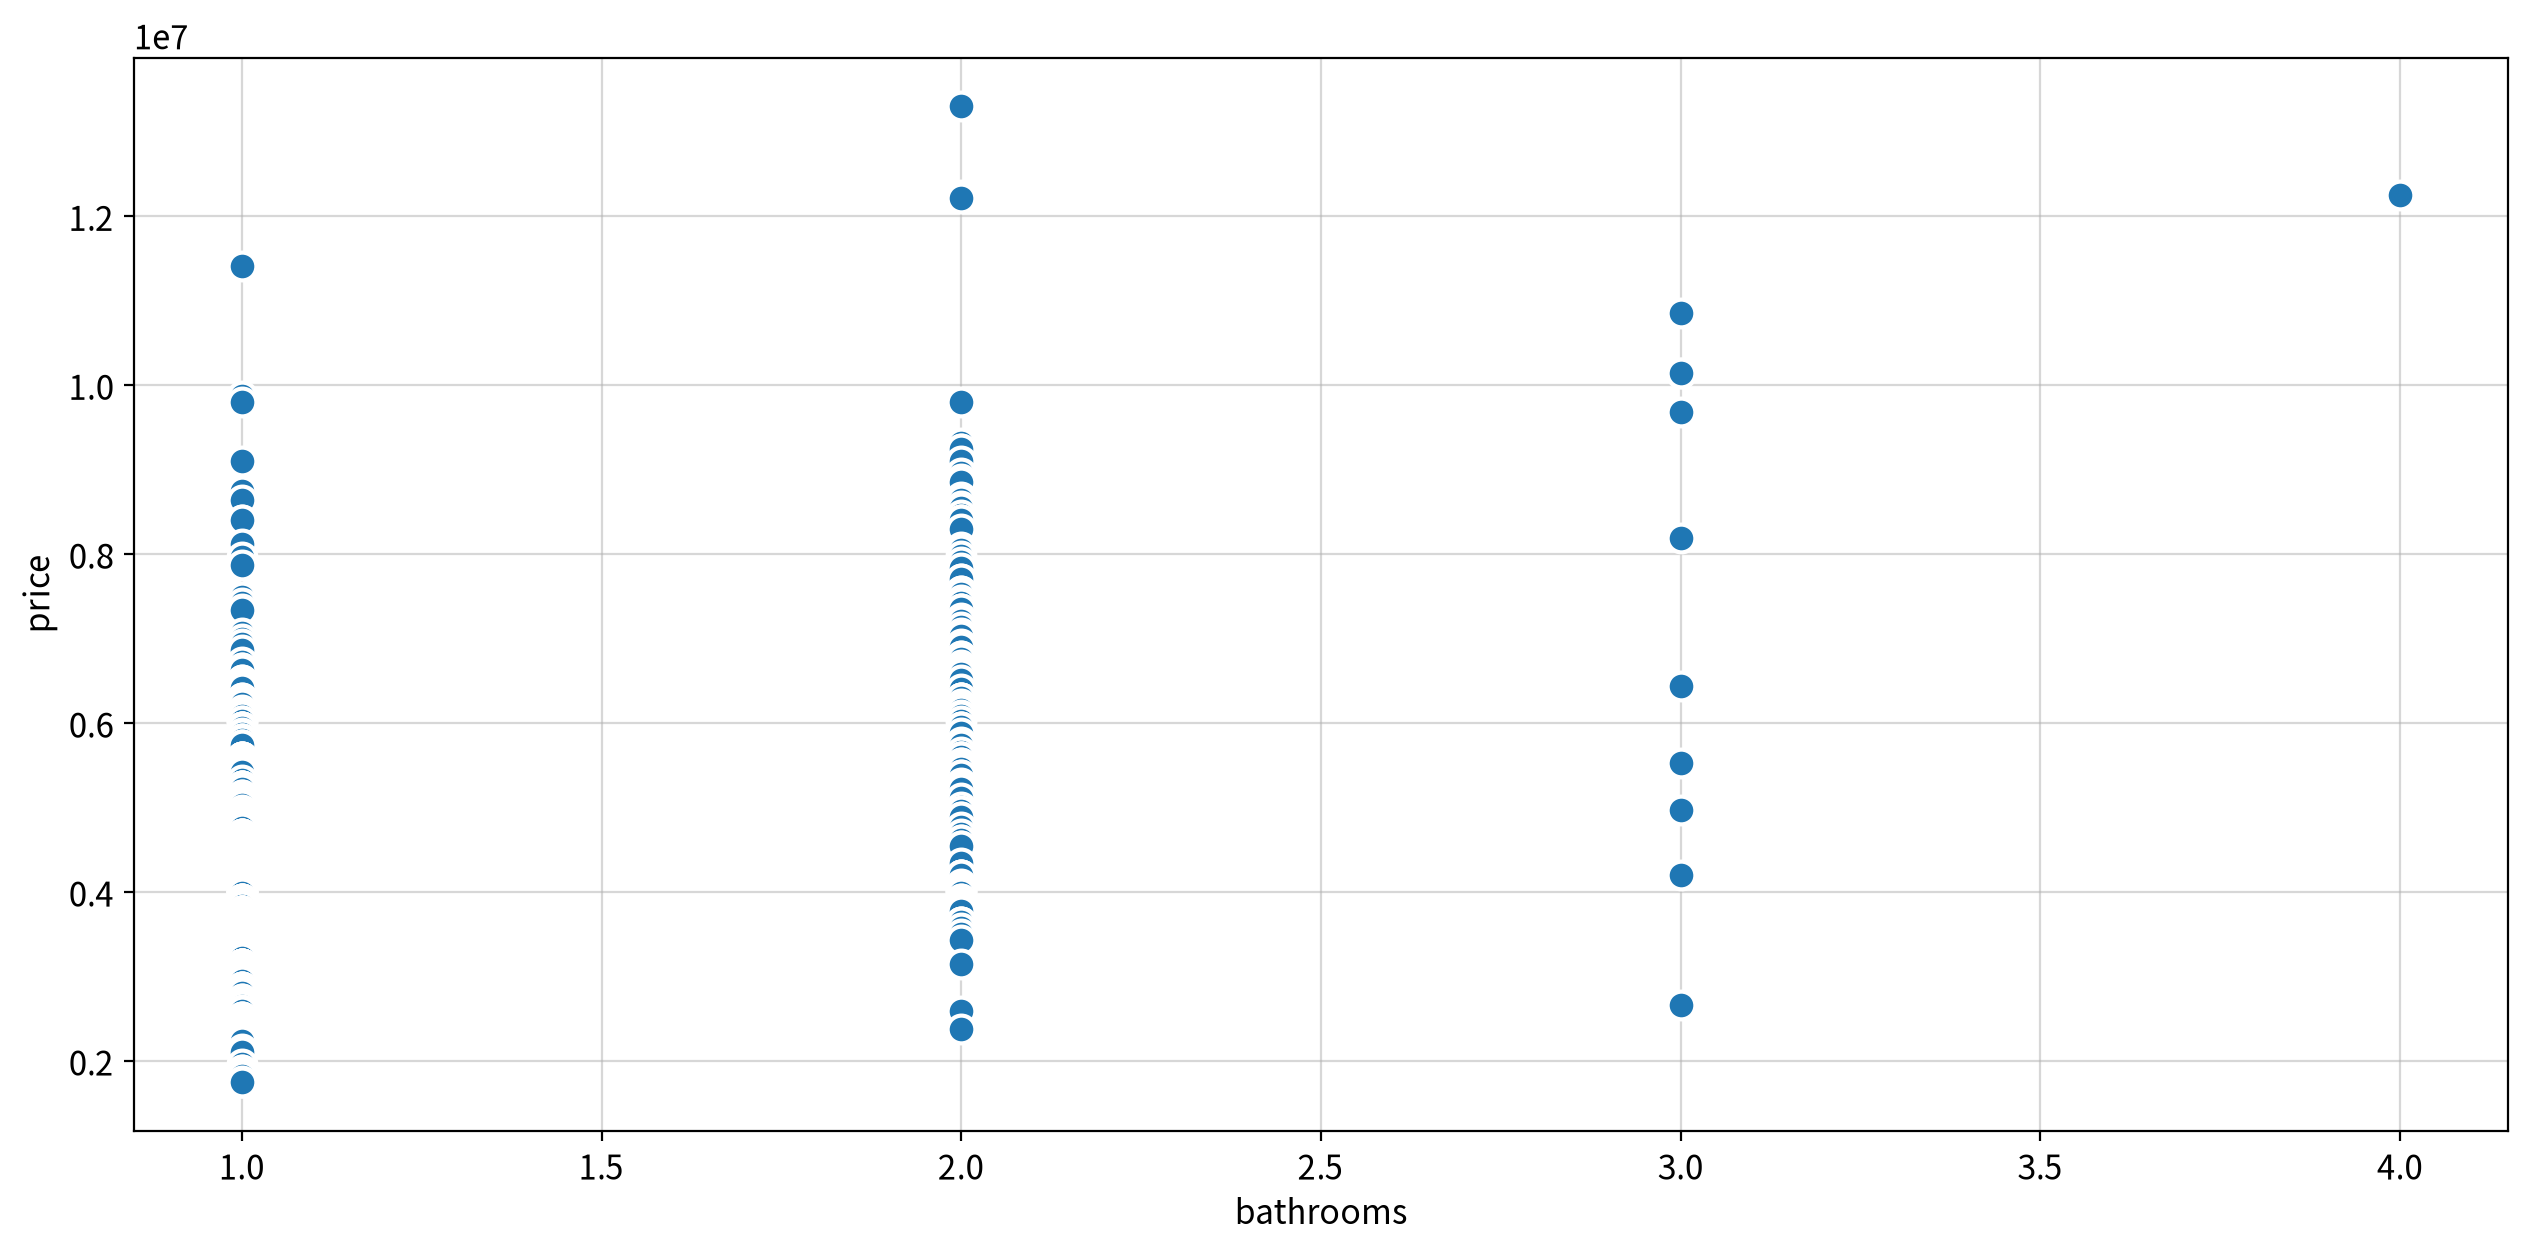

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
bathrooms,price,Spearman,0.480,0.000,Moderate,True,False,False,True,False,True


#### ▶︎ stories(층수) → price

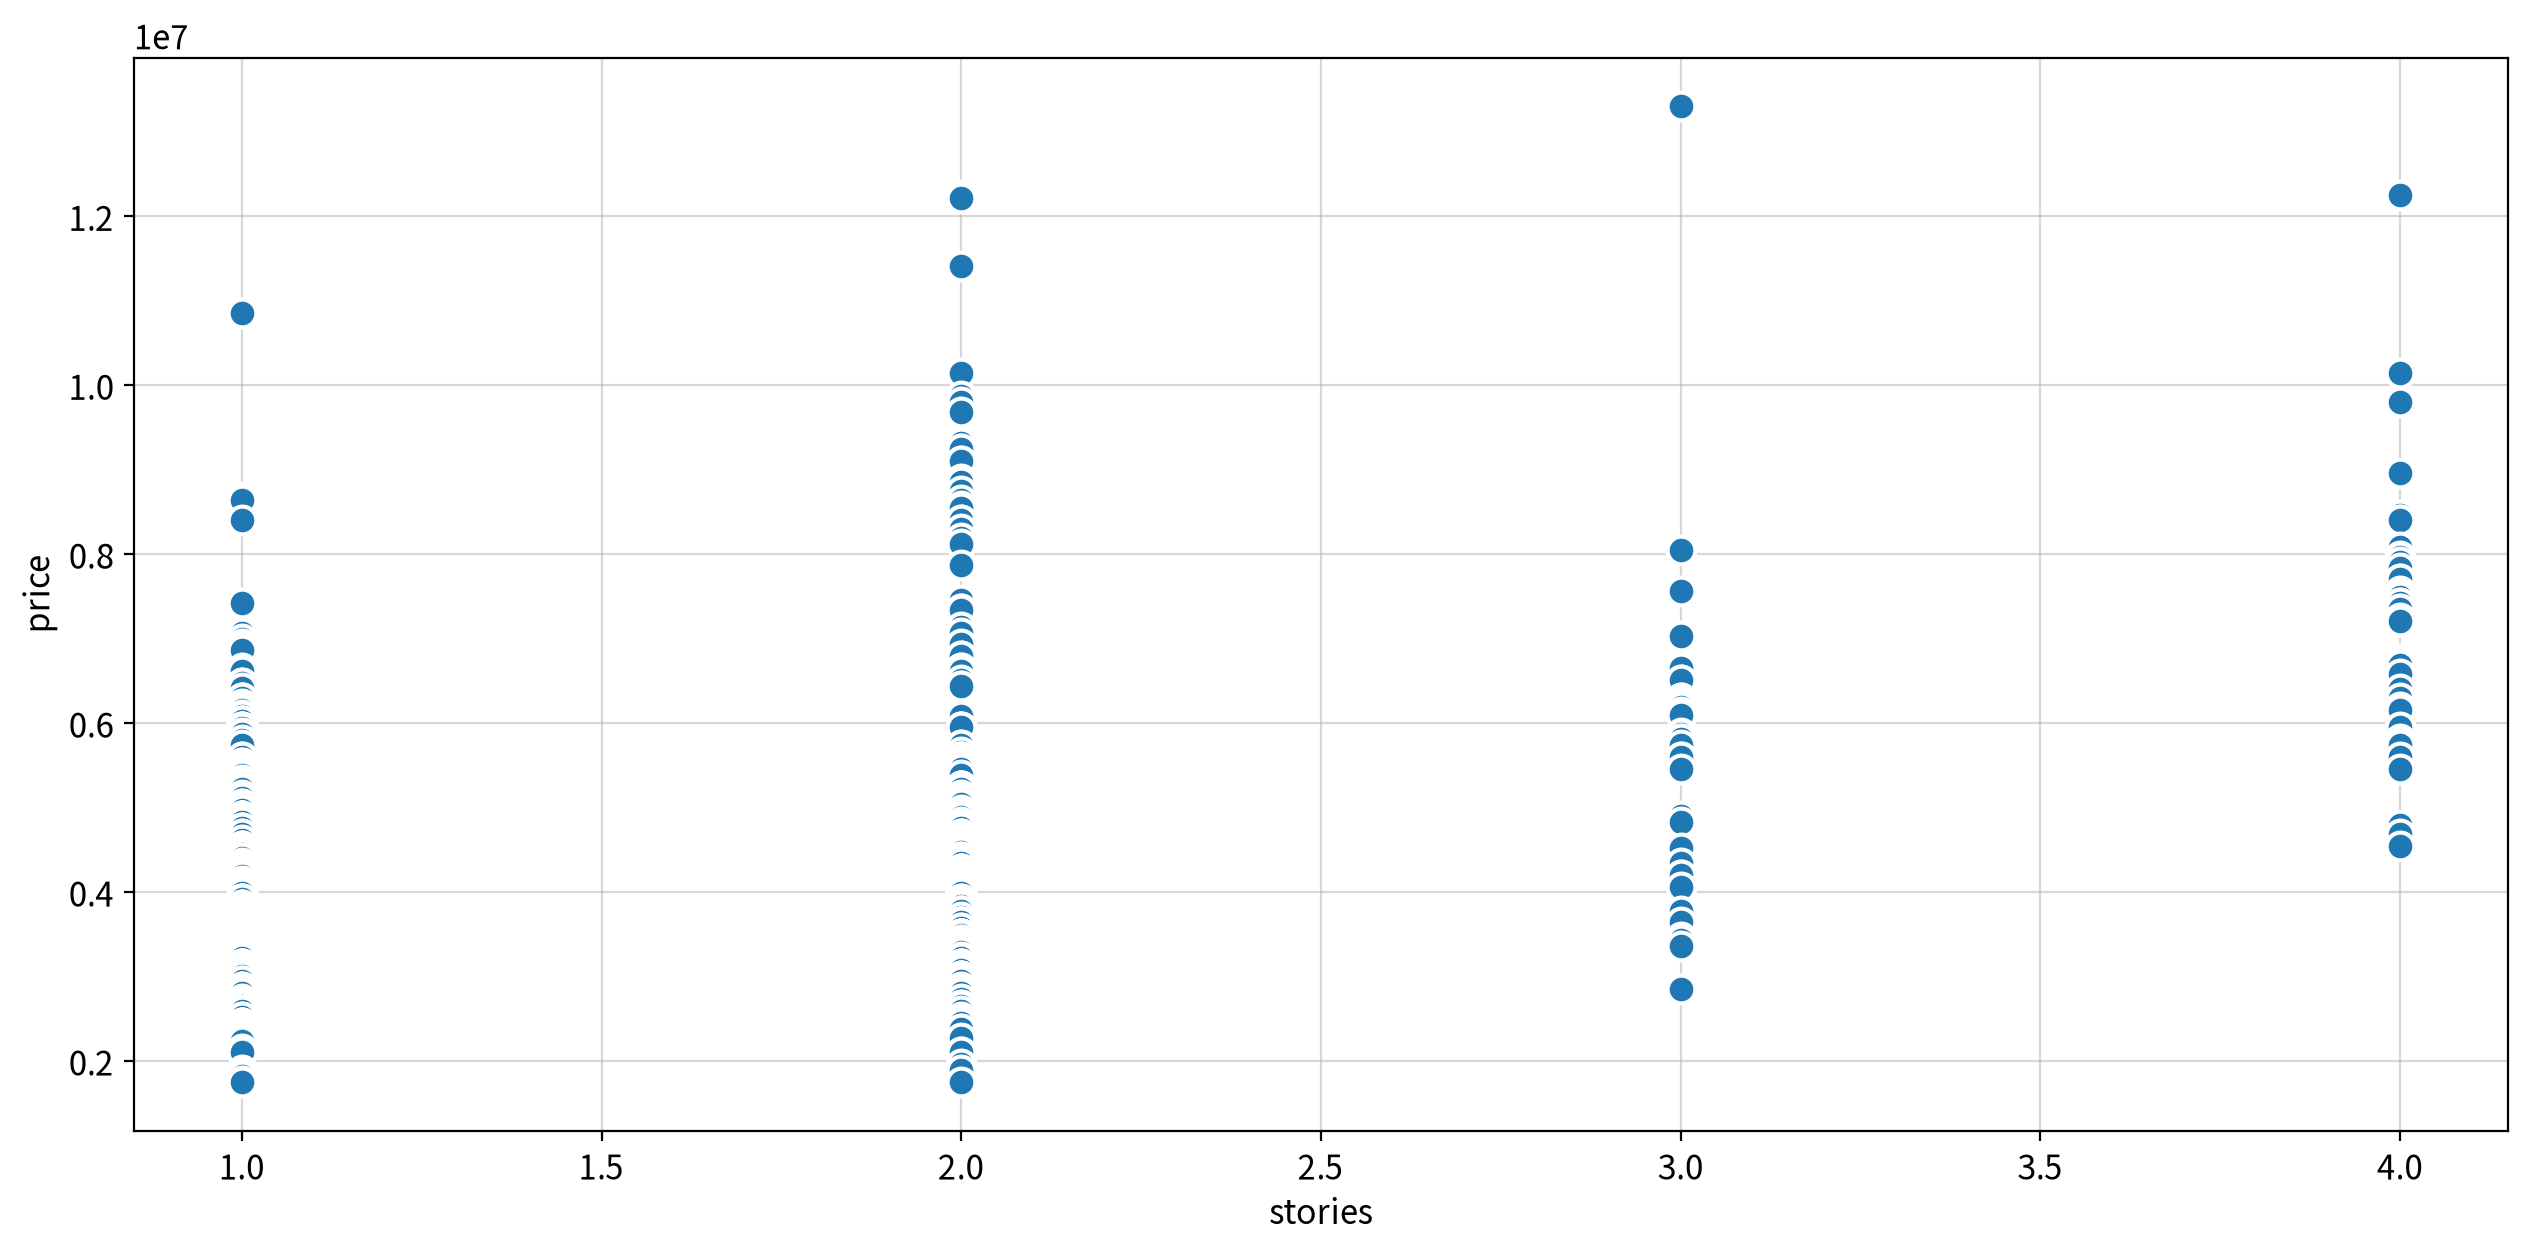

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
stories,price,Spearman,0.363,0.000,Moderate,True,False,False,False,True,True


#### ▶︎ parking(주차대수) → price

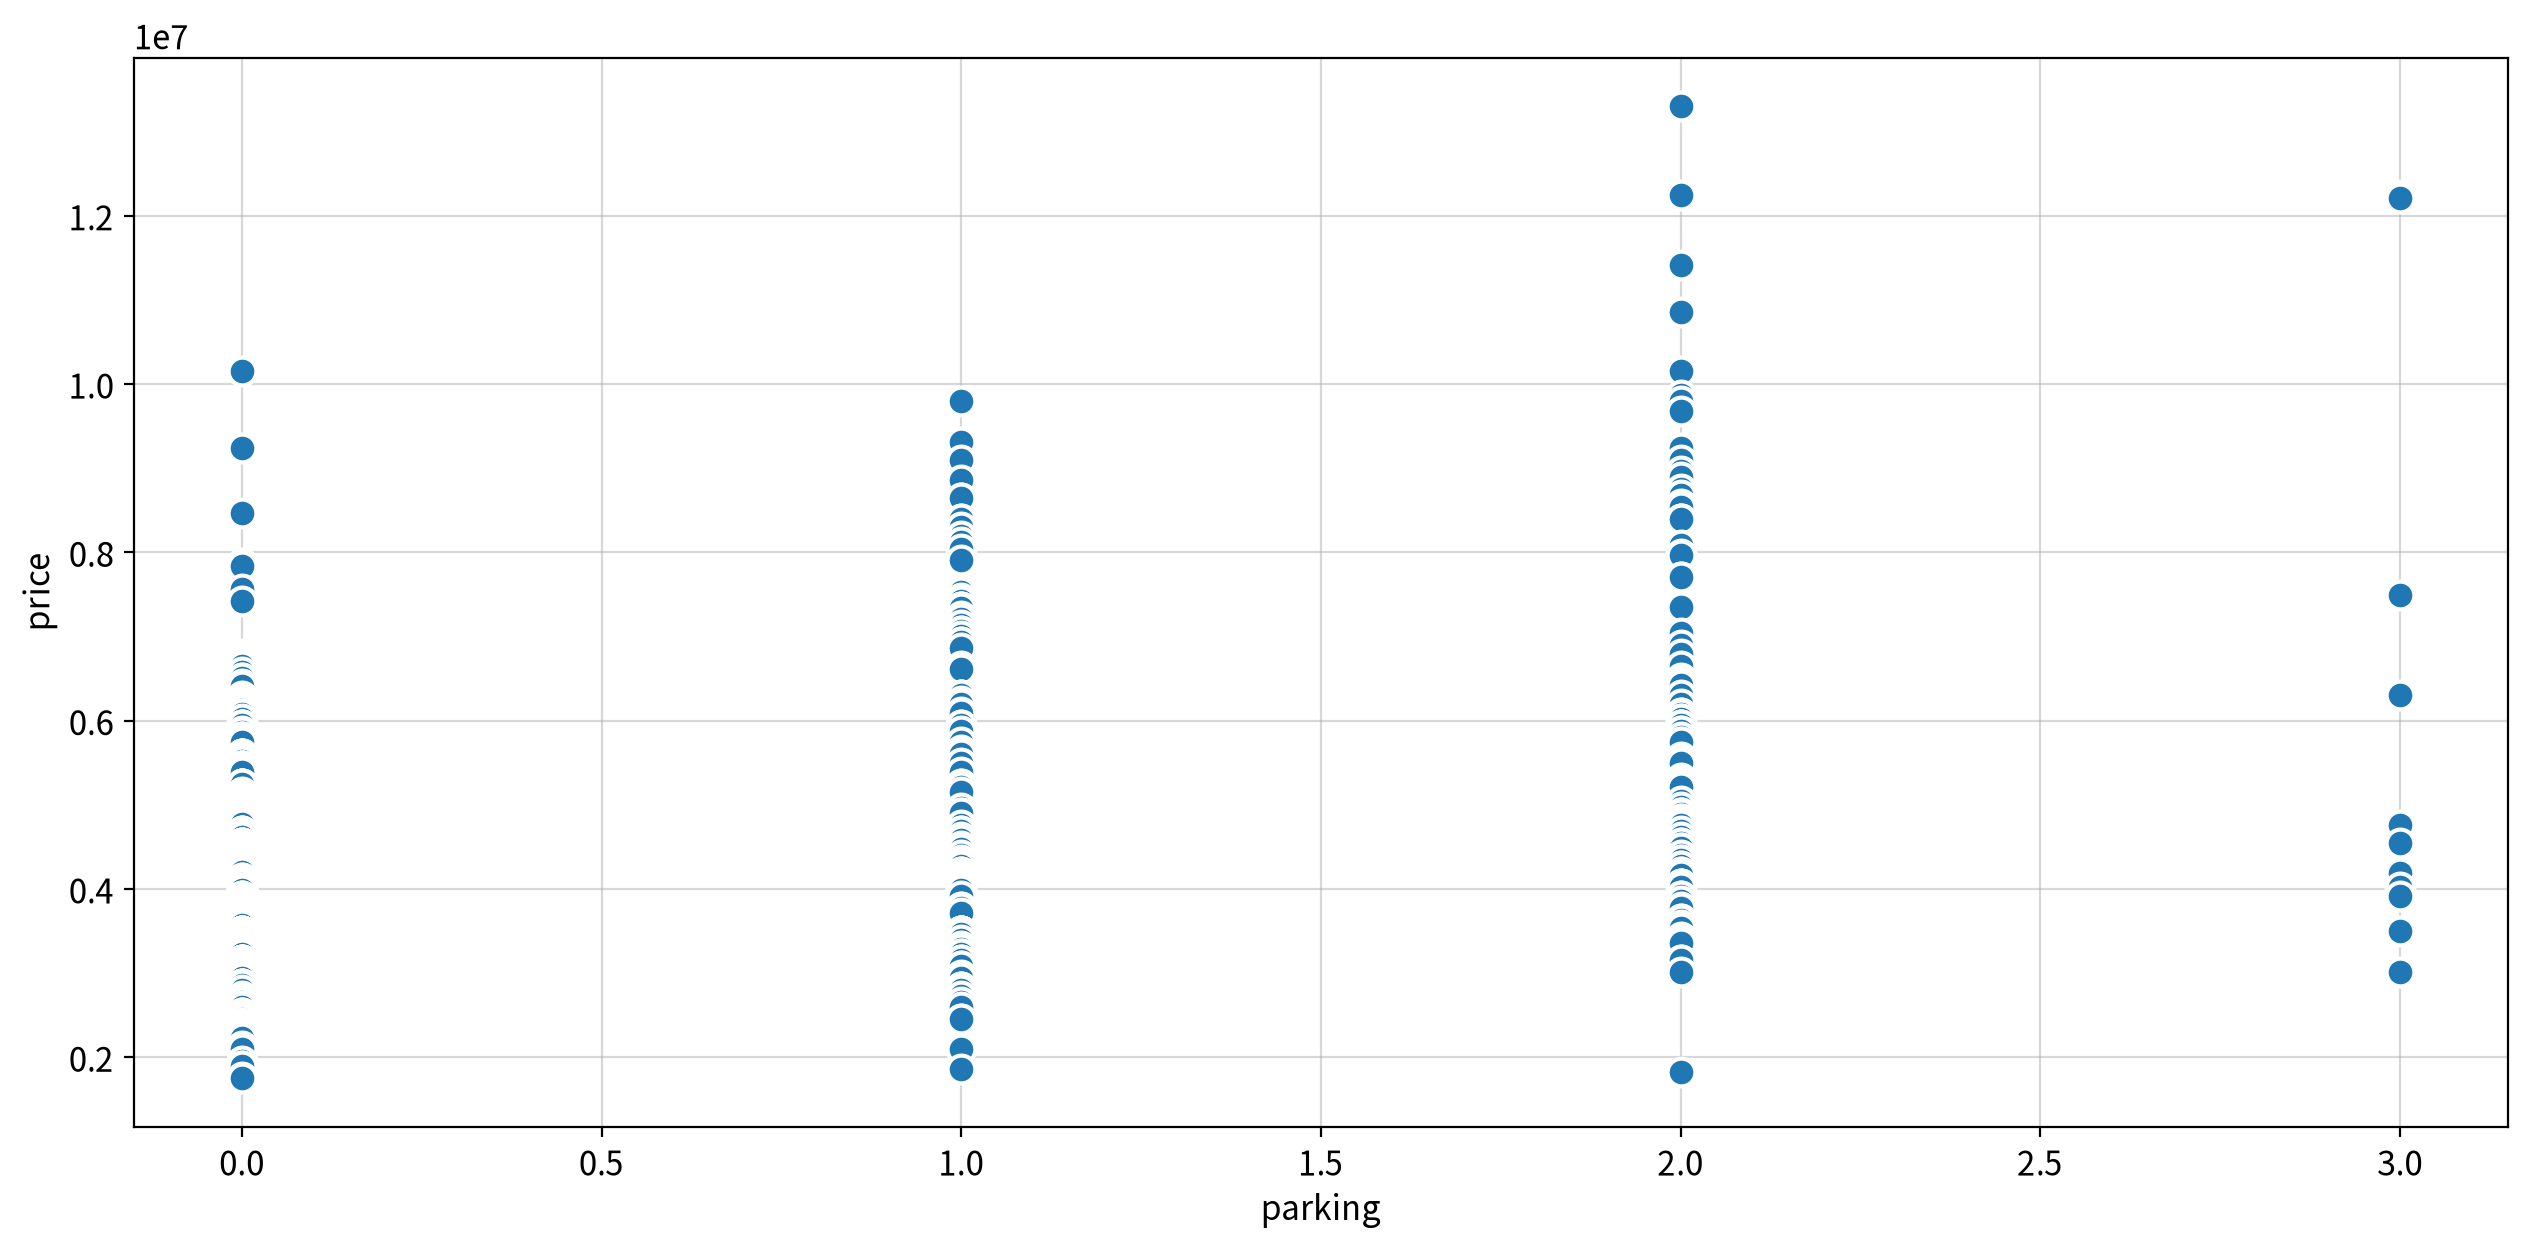

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
parking,price,Spearman,0.365,0.000,Moderate,True,False,False,False,False,True


In [14]:
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))  # h4

    # my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(data=df, x=f, y=target))

> 💡 **인사이트 — 이변량 (연속형 × price)**
>
> - ⚠️ 판정은 **"개별 독립변수 ↔ 종속변수(`price`) 단독 관계"만 기준**으로 한다. 변수 간 중복(공선성)은 여기서 고려하지 않으며, 다음 다변량 분석과 PART 3의 VIF 단계에서 점검한다. 변수별 최종 판정은 아래 (4) 변수 채택 결과 표에 정리했다.
>
> - **5개 모두 채택.** 가장 강한 신호는 **`area`(ρ = +0.603)** 이고 `bathrooms`(+0.480)가 뒤를 잇는다. 모두 양(+)의 관계로, 크고 많을수록 비싸다.
> - `price`와 독립변수 모두 정규성이 깨져 있어 **모든 변수에서 Spearman이 선택됐다.**
> - **선형성이 확인된 변수는 `bathrooms` 하나뿐**이다. `area`는 우편향이라 로그변환으로 곡선을 펼 수 있고, 나머지는 값이 몇 가지뿐인 이산형이라 직선으로 표현하기 어렵다.
> - `stories`만 **영향점(influential outlier)** 이 감지됐다. 소수의 3~4층 주택이 계수를 끌고 갈 수 있다는 신호다.

### (2) 명목형(2집단) × 연속형 : 독립표본 검정

- 옵션 6종(yes/no)을 차례로 검정한다. 
- 정규성 · 등분산성 결과에 따라 **t / Welch / Mann-Whitney U**를 자동 선택한다.

#### ▶︎ mainroad(대로변) → price

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

no vs. yes: Mann-Whitney-Wilcoxon test two-sided, P_val:2.138e-15 U_stat=7.860e+03


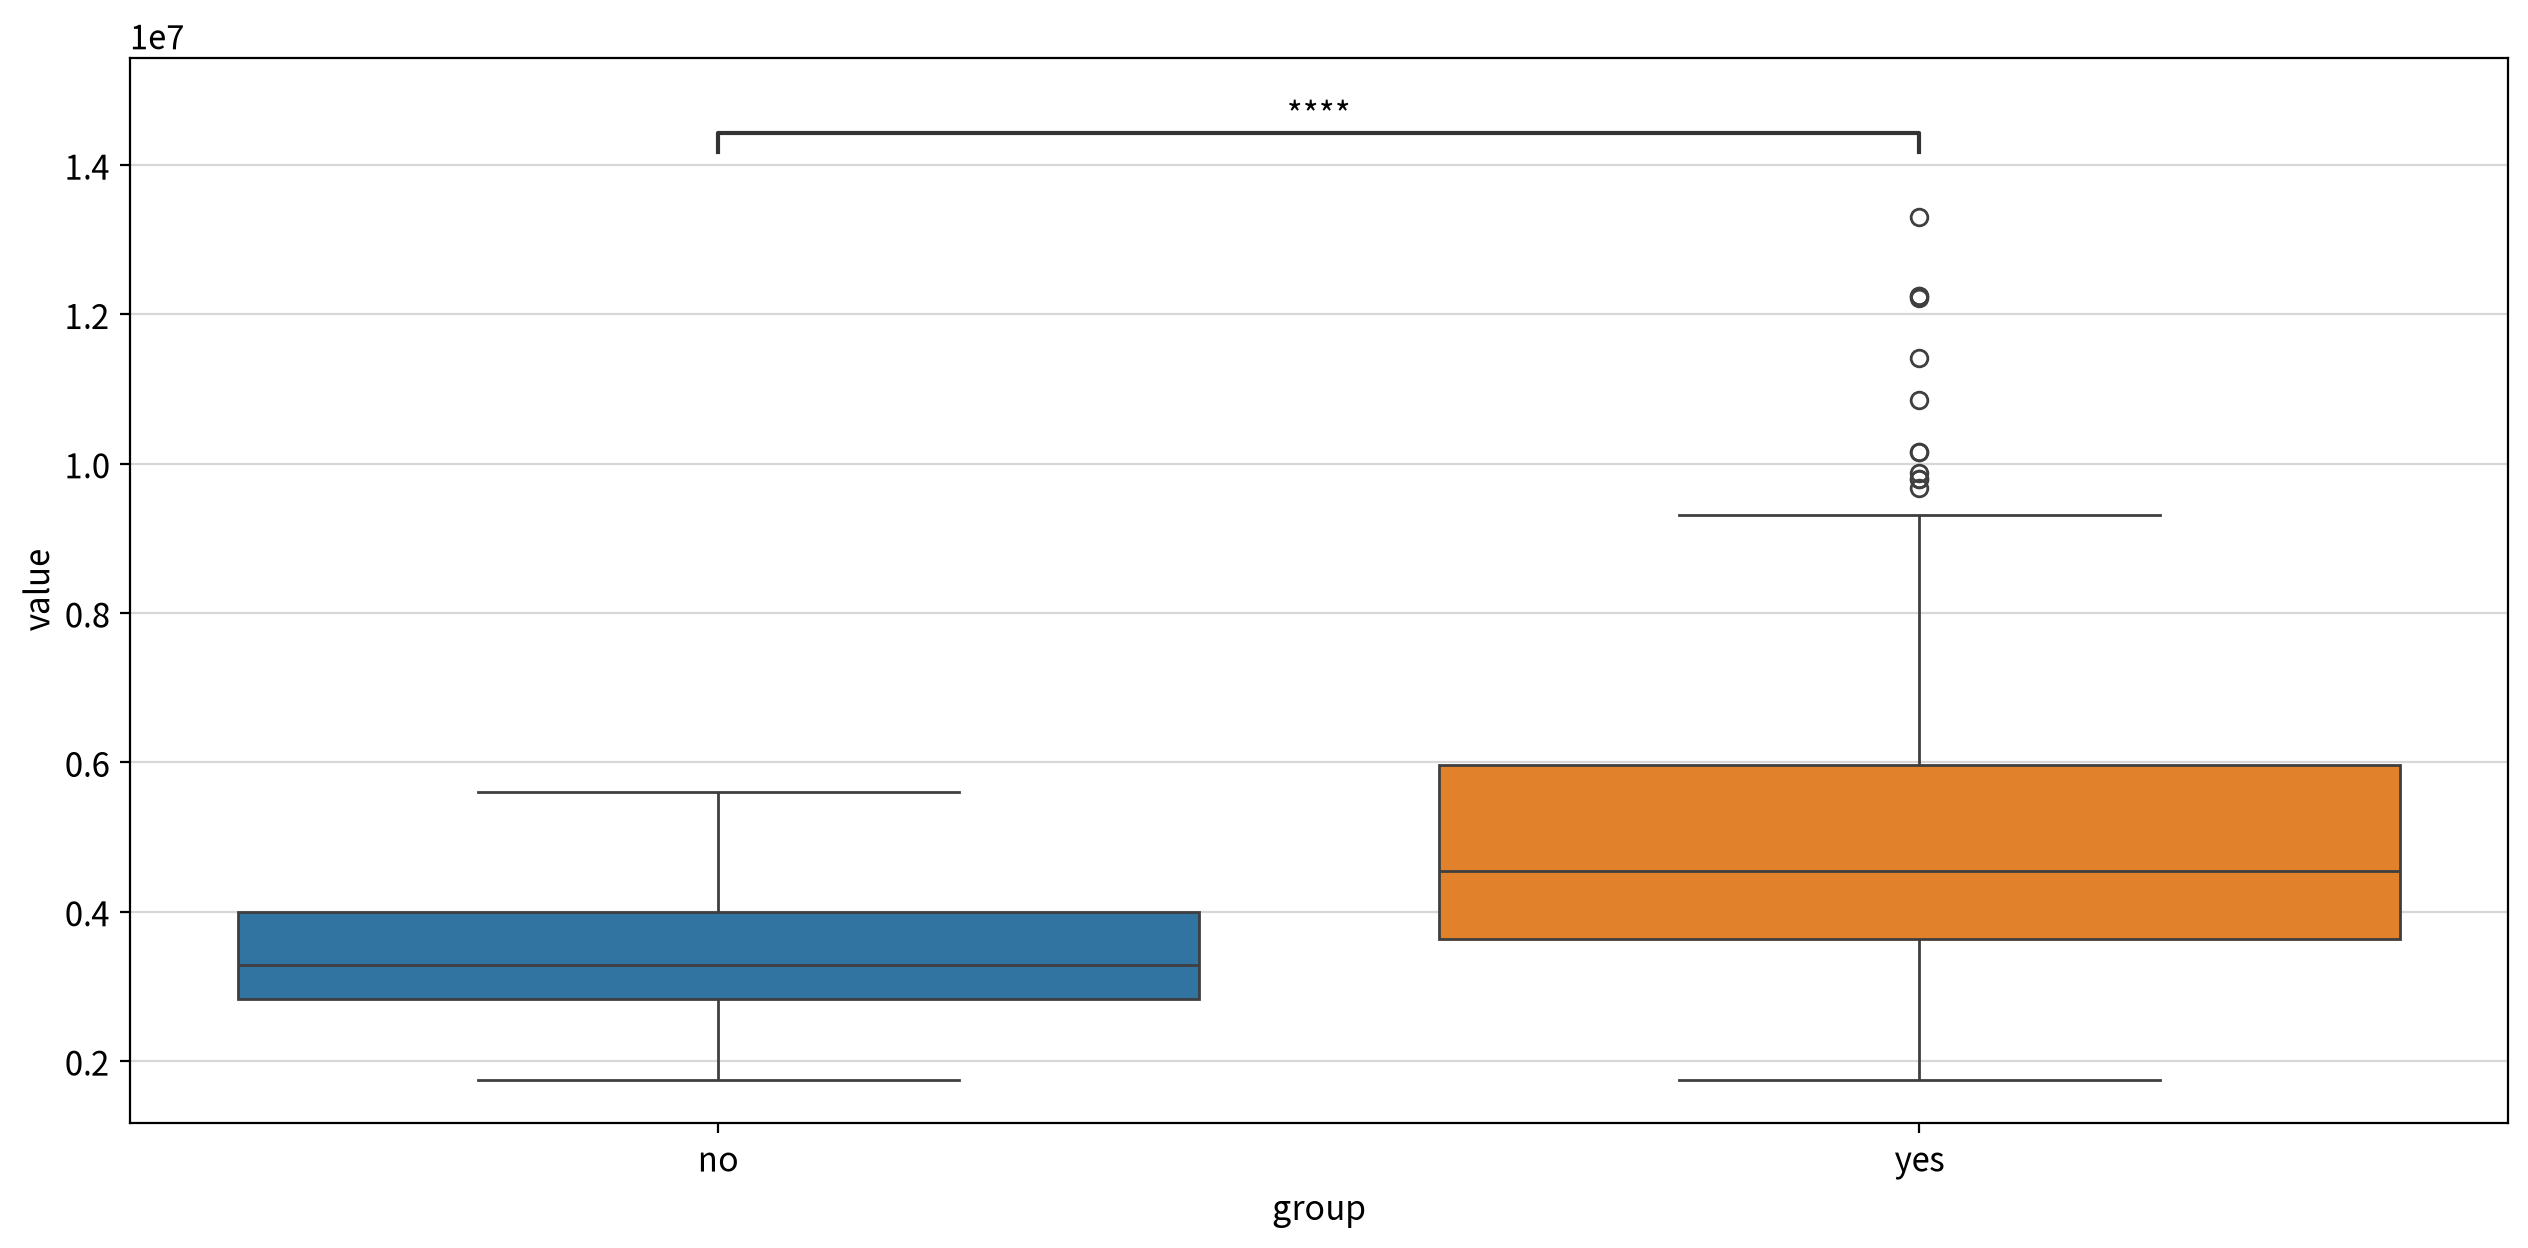

statistic  p-value  significant    result
test                alternative                                           
Mann-Whitney U test two-sided    7,860.000    0.000         True  no ≠ yes
                    less         7,860.000    0.000         True  no < yes
                    greater      7,860.000    1.000        False  no ≤ yes

#### ▶︎ guestroom(게스트룸) → price

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

no vs. yes: Mann-Whitney-Wilcoxon test two-sided, P_val:2.624e-12 U_stat=1.189e+04


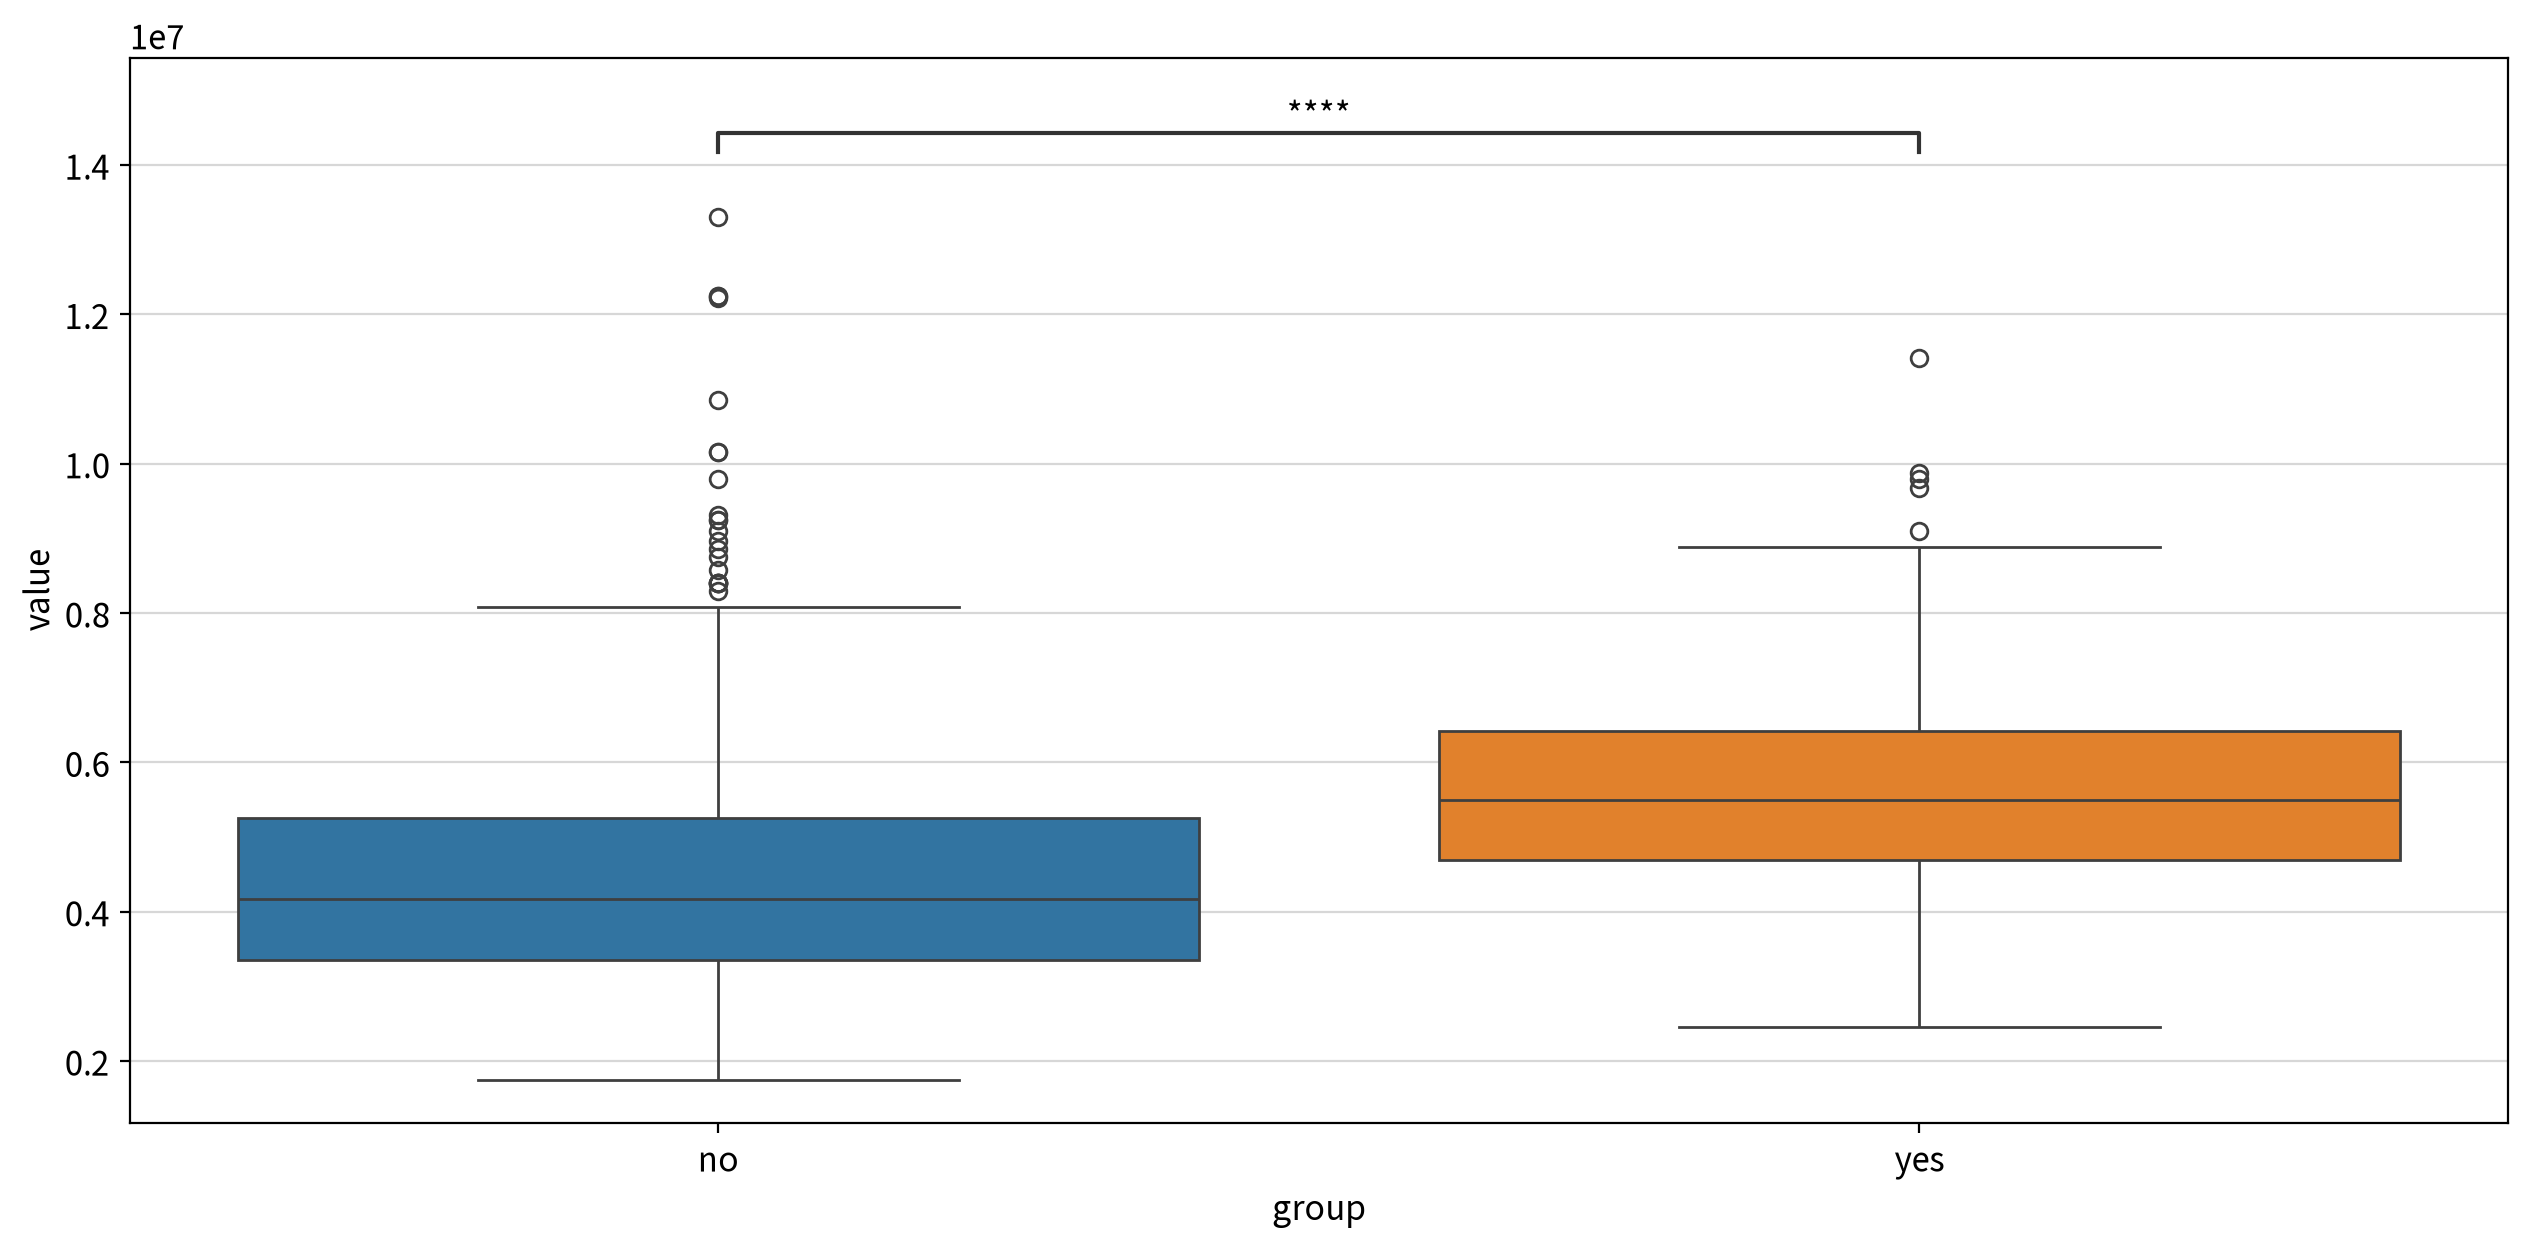

statistic  p-value  significant    result
test                alternative                                           
Mann-Whitney U test two-sided   11,890.000    0.000         True  no ≠ yes
                    less        11,890.000    0.000         True  no < yes
                    greater     11,890.000    1.000        False  no ≤ yes

#### ▶︎ basement(지하실) → price

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

no vs. yes: Mann-Whitney-Wilcoxon test two-sided, P_val:8.043e-08 U_stat=2.440e+04


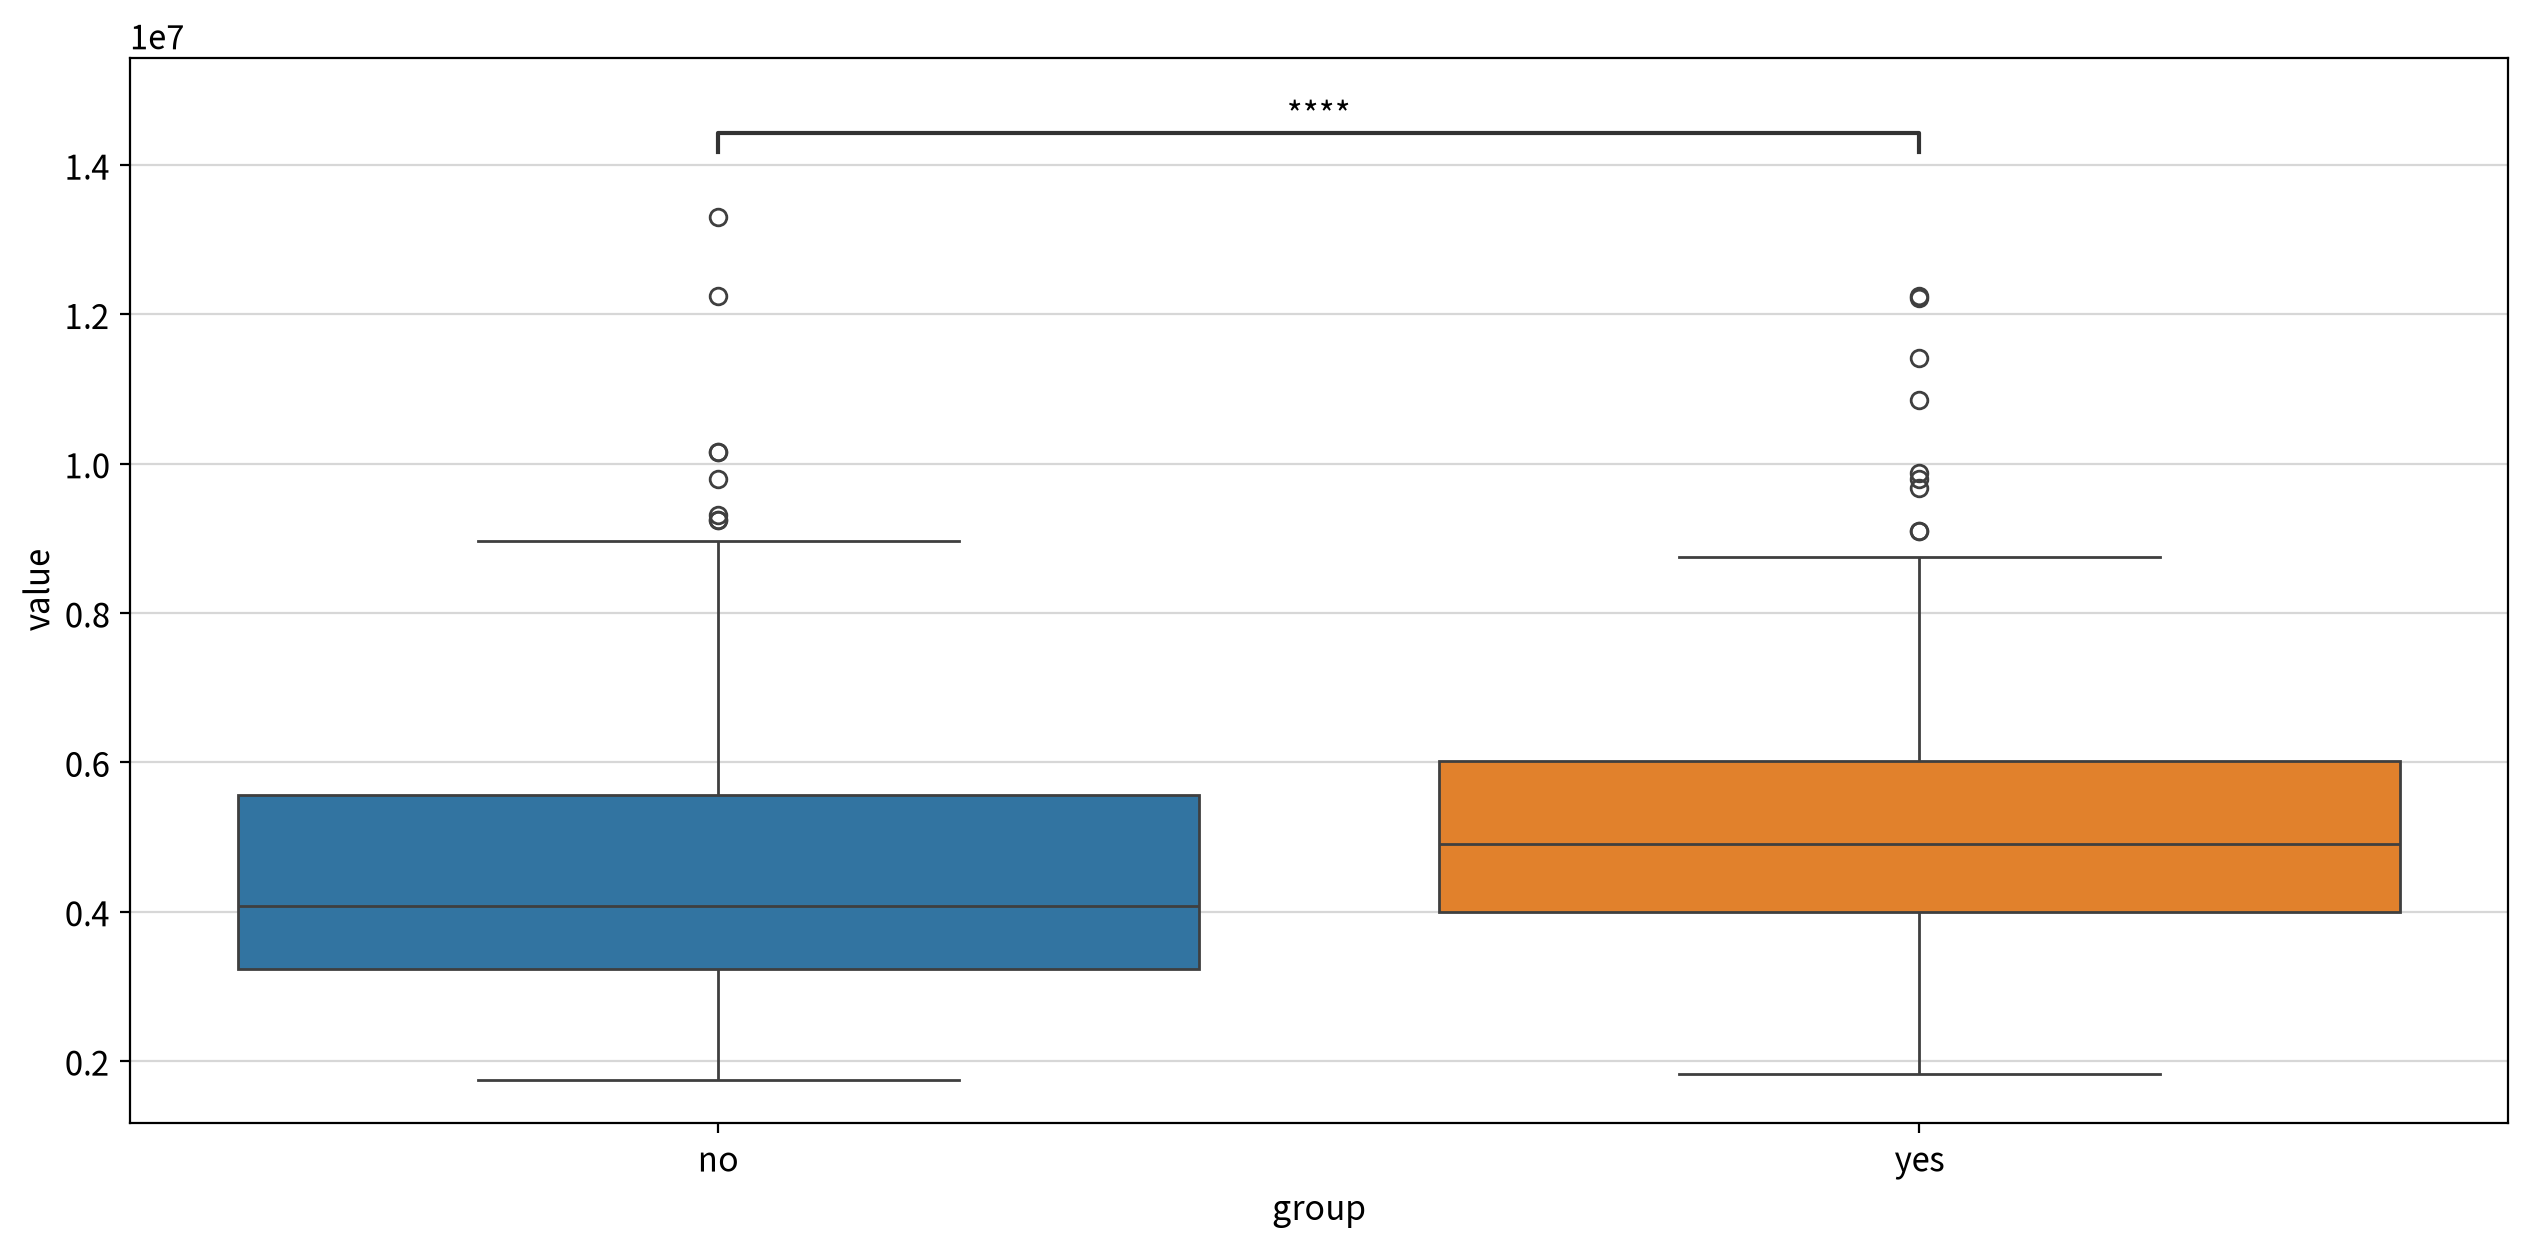

statistic  p-value  significant    result
test                alternative                                           
Mann-Whitney U test two-sided   24,395.000    0.000         True  no ≠ yes
                    less        24,395.000    0.000         True  no < yes
                    greater     24,395.000    1.000        False  no ≤ yes

#### ▶︎ hotwaterheating(온수난방) → price

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

no vs. yes: Mann-Whitney-Wilcoxon test two-sided, P_val:4.615e-02 U_stat=4.966e+03


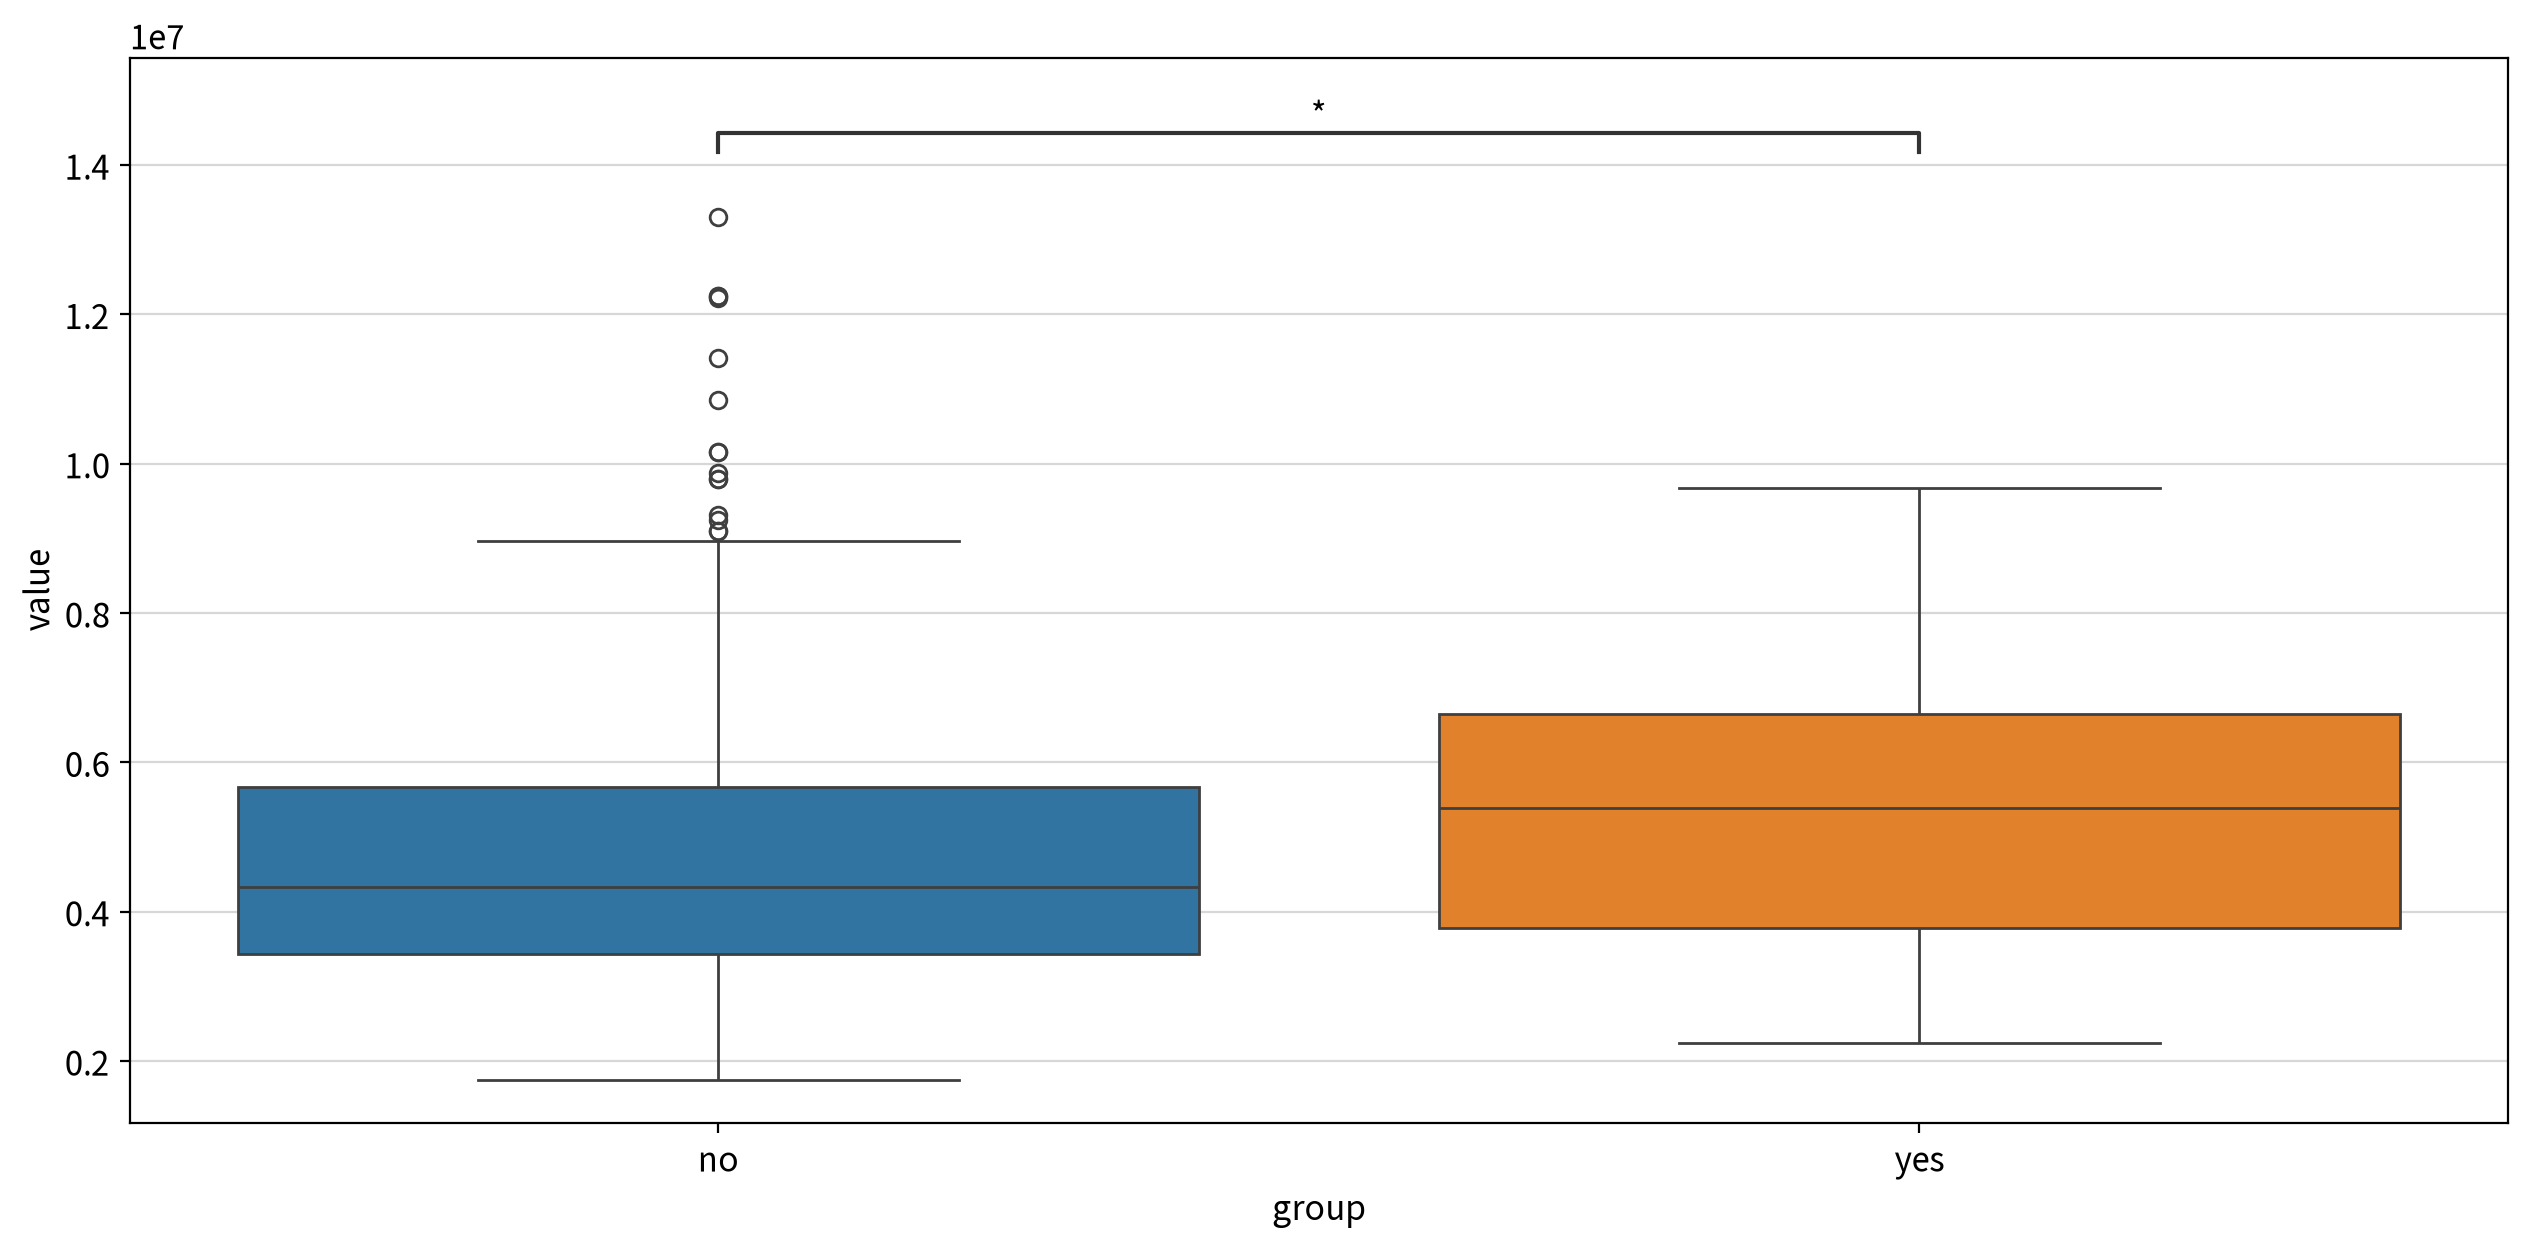

statistic  p-value  significant    result
test                alternative                                           
Mann-Whitney U test two-sided    4,966.000    0.046         True  no ≠ yes
                    less         4,966.000    0.023         True  no < yes
                    greater      4,966.000    0.977        False  no ≤ yes

#### ▶︎ airconditioning(에어컨) → price

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

no vs. yes: Mann-Whitney-Wilcoxon test two-sided, P_val:1.549e-26 U_stat=1.386e+04


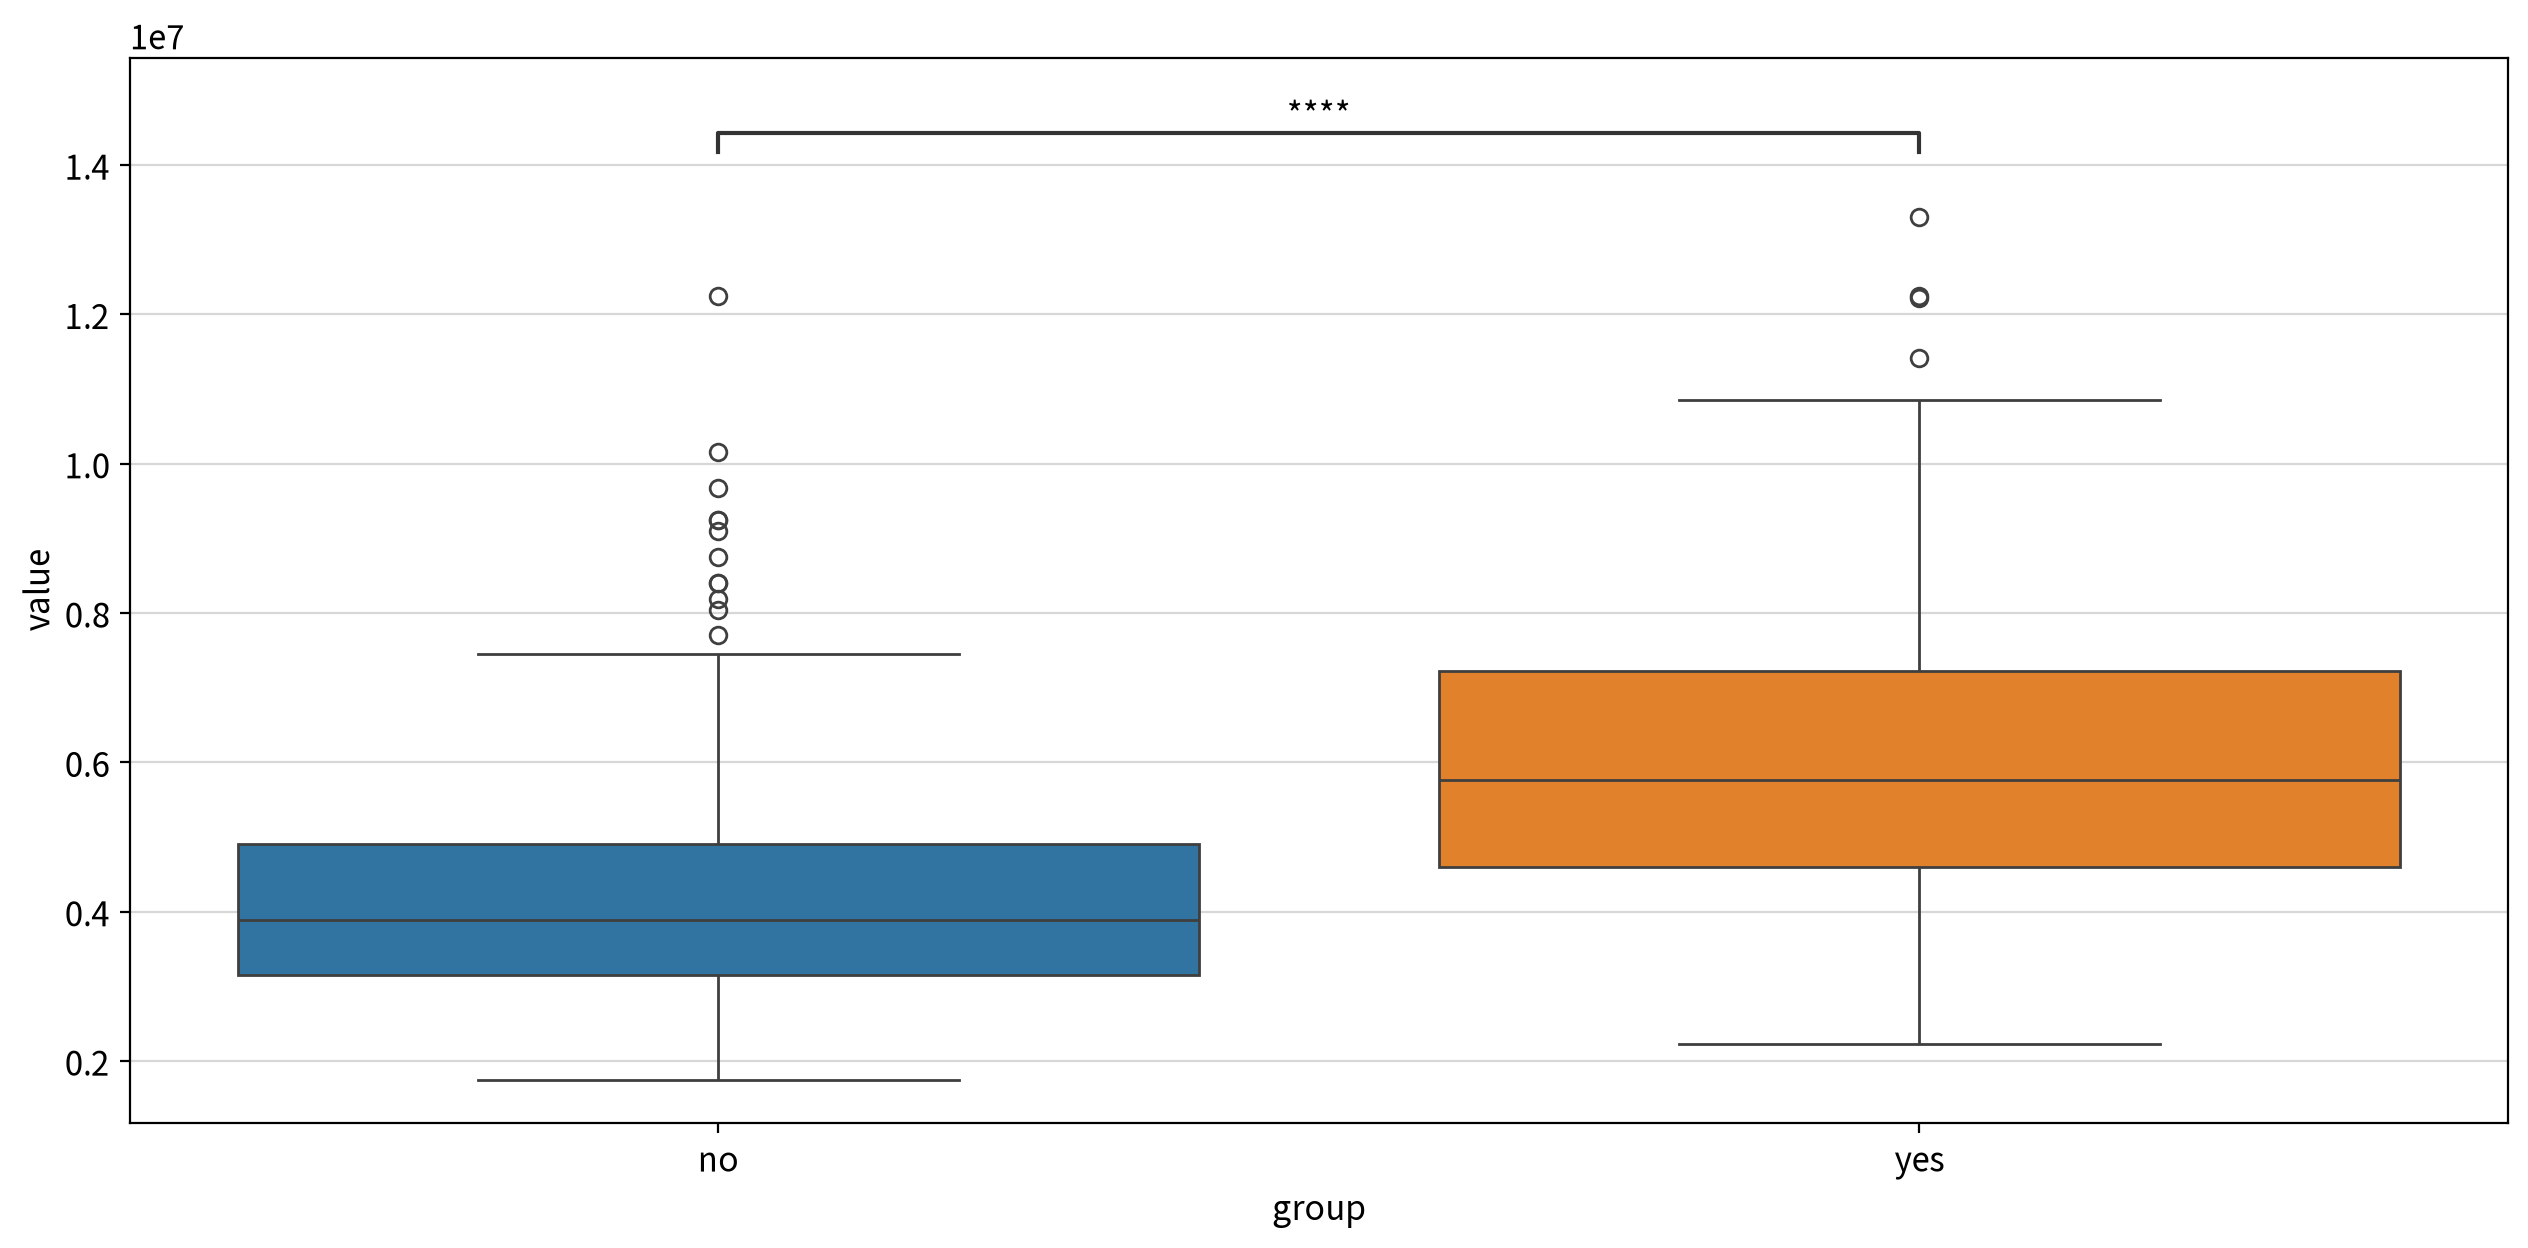

statistic  p-value  significant    result
test                alternative                                           
Mann-Whitney U test two-sided   13,864.000    0.000         True  no ≠ yes
                    less        13,864.000    0.000         True  no < yes
                    greater     13,864.000    1.000        False  no ≤ yes

#### ▶︎ prefarea(선호지역) → price

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

no vs. yes: Mann-Whitney-Wilcoxon test two-sided, P_val:5.069e-16 U_stat=1.405e+04


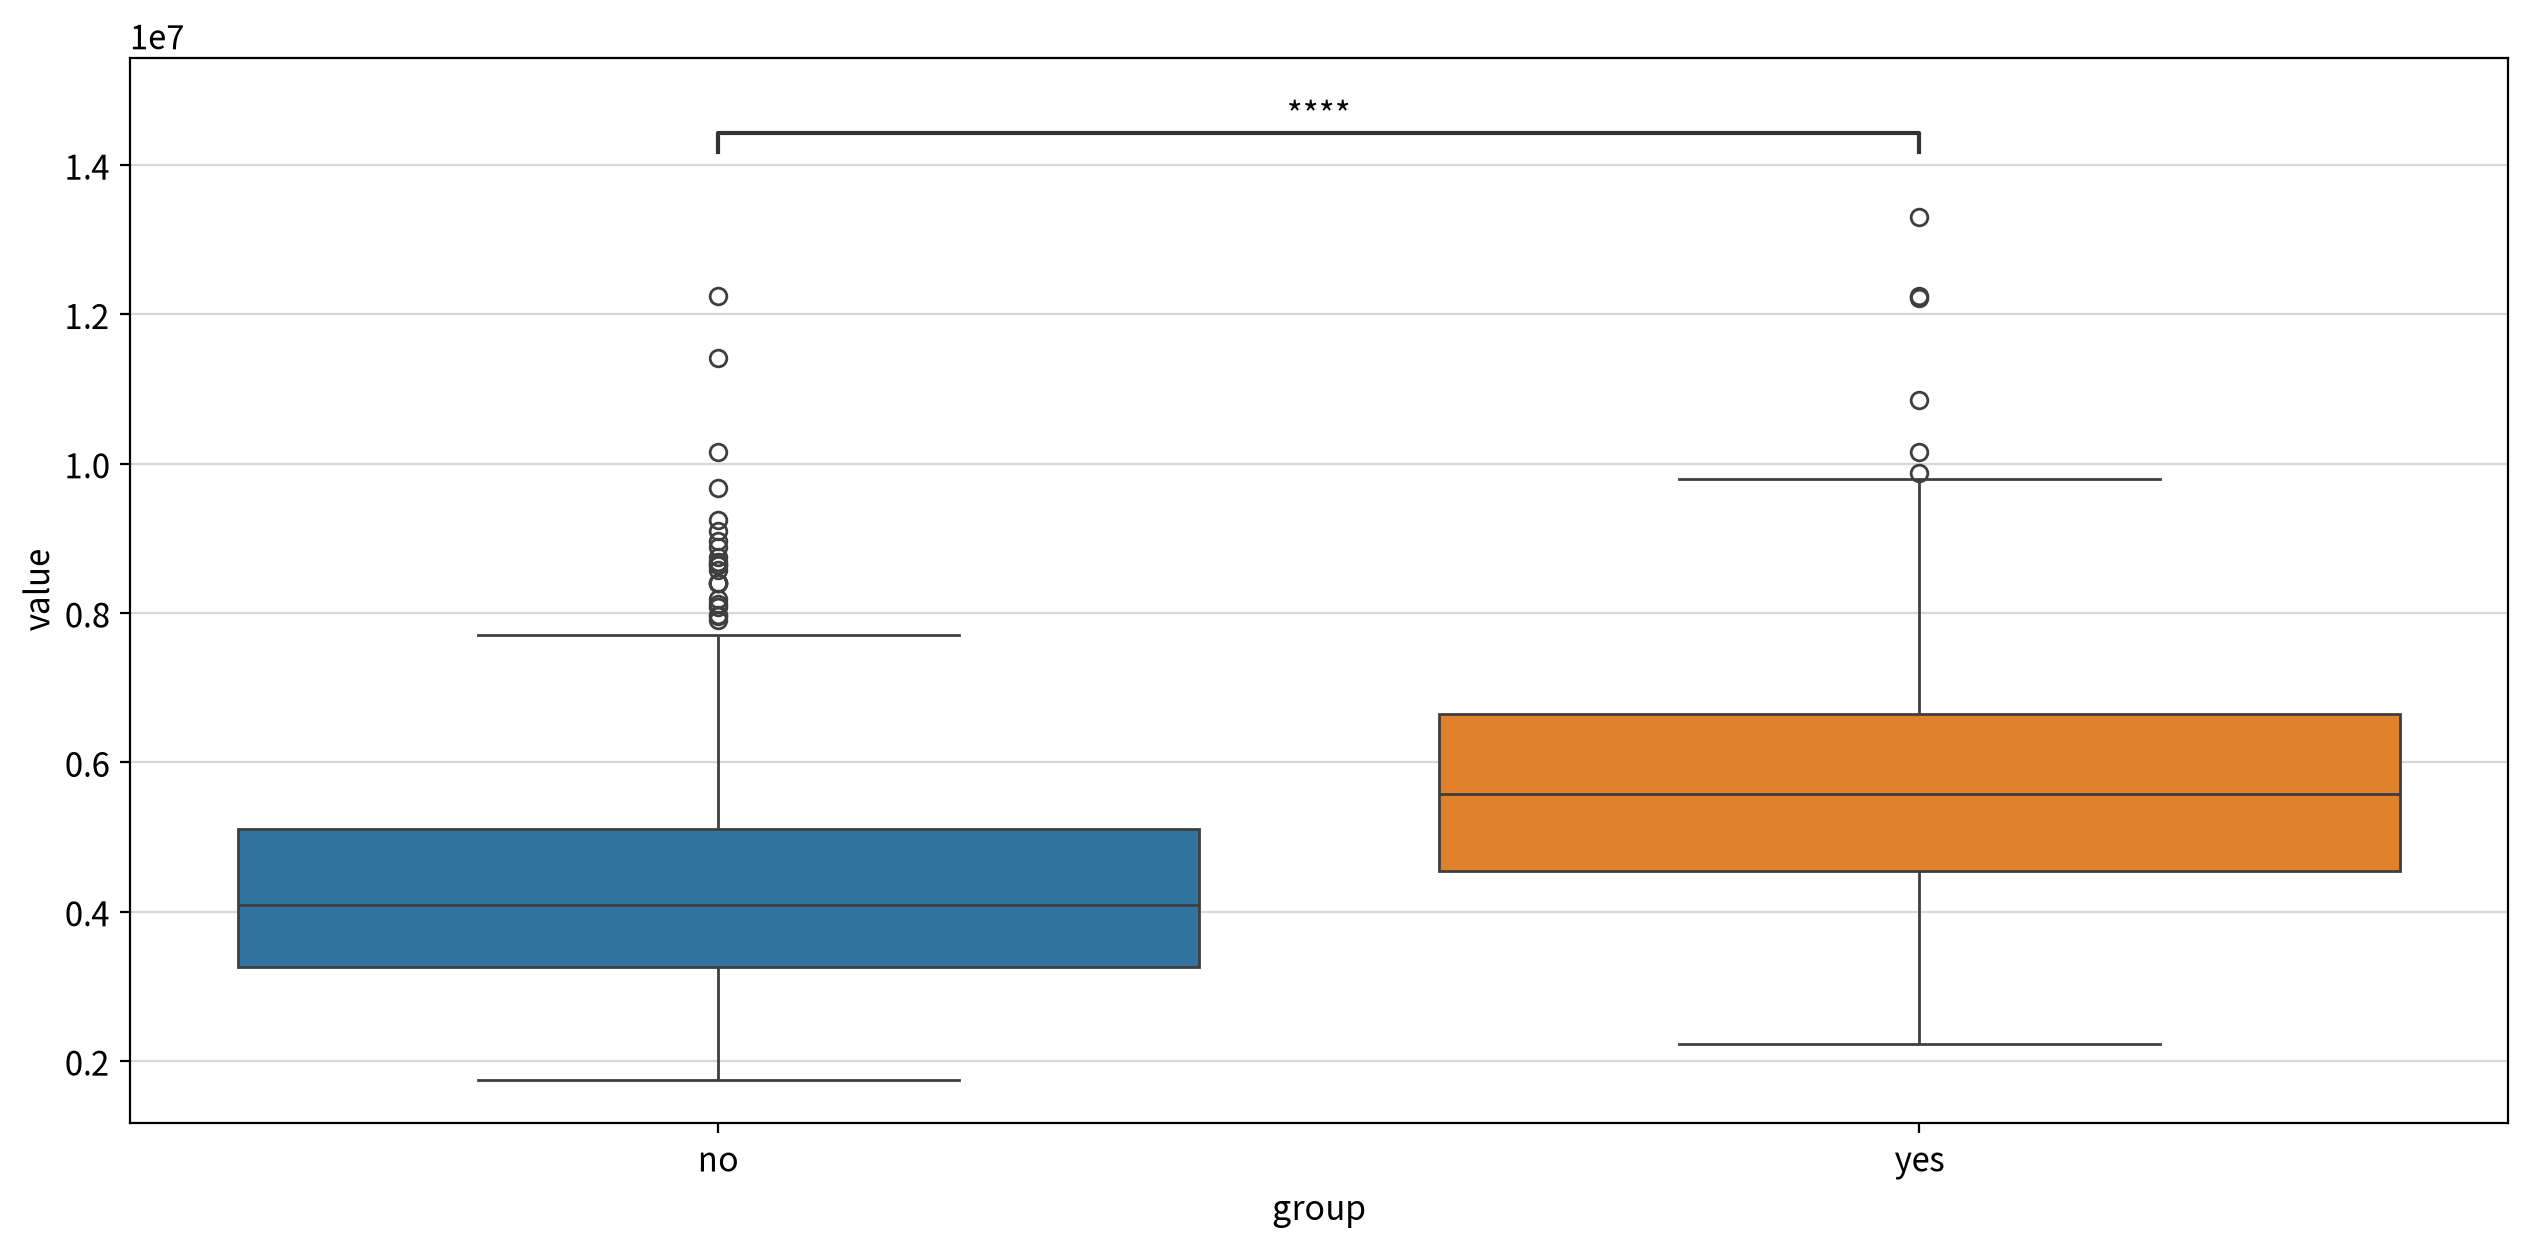

statistic  p-value  significant    result
test                alternative                                           
Mann-Whitney U test two-sided   14,050.000    0.000         True  no ≠ yes
                    less        14,050.000    0.000         True  no < yes
                    greater     14,050.000    1.000        False  no ≤ yes

In [15]:
for n in [c for c in nominal_cols if df[c].nunique() == 2]:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
    wide = my_prep.long2wide(df, hue=n, values=target)
    display(my_stats.test_independent(wide, group1=wide.columns[0], group2=wide.columns[1]))

- 옵션마다 '있는 집'이 얼마나 비싼지 같은 기준으로 비교하기 위해, 가격 중앙값을 한 표로 모은다.

In [17]:
# 옵션별 '없음 / 있음' 가격 중앙값과 차이(%)
rows = []                                                   # 옵션별 결과를 모을 리스트

for n in amenity_cols:
    m = df.groupby(n, observed=True)[target].median()      # no / yes 집단의 가격 중앙값
    diff = (m["yes"] - m["no"]) / m["no"] * 100            # 있는 집이 몇 % 비싼가
    rows.append({"옵션": n, "없음": m["no"], "있음": m["yes"], "차이(%)": diff})

# 모은 결과를 표로 만들고, 차이가 큰 순서로 정렬
DataFrame(rows).set_index("옵션").sort_values("차이(%)", ascending=False)

,없음,있음,차이(%)
옵션,,,
airconditioning,"3,885,000.000","5,757,500.000",48.198
mainroad,"3,290,000.000","4,550,000.000",38.298
prefarea,"4,095,000.000","5,582,500.000",36.325
guestroom,"4,165,000.000","5,495,000.000",31.933
hotwaterheating,"4,329,500.000","5,383,000.000",24.333
basement,"4,077,500.000","4,900,000.000",20.172


> 💡 **인사이트 — 이변량 (옵션 yes/no × price)**
>
> - **옵션 6종 모두 '있는 집'이 유의하게 비쌌다**(Mann-Whitney U, 단측(no < yes) 모두 유의). 가격 중앙값 차이로 줄 세우면:
>
> | 옵션 | 에어컨 | 대로변 | 선호지역 | 게스트룸 | 온수난방 | 지하실 |
> |---|---|---|---|---|---|---|
> | 있는 집의 중앙값 차이 | **+48%** | +38% | +36% | +32% | +24% | +20% |
>
> - 온수난방은 양측 p = 0.046으로 경계선이다. 보유한 집이 25채뿐이라 검정력이 낮다.
> - 여섯 옵션의 효과가 **모두 같은 방향(+)** 이고 크기도 비슷한 범위(+20~48%)에 있다. → 옵션을 하나로 묶을 수 있는지 다변량 분석에서 확인한다.

### (3) 명목형(3집단 이상) × 연속형 : 일원분산분석 + 사후검정

- ` 등분산 여부에 따라 **ANOVA / Welch ANOVA**를 자동 선택한다.

#### ▶︎ furnishingstatus(가구비치) → price

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,furnishingstatus,2,311.332,25.892,0.000,0.094,Medium


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

furnished vs. semi-furnished: Custom statistical test, P_val:1.405e-02
semi-furnished vs. unfurnished: Custom statistical test, P_val:4.541e-07
furnished vs. unfurnished: Custom statistical test, P_val:3.376e-10


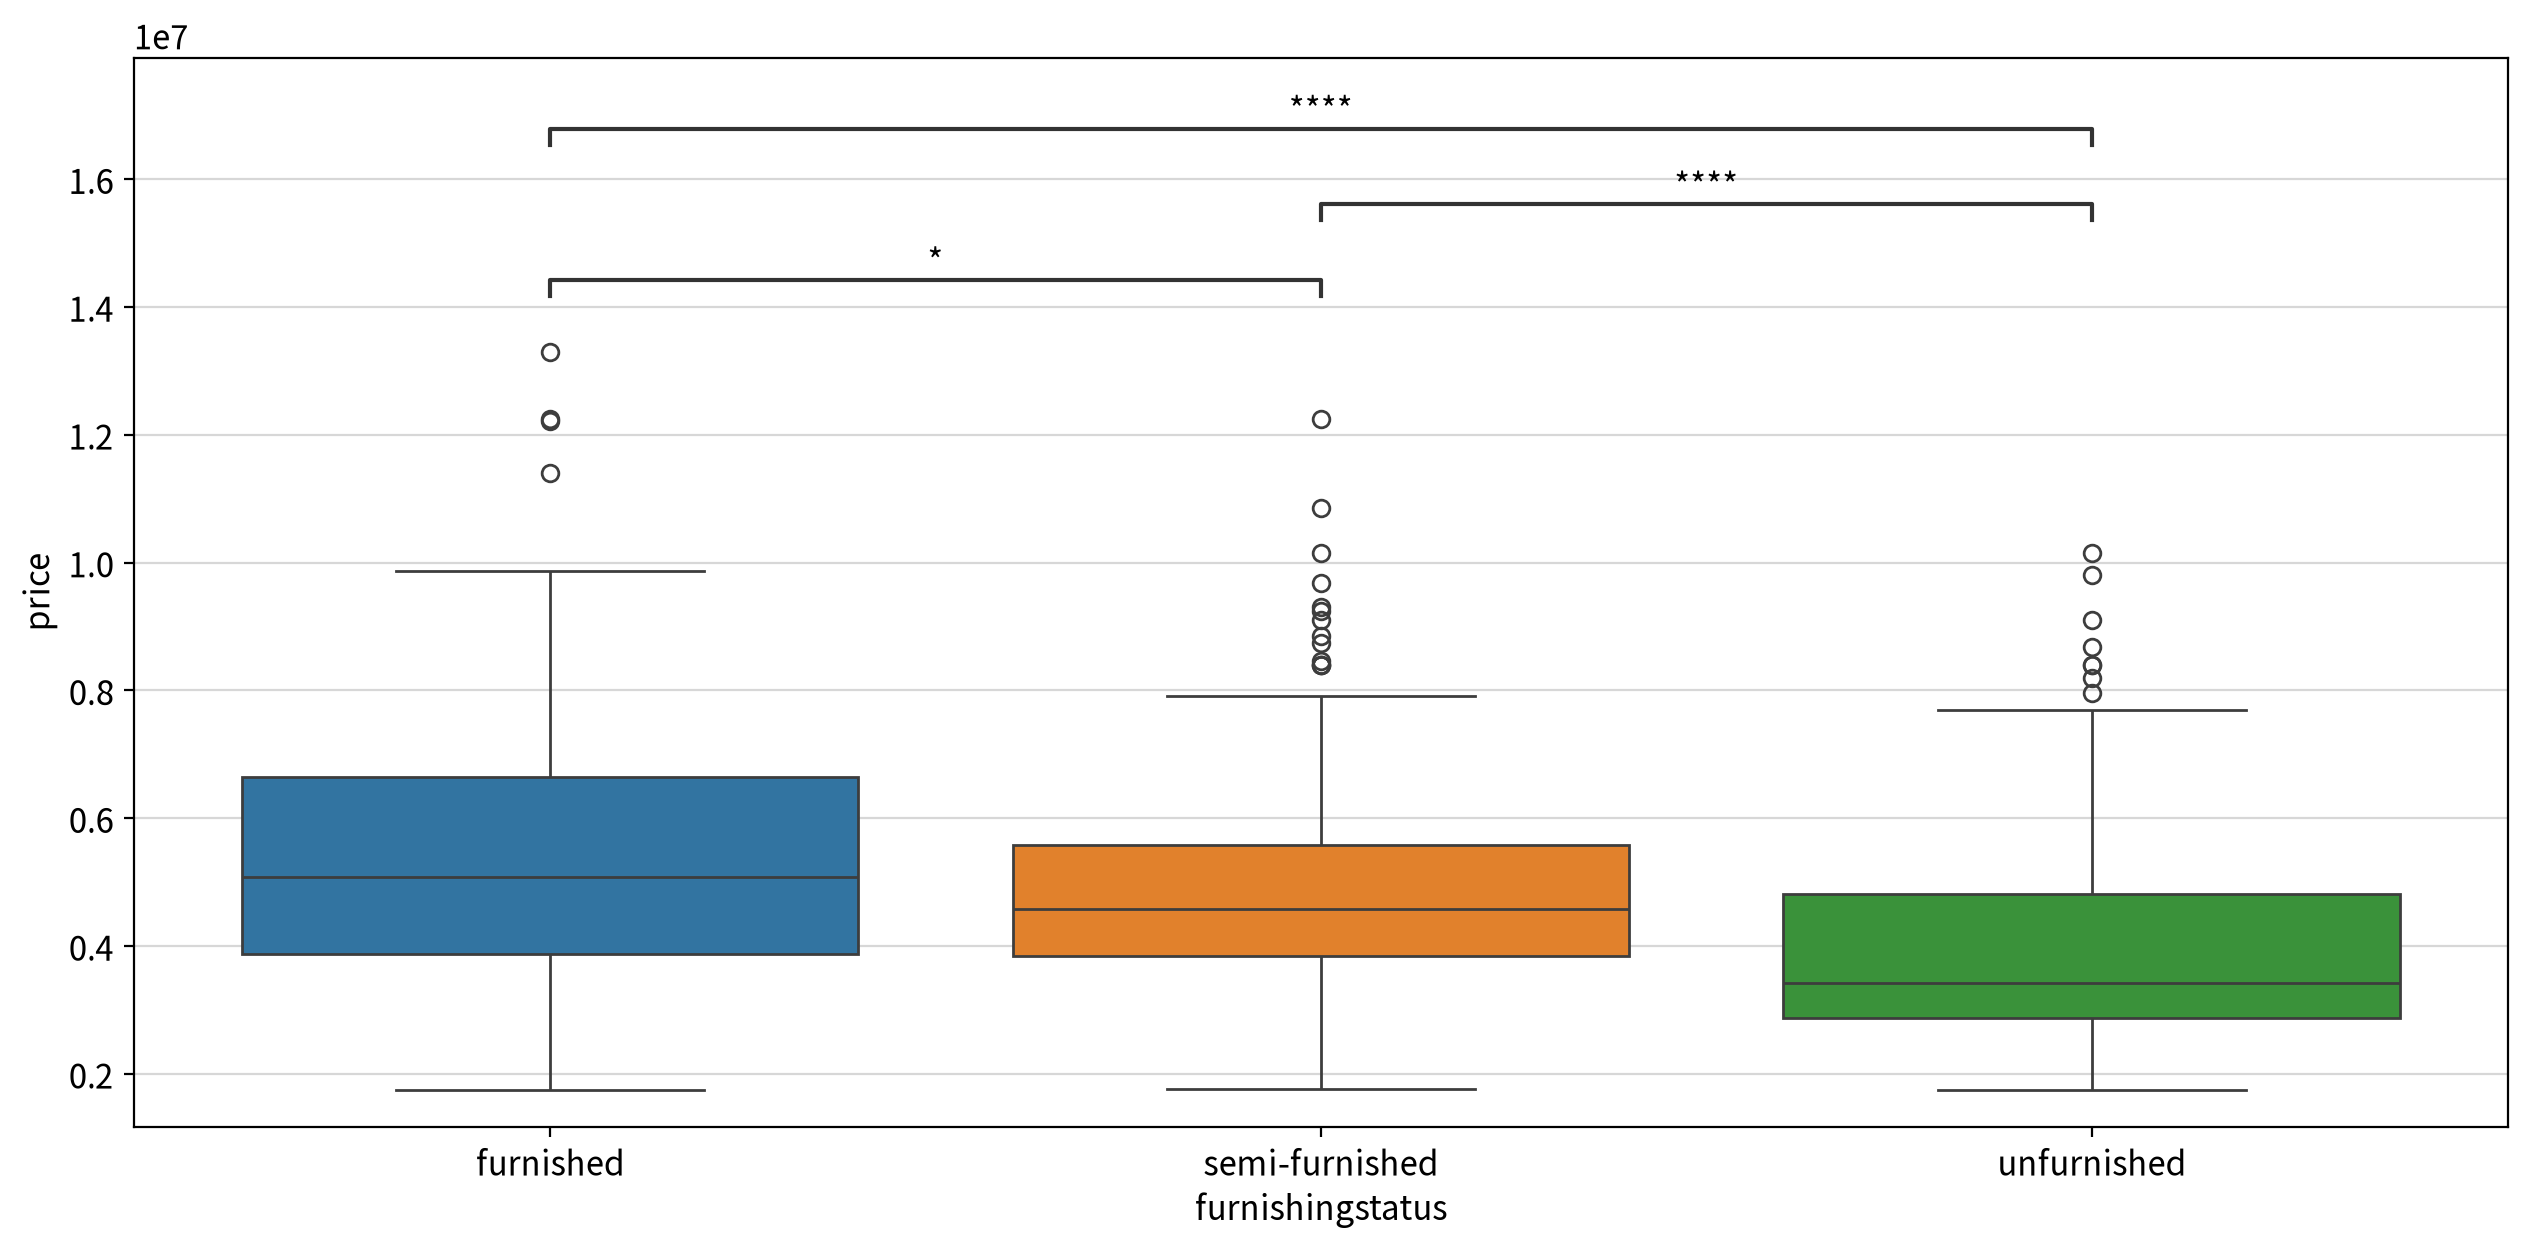

비교한 조합 쌍: 3개
유의한 쌍: 3개
평균 차이가 가장 큰 쌍: (furnished) vs (unfurnished)→ 차이 1481864.539, 효과크기 Medium, p=value 0.000
평균 차이가 가장 작은 쌍: (furnished) vs (semi-furnished)→ 차이 588171.771, 효과크기 Small, p-value 0.014


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,furnished,semi-furnished,"5,495,696.000","4,907,524.229","588,171.771","208,011.686",2.828,235.718,0.014,0.324,True,Small
1,Games-Howell,furnished,unfurnished,"5,495,696.000","4,013,831.461","1,481,864.539","220,596.844",6.718,264.711,0.000,0.776,True,Medium
2,Games-Howell,semi-furnished,unfurnished,"4,907,524.229","4,013,831.461","893,692.768","166,900.820",5.355,366.077,0.000,0.540,True,Medium


In [18]:
for n in [c for c in nominal_cols if df[c].nunique() >= 3]:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # anova 분석은 long 타입으로 바로 투입 가능
    display(my_stats.anova_oneway(df, y=target, between=n))

    # 사후검정
    display(my_stats.posthoc_oneway(df, y=target, between=n))

> 💡 **인사이트 — 이변량 (furnishingstatus × price)**
>
> - 등분산성이 위배돼 Welch ANOVA가 선택됐고, **유의했다**(p < 0.001). 효과크기는 np² = 0.094로 **Medium**(Cohen 기준)이다.
> - Games-Howell 사후검정에서 **세 쌍이 모두 유의**했다. 가구 완비 > 반 비치 > 미비치 순으로 비싸다.
>   - 완비 vs 미비치 : Hedges' g = 0.78 (Medium)
>   - 반 비치 vs 미비치 : g = 0.54 (Medium)
>   - 완비 vs 반 비치 : g = 0.32 (Small) — 차이가 가장 작다.

### (4) 변수 채택 결과 표

- **채택 기준은 "각 독립변수 ↔ 종속변수(`price`) 단독 관계"만 사용한다.**
  - 연속형 : 유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)
  - 명목형 : 집단 차이 유의(p < 0.05)
- 공선성(변수 간 중복)은 이 이변량 단계에서는 알 수 없으므로, 다음 다변량 분석과 PART 3의 VIF 단계에서 점검한다.
- 종합 판정 : **채택 12, 보류 0, 제외 0**

| 채택여부 | 변수 | 검정방법 | 유의수준 (p) | 효과크기 | 가정점검 | 비대칭신호 | 근거 |
|---|---|---|---|---|---|---|---|
| ✅ 채택 | area | Spearman | $< 0.001$ | ρ=+0.603 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | 설명력 1위 |
| ✅ 채택 | bathrooms | Spearman | $< 0.001$ | ρ=+0.480 (중간) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 없음 | 우편향 / log | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | bedrooms | Spearman | $< 0.001$ | ρ=+0.390 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | parking | Spearman | $< 0.001$ | ρ=+0.365 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | stories | Spearman | $< 0.001$ | ρ=+0.363 (중간) | 정규성 위배 / 선형성 위배 / **이상치 왜곡 있음** | 우편향 / log | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | airconditioning | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 있는 집이 중앙값 +48% |
| ✅ 채택 | mainroad | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 있는 집이 중앙값 +38% |
| ✅ 채택 | prefarea | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 있는 집이 중앙값 +36% |
| ✅ 채택 | guestroom | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 있는 집이 중앙값 +32% |
| ✅ 채택 | hotwaterheating | Mann-Whitney U | $0.046$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 있는 집이 중앙값 +24% (경계선, 보유 25채) |
| ✅ 채택 | basement | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 있는 집이 중앙값 +20% |
| ✅ 채택 | furnishingstatus | Welch ANOVA | $< 0.001$ | np²=0.094 (Medium) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 세 집단 모두 유의하게 다름 |

## 2-3. 다변량 분석 — 독립변수끼리 중복되는가?

### (1) 독립변수 간 상관

- |ρ| ≥ 0.7 인 **강한 상관 쌍**을 변수별로 묶어 보여 준다.

In [19]:
corr_x = my_stats.multi_correlation(data=df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr_x)

,area,bedrooms,bathrooms,stories,parking
area,1.000,0.176,0.214,0.058,0.353
bedrooms,0.176,1.000,0.377,0.504,0.147
bathrooms,0.214,0.377,1.000,0.309,0.174
stories,0.058,0.504,0.309,1.000,0.018
parking,0.353,0.147,0.174,0.018,1.000


,max-y,max-coef,count,columns
x,,,,
bedrooms,stories,0.504,0,-
stories,bedrooms,0.504,0,-
bathrooms,bedrooms,0.377,0,-
area,parking,0.353,0,-
parking,area,0.353,0,-


> 💡 **인사이트 — 다변량 (독립변수 간 상관)**
>
> - 연속형 독립변수끼리는 **강한 상관 쌍이 하나도 없다**(|ρ| ≥ 0.7 인 쌍 0개). 가장 강한 쌍은 `bedrooms` ↔ `stories`(ρ = +0.504)로, 층이 많은 집이 방도 많다는 정도의 중간 관계다.
> - 다섯 변수는 서로 다른 정보를 담고 있어, 공선성 때문에 후보로 내릴 변수는 없다.
> - 이 단계에서 변수를 실제로 제거하지는 않는다. 실제 VIF가 문제 수준인지는 PART 3의 `vif=True` 체크포인트에서 확인한다.

### (2) 옵션은 '종류'가 중요한가, '개수'가 중요한가?

- 집마다 옵션을 몇 개 갖췄는지(0~6개) 세고, 개수별 가격 중앙값을 본다.

In [20]:
# 옵션 보유 개수 (yes 의 개수)
amenity = (df[amenity_cols] == "yes").sum(axis=1)

# 보유 옵션 수별 가격 중앙값과 집 수
df.groupby(amenity)[target].agg(가격중앙값="median", 집수="size").rename_axis("보유 옵션 수").T

보유 옵션 수,0,1,2,3,4,5
가격중앙값,"2,992,500.000","3,500,000.000","4,550,000.000","5,355,000.000","5,950,000.000","6,300,000.000"
집수,42.000,172.000,164.000,102.000,50.000,15.000


> 💡 **인사이트 — 옵션은 '개수'가 가격을 가른다**
>
> - 옵션 보유 개수별 가격 중앙값이 **계단처럼 단조 증가**한다:
>
> | 보유 옵션 수 | 0 | 1 | 2 | 3 | 4 | 5 |
> |---|---|---|---|---|---|---|
> | 가격 중앙값 (백만) | 2.99 | 3.50 | 4.55 | 5.36 | 5.95 | 6.30 |
> | 집 수 | 42 | 172 | 164 | 102 | 50 | 15 |
>
> - 옵션 0개 → 5개면 가격 중앙값이 약 **2.1배**다(2.99 → 6.30백만). 6개를 모두 갖춘 집은 한 채도 없다.
> - → 개별 옵션 6개 대신 **보유 개수(`amenity`, 0~6점)** 하나로 모델을 간결하게 만들 수 있는지 PART 3에서 검증한다.

## 2-4. 최종 변수 선택

- **EDA 판정 기준**
  - 이변량 : 유의(p < 0.05) + |ρ| ≥ 0.3 → ✅ 채택, 유의하지만 |ρ| < 0.3 → 🟡 보류, 유의하지 않음 → ❌ 제외
  - 다변량 : |ρ| ≥ 0.7로 얽힌 쌍이 없어(최대 `bedrooms` ↔ `stories` ρ = +0.504) 공선성 때문에 후보로 내릴 변수는 없다
  - 파생변수 : 옵션 6종은 보유 개수에 따라 가격이 단조 증가한다

| EDA 판정 | 변수 | 검정방법 | 유의수준 | 효과크기 | 가정점검 | 비대칭신호 | 중복 (\|ρ\| ≥ 0.7) | EDA 근거 | 파생변수 근거 |
|---|---|---|---|---|---|---|---|---|---|
| ✅ 채택 | area | Spearman | $< 0.001$ | ρ=+0.603 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | 없음 | 설명력 1위 | — |
| ✅ 채택 | bathrooms | Spearman | $< 0.001$ | ρ=+0.480 (중간) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 없음 | 우편향 / log | 없음 | 유의미한 상관 | — |
| ✅ 채택 | bedrooms | Spearman | $< 0.001$ | ρ=+0.390 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 없음 | 유의미한 상관 | — |
| ✅ 채택 | parking | Spearman | $< 0.001$ | ρ=+0.365 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / 불필요 | 없음 | 유의미한 상관 | — |
| ✅ 채택 | stories | Spearman | $< 0.001$ | ρ=+0.363 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 있음 | 우편향 / log | 없음 | 유의미한 상관 | — |
| ✅ 채택 | airconditioning | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 중앙값 +48% | 보유 개수별 단조 증가 → `amenity` |
| ✅ 채택 | mainroad | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 중앙값 +38% | 〃 |
| ✅ 채택 | prefarea | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 중앙값 +36% | 〃 |
| ✅ 채택 | guestroom | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 중앙값 +32% | 〃 |
| ✅ 채택 | hotwaterheating | Mann-Whitney U | $0.046$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 중앙값 +24% (경계선) | 〃 |
| ✅ 채택 | basement | Mann-Whitney U | $< 0.001$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 중앙값 +20% | 〃 |
| ✅ 채택 | furnishingstatus | Welch ANOVA | $< 0.001$ | np²=0.094 (Medium) | 등분산성 위배 → Welch ANOVA, Games-Howell | 해당 없음 | 해당 없음 | 세 집단 모두 다름 | — |

<br>

> 💡 **인사이트 — EDA 판정 요약**
>
> - **12개 모두 채택됐다.** 서로 얽힌 덩어리도 없고, 효과가 없는 변수도 없다.
> - 대신 이 데이터의 과제는 **'같은 성격의 변수가 많다'** 는 점이다. 옵션 6종은 모두 같은 방향의 효과를 가지므로, 하나로 묶었을 때 성능을 얼마나 지키는지를 PART 3에서 검증한다.

---
# PART 3. 회귀모델링

### (1) EDA 결과 반영 · 더미 기준 범주 확인

- EDA에서 제외한 변수가 없으므로 **모든 변수를 투입**한다.
- `labeling`은 범주를 **알파벳 순**으로 0부터 매기고, 0번이 더미의 기준 범주가 된다.

In [21]:
df2 = df.copy()      # 제외할 변수가 없으므로 모든 변수를 그대로 쓴다
_ = my_prep.labeling(df2, columns=nominal_cols)
print("모델 투입 변수 :", df2.columns.drop(target).tolist())

mainroad (2종): no=0, yes=1
guestroom (2종): no=0, yes=1
basement (2종): no=0, yes=1
hotwaterheating (2종): no=0, yes=1
airconditioning (2종): no=0, yes=1
prefarea (2종): no=0, yes=1
furnishingstatus (3종): furnished=0, semi-furnished=1, unfurnished=2
모델 투입 변수 : ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


### (2) 전처리 체크포인트 정의

In [22]:
checkpoints = {
    "0_기준선":     dict(),
    "1_로그변환":   dict(log=True),
    "2_이상치대체": dict(log=True, outlier=True),
    "3_공선성제거": dict(log=True, outlier=True, vif=True),
    "4_스케일링":   dict(log=True, outlier=True, vif=True, scale=True),
}

### (3) 체크포인트별 적합

In [23]:
fits = {}

for name in checkpoints:           # 딕셔너리를 반복문에 설정하면 key에 대한 반복이 수행된다
    print(f"\n▶︎ --- {name} ---")

    # 전처리 + 모델 적합을 한 번에 수행한다
    # -> name 을 지정해 두면 compare_models 의 결과표에 그대로 사용된다
    fits[name] = my_ols.fit_pipeline(data=df2, y=target,
                                     nominal_cols=nominal_cols, name=name, verbose=False,
                                     **checkpoints[name])


▶︎ --- 0_기준선 ---

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.7145)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1161)
유의하지 않은 독립변수 제거 → guestroom (p = 0.0532)

▶︎ --- 1_로그변환 ---

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.6381)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1031)

▶︎ --- 2_이상치대체 ---

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.6548)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1272)

▶︎ --- 3_공선성제거 ---

완료! 남은 변수: ['area', 'bathrooms', 'bedrooms', 'parking', 'stories']
최대 VIF = 1.44

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.6548)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1272)

▶︎ --- 4_스케일링 ---

완료! 남은 변수: ['area', 'bathrooms', 'bedrooms', 'parking', 'stories']
최대 VIF = 1.44

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.6548)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1272)


### (4) 성능 비교

In [24]:
best = my_ols.compare_models(fits)
print("선택된 모델 :", best.name_)

,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
0_기준선,10,0.677,0.671,"16,692.908","16,740.216",0.677,"1,061,796.015","778,354.185",2.720
4_스케일링,11,0.703,0.697,-169.826,-118.216,0.694,"1,033,709.305","743,145.179",0.000
2_이상치대체,11,0.703,0.697,-169.826,-118.216,0.694,"1,033,709.305","743,145.179",0.000
3_공선성제거,11,0.703,0.697,-169.826,-118.216,0.694,"1,033,709.305","743,145.179",0.000
1_로그변환,11,0.703,0.697,-168.711,-117.102,0.694,"1,034,311.391","744,527.090",0.060


선택된 모델 : 0_기준선


> 💡 **인사이트 — 기계적 전처리 비교**
>
> - **로그변환**으로 RMSE가 1,061,796 → 1,034,311로 낮아졌다.
> - **이상치 대체**는 미미한 개선(1,034,311 → 1,033,709)에 그쳤다.
> - **공선성 제거는 아무것도 하지 않았다.** 최대 VIF가 1.44로 임계값(10)보다 훨씬 낮아 제거된 변수가 없고, 그래서 `2_이상치대체`와 지표가 같다.
> - **스케일링은 성능을 바꾸지 못했다.** `4_스케일링`의 지표는 `3_공선성제거`와 완전히 같다(선형 변환).
> - 후진소거는 모든 모델에서 **`bedrooms`와 반 비치 더미(`furnishingstatus_1`)를 제거**했다. 반 비치와 완비 사이에는 가격 차이가 없다는 뜻이다.
> - → `compare_models`는 **`0_기준선`(변수 10개)** 을 선택했다. RMSE 1위(`2_이상치대체`)와 차이가 2.72%로 5% 이내이고, 변수가 1개 적기 때문이다(간명성 규칙).

### (5) 도메인 파생변수 만들기 — 옵션 6종을 `amenity`(보유 개수) 하나로

- `amenity` : 옵션 6종 중 '있음'의 개수 (0~6점)
- 개별 옵션 6개는 `amenity`로 대체하므로 데이터에서 뺀다.
- 가구 비치(`furnishingstatus`)는 묶지 않는다. 옵션 6종(yes/no)과 달리 3단계 변수이고, 집 구조가 아니라 가구라는 점에서 성격도 다르다.

In [25]:
df3 = df2.drop(columns=amenity_cols)
df3["amenity"] = (df2[amenity_cols] == "yes").sum(axis=1)
display(df3.head())

nominal_cols2 = ["furnishingstatus"]                           # 옵션 6종이 빠지고 명목형은 가구비치만 남는다
print("모델 투입 변수 :", df3.columns.drop(target).tolist())

,price,area,bedrooms,bathrooms,stories,parking,furnishingstatus,amenity
0,13300000,7420,4,2,3,2,furnished,3
1,12250000,8960,4,4,4,3,furnished,2
2,12250000,9960,3,2,2,2,semi-furnished,3
3,12215000,7500,4,2,2,3,furnished,4
4,11410000,7420,4,1,2,2,furnished,4


모델 투입 변수 : ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'furnishingstatus', 'amenity']


### (6) 파생변수 데이터의 체크포인트 정의

- 공선성 제거와 스케일링은 제외한다.
  - **공선성 제거** : 독립변수 간 강한 상관이 없고(다변량 분석 최대 ρ = 0.504), 앞의 VIF 단계에서도 제거된 변수가 없었다.
  - **스케일링** : OLS의 예측 성능을 바꾸지 않는다(앞의 `3_공선성제거`와 `4_스케일링`의 지표가 같음).

In [26]:
domain_checkpoints = {
    "5_도메인_기준선":   dict(),
    "6_도메인_로그변환": dict(log=True),
    "7_도메인_이상치대체": dict(log=True, outlier=True),
}

### (7) 파생변수 모델 적합 (`fits` 에 누적)

- 앞에서 만든 `fits` 딕셔너리에 **이어서 담아야** 두 방식을 한 표에서 비교할 수 있다.
- `**`는 딕셔너리를 풀어서 키워드 인자(이름=값)로 넘기는 문법이다.

In [27]:
for name in domain_checkpoints:
    print(f"\n▶︎ --- {name} ---")

    # fits 에 누적하므로 앞의 5개 모델과 함께 비교된다.
    fits[name] = my_ols.fit_pipeline(data=df3, y=target,
                                     nominal_cols=nominal_cols2,
                                     name=name, verbose=False, **domain_checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 5_도메인_기준선 ---

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.6083)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1361)

▶︎ --- 6_도메인_로그변환 ---

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.7806)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1215)

▶︎ --- 7_도메인_이상치대체 ---

유의하지 않은 독립변수 제거 → furnishingstatus_1 (p = 0.7954)
유의하지 않은 독립변수 제거 → bedrooms (p = 0.1457)

누적된 모델 : 8 개


### (8) 전체 모델 성능 비교

In [28]:
final_fit = my_ols.compare_models(fits)

print("최종 모델 :", final_fit.name_)
print("독립변수  :", int(final_fit.df_model), "개", final_fit.model.exog_names[1:])

,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
7_도메인_이상치대체,6,0.695,0.691,-164.350,-134.245,0.680,"1,057,249.730","758,574.822",2.280
6_도메인_로그변환,6,0.694,0.691,-163.113,-133.008,0.679,"1,058,061.392","759,904.466",2.360
5_도메인_기준선,6,0.669,0.665,"16,698.145","16,728.250",0.669,"1,074,769.154","781,098.845",3.970
0_기준선,10,0.677,0.671,"16,692.908","16,740.216",0.677,"1,061,796.015","778,354.185",2.720
4_스케일링,11,0.703,0.697,-169.826,-118.216,0.694,"1,033,709.305","743,145.179",0.000
2_이상치대체,11,0.703,0.697,-169.826,-118.216,0.694,"1,033,709.305","743,145.179",0.000
3_공선성제거,11,0.703,0.697,-169.826,-118.216,0.694,"1,033,709.305","743,145.179",0.000
1_로그변환,11,0.703,0.697,-168.711,-117.102,0.694,"1,034,311.391","744,527.090",0.060


최종 모델 : 7_도메인_이상치대체
독립변수  : 6 개 ['area', 'bathrooms', 'stories', 'parking', 'amenity', 'furnishingstatus_2']


> 💡 **인사이트 — 파생변수 모델의 효과**
>
> | 모델 | 변수 수 | RMSE | R²(원본척도) |
> |---|---|---|---|
> | 2_이상치대체 (RMSE 1위, 옵션 6개 그대로) | 11 | 1,033,709 | 0.694 |
> | 0_기준선 (기계적 전처리에서 선택) | 10 | 1,061,796 | 0.677 |
> | 5_도메인_기준선 | 6 | 1,074,769 | 0.669 |
> | 6_도메인_로그변환 | 6 | 1,058,061 | 0.679 |
> | **7_도메인_이상치대체** | **6** | **1,057,250** | **0.680** |
>
> - 옵션 6개를 `amenity` 하나로 묶자 **변수가 11개 → 6개**로 줄었고, RMSE는 1위 모델과 2.28% 차이에 그쳤다.
> - 기계적 전처리에서 선택된 `0_기준선`보다 **변수는 4개 적으면서 RMSE도 더 낮다.**
> - RMSE 1위와 5% 이내인 모델 중 변수가 가장 적은(6개) 도메인 모델 셋이 남았고, 그중 RMSE가 가장 낮은 **`7_도메인_이상치대체`가 최종 선택**됐다.
> - 파생변수 모델에서도 **로그변환이 필요했다.** 로그 변환이 없는 `5_도메인_기준선`은 RMSE가 가장 높다.

### (9) EDA 판정 vs 모델 결과

| 변수 | EDA 판정 | 모델 결과 |
|---|---|---|
| `area` · `bathrooms` · `stories` · `parking` | ✅ 채택 | ✅ 유지 |
| `bedrooms` | ✅ 채택 | ❌ 후진소거 제거 |
| 옵션 6종 | ✅ 채택 | 🔄 `amenity`(보유 개수)로 통합 |
| `furnishingstatus` | ✅ 채택 | ✅ 미비치(`_2`)만 유지, ❌ 반 비치(`_1`)는 후진소거 제거 |
| `amenity` | (파생변수) | ✅ 유지 |

<br>

> 💡 **인사이트 — EDA 판정은 모델에서 어떻게 확인됐나**
>
> - EDA에서 채택했던 **`bedrooms`(ρ = +0.390)는 모델에서 빠졌다.** 넓은 집 = 방이 많은 집이라, 면적 · 층수가 그 정보를 흡수한 것으로 보인다.
> - `furnishingstatus`는 EDA 사후검정에서 '완비 vs 반 비치' 차이가 가장 작았는데(g = 0.32), 모델에서도 **반 비치 더미가 제거**됐다. 가격을 실제로 가르는 것은 '가구가 없느냐'였다.
> - EDA에서 본 '개수 효과'를 담은 **`amenity`가 모델에 그대로 들어가**, **EDA → 파생변수 → 모델**로 이어지는 흐름이 확인됐다.

### (10) 최종 모델 보고

## 최종 모델: 7_도메인_이상치대체

### ▶ 성능 보고

#### 1) 모형 적합도

**[Note] n = 545. F(6, 538) = 204.03, p < 0.001, R² = 0.695, Adj.R² = 0.691, Durbin-Watson = 1.31**

log(price)를 종속변수로, log(area), log(bathrooms), log(stories), parking, amenity, furnishingstatus_2(을)를 독립변수로한 다중선형회귀분석 결과, 모형은 통계적으로 유의하였다.

> F(6, 538) = 204.03, p < 0.001, R² = 0.695.

즉, log(area), log(bathrooms), log(stories), parking, amenity, furnishingstatus_2는 log(price)의 약 69.47%를 설명하는 것으로 나타났다.

#### 2) 회귀계수 보고표

,종속변수,독립변수,B,표준오차,표준오차(HC3),β,t,t(HC3),유의확률,유의확률(HC3),VIF,공차
0,price,amenity,0.106,0.008,0.007,0.341,13.091,14.412,0.000,0.000,1.197,0.835
1,price,area,0.316,0.025,0.026,0.337,12.511,11.957,0.000,0.000,1.281,0.781
2,price,stories,0.195,0.021,0.020,0.237,9.405,9.890,0.000,0.000,1.121,0.892
3,price,bathrooms,0.267,0.030,0.032,0.234,8.980,8.310,0.000,0.000,1.195,0.837
4,price,furnishingstatus_2,-0.117,0.020,0.020,-0.147,-5.968,-5.760,0.000,0.000,1.070,0.934
5,price,parking,0.052,0.012,0.012,0.116,4.491,4.343,0.000,0.000,1.184,0.844


#### 3) 영향력 순위 시각화 (표준화 계수 β)

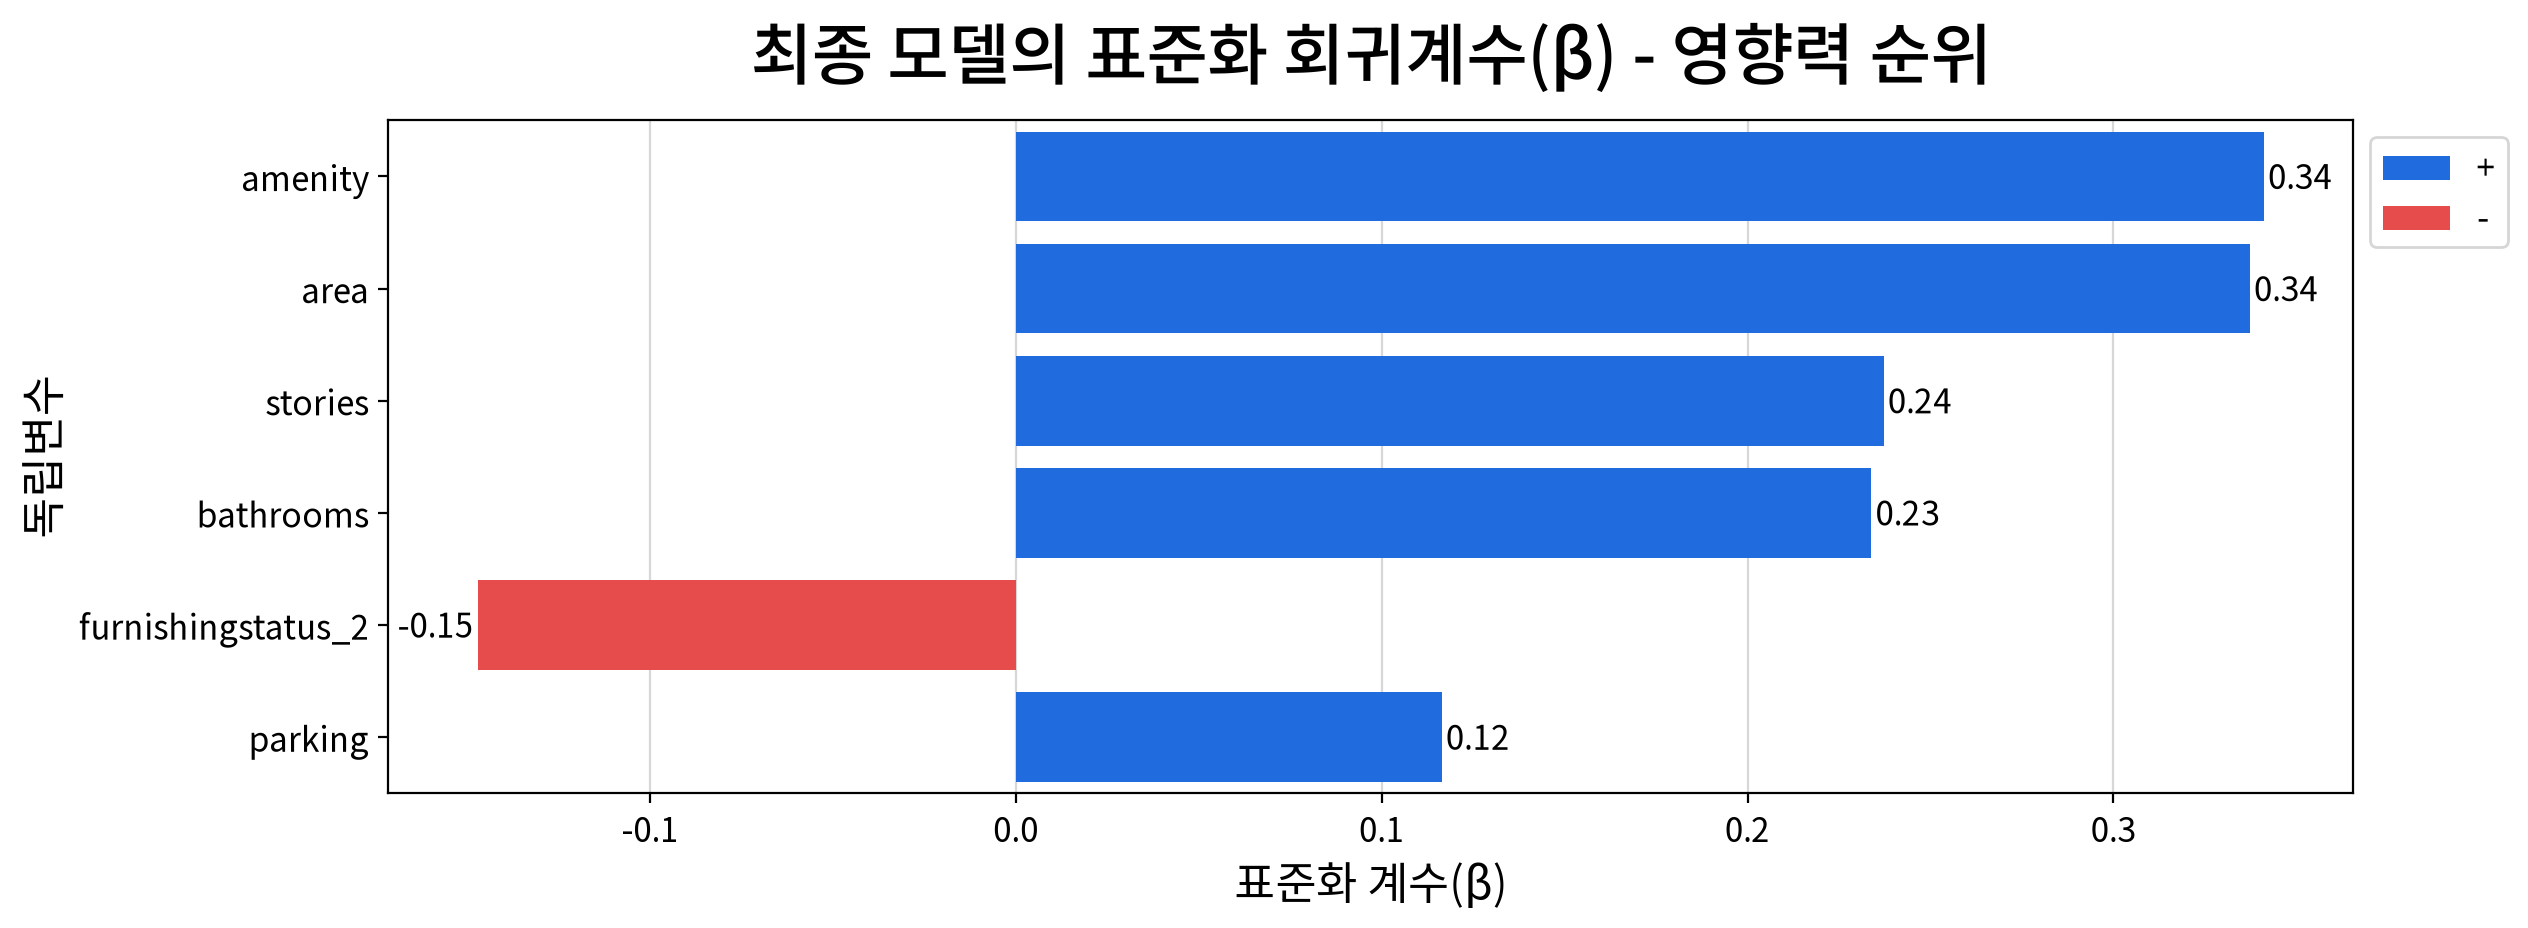

#### 4) 회귀계수 해석 문장

- **area** 의 회귀계수는 **B = 0.32** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(538) = 11.96**, **p < .001**) 즉, area가 **1% 증가**할 때 price는 평균적으로 약 **0.32% 증가**하는 것으로 해석된다.
- **bathrooms** 의 회귀계수는 **B = 0.27** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(538) = 8.31**, **p < .001**) 즉, bathrooms가 **1% 증가**할 때 price는 평균적으로 약 **0.27% 증가**하는 것으로 해석된다.
- **stories** 의 회귀계수는 **B = 0.19** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(538) = 9.89**, **p < .001**) 즉, stories가 **1% 증가**할 때 price는 평균적으로 약 **0.19% 증가**하는 것으로 해석된다.
- **parking** 의 회귀계수는 **B = 0.05** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(538) = 4.34**, **p < .001**) 즉, parking가 **1 증가**할 때 price는 평균적으로 약 **5.33% 증가**하는 것으로 해석된다.
- **amenity** 의 회귀계수는 **B = 0.11** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(538) = 14.41**, **p < .001**) 즉, amenity가 **1 증가**할 때 price는 평균적으로 약 **11.21% 증가**하는 것으로 해석된다.
- **furnishingstatus_2** 의 회귀계수는 **B = -0.12** 으로 나타났으며, 이는 **price** 에 유의한 요인임을 의미한다. (**t(538) = -5.76**, **p < .001**) 즉, furnishingstatus_2가 **1 증가**할 때 price는 평균적으로 약 **11.01% 감소**하는 것으로 해석된다.

> ※ 위 **t** 와 **유의확률** 은 등분산 가정이 충족되지 않은 경우를 대비해 **HC3 로버스트 표준오차**로 계산한 값이다.   
회귀계수(B)와 효과 크기 해석은 일반 OLS와 동일하며, 표준오차만 이분산에 강건하게 보정되어 t와 유의확률, 그에 따른 유의성 판정이 달라질 수 있다.

---

### ▶ 회귀모형 가정 검정

#### 1) 선형성 검정

,statistic,p-value,linearity,result
Ramsey RESET,0.176,0.675,True,귀무가설 채택 → 선형성 위배 근거 없음


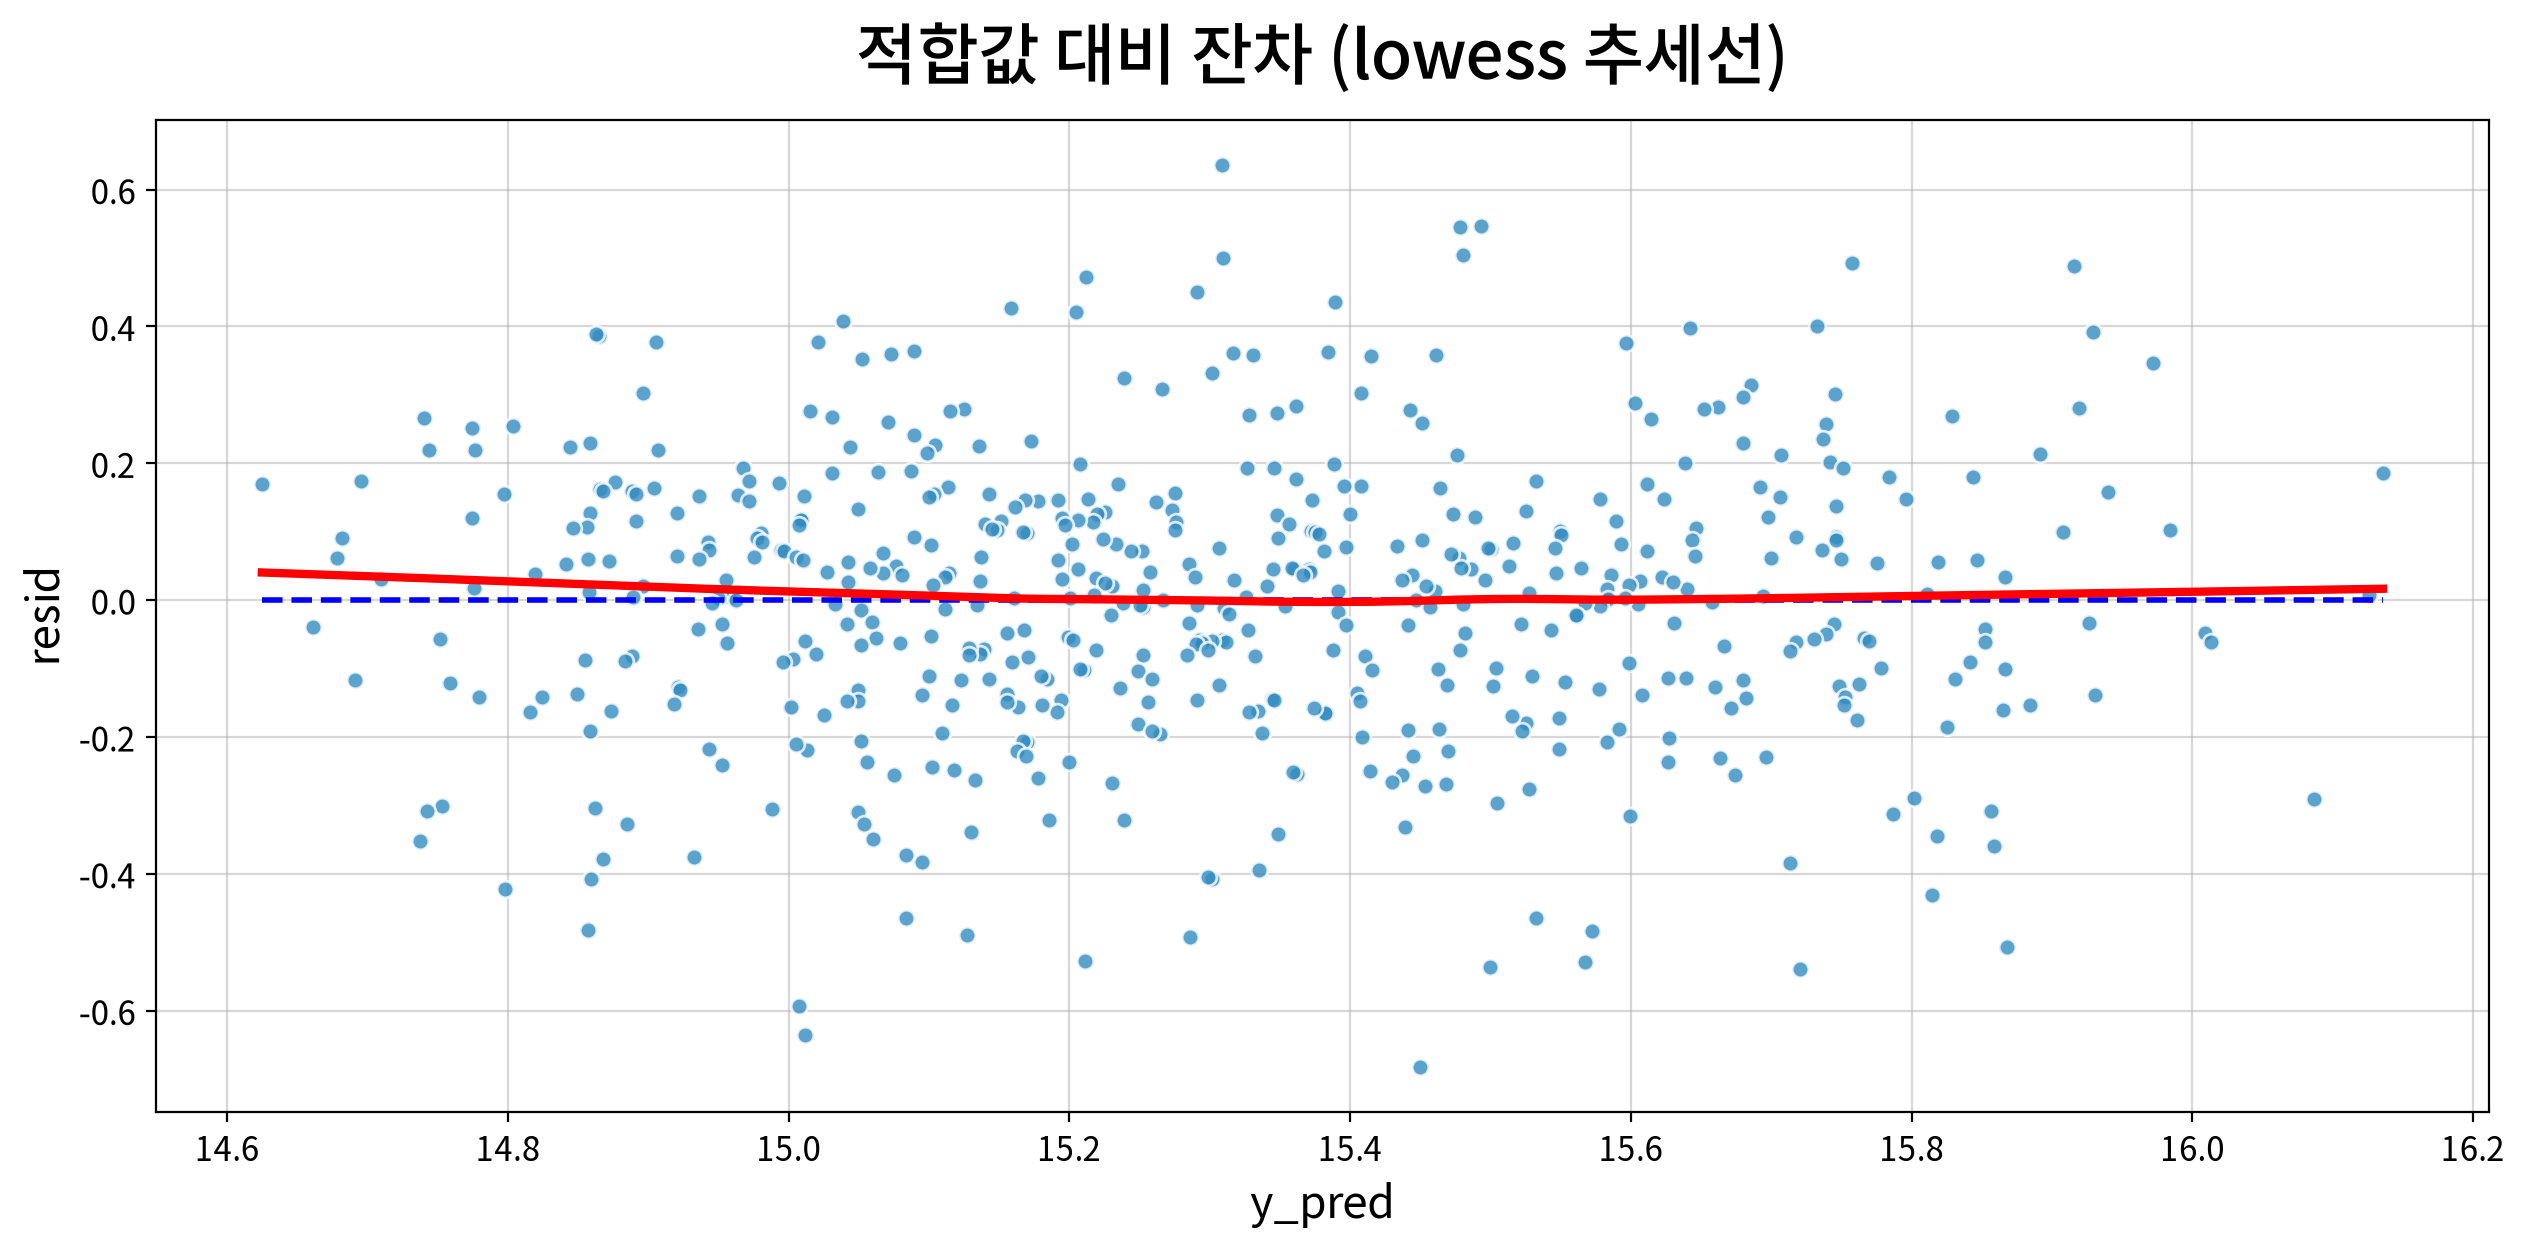

#### 2) 정규성 검정

▶ 검정통계량을 이용한 정규성 검정

,statistic,p-value,normality,result
Kolmogorov-Smirnov,0.040,0.331,True,귀무가설 채택 → 정규성 만족


▶ Q-Q 플롯을 이용한 정규성 검정

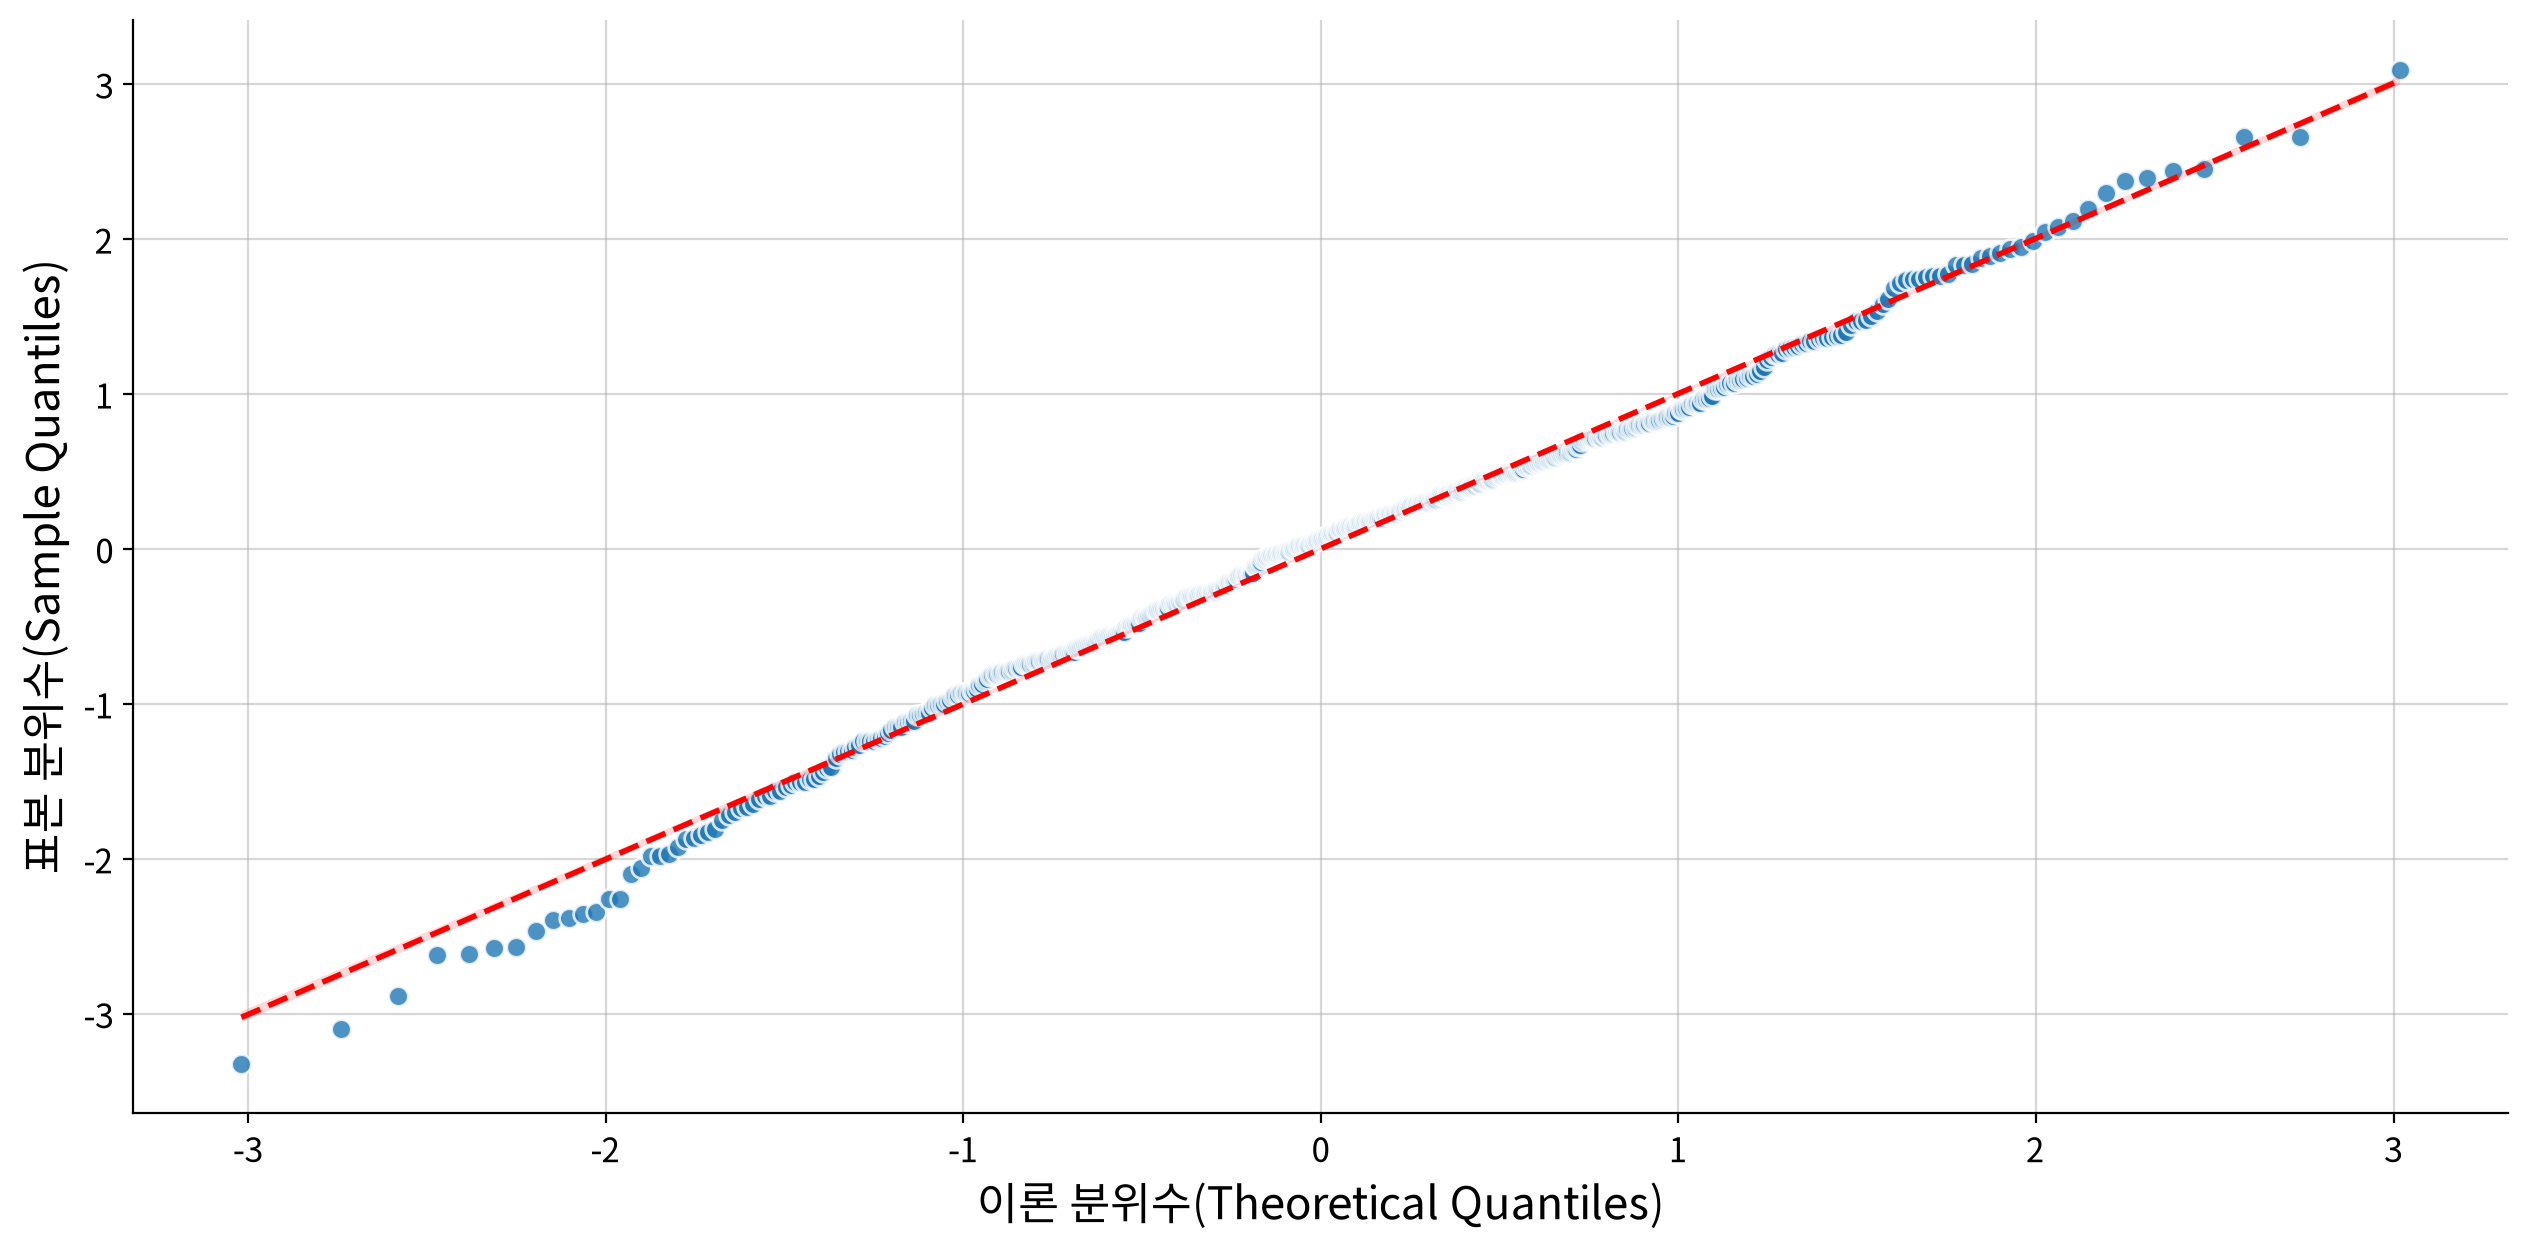

▶ √MSE 구간 규칙을 이용한 정규성 검정

,기대(%),허용 구간(%),실제(%),판정
구간,,,,
±1√MSE,68.000,64~72,72.110,위배
±2√MSE,95.000,93~97,94.860,충족
±3√MSE,99.700,99~100,99.450,충족


√MSE = 0.21 · 구간 규칙 판정: 정규성 위배


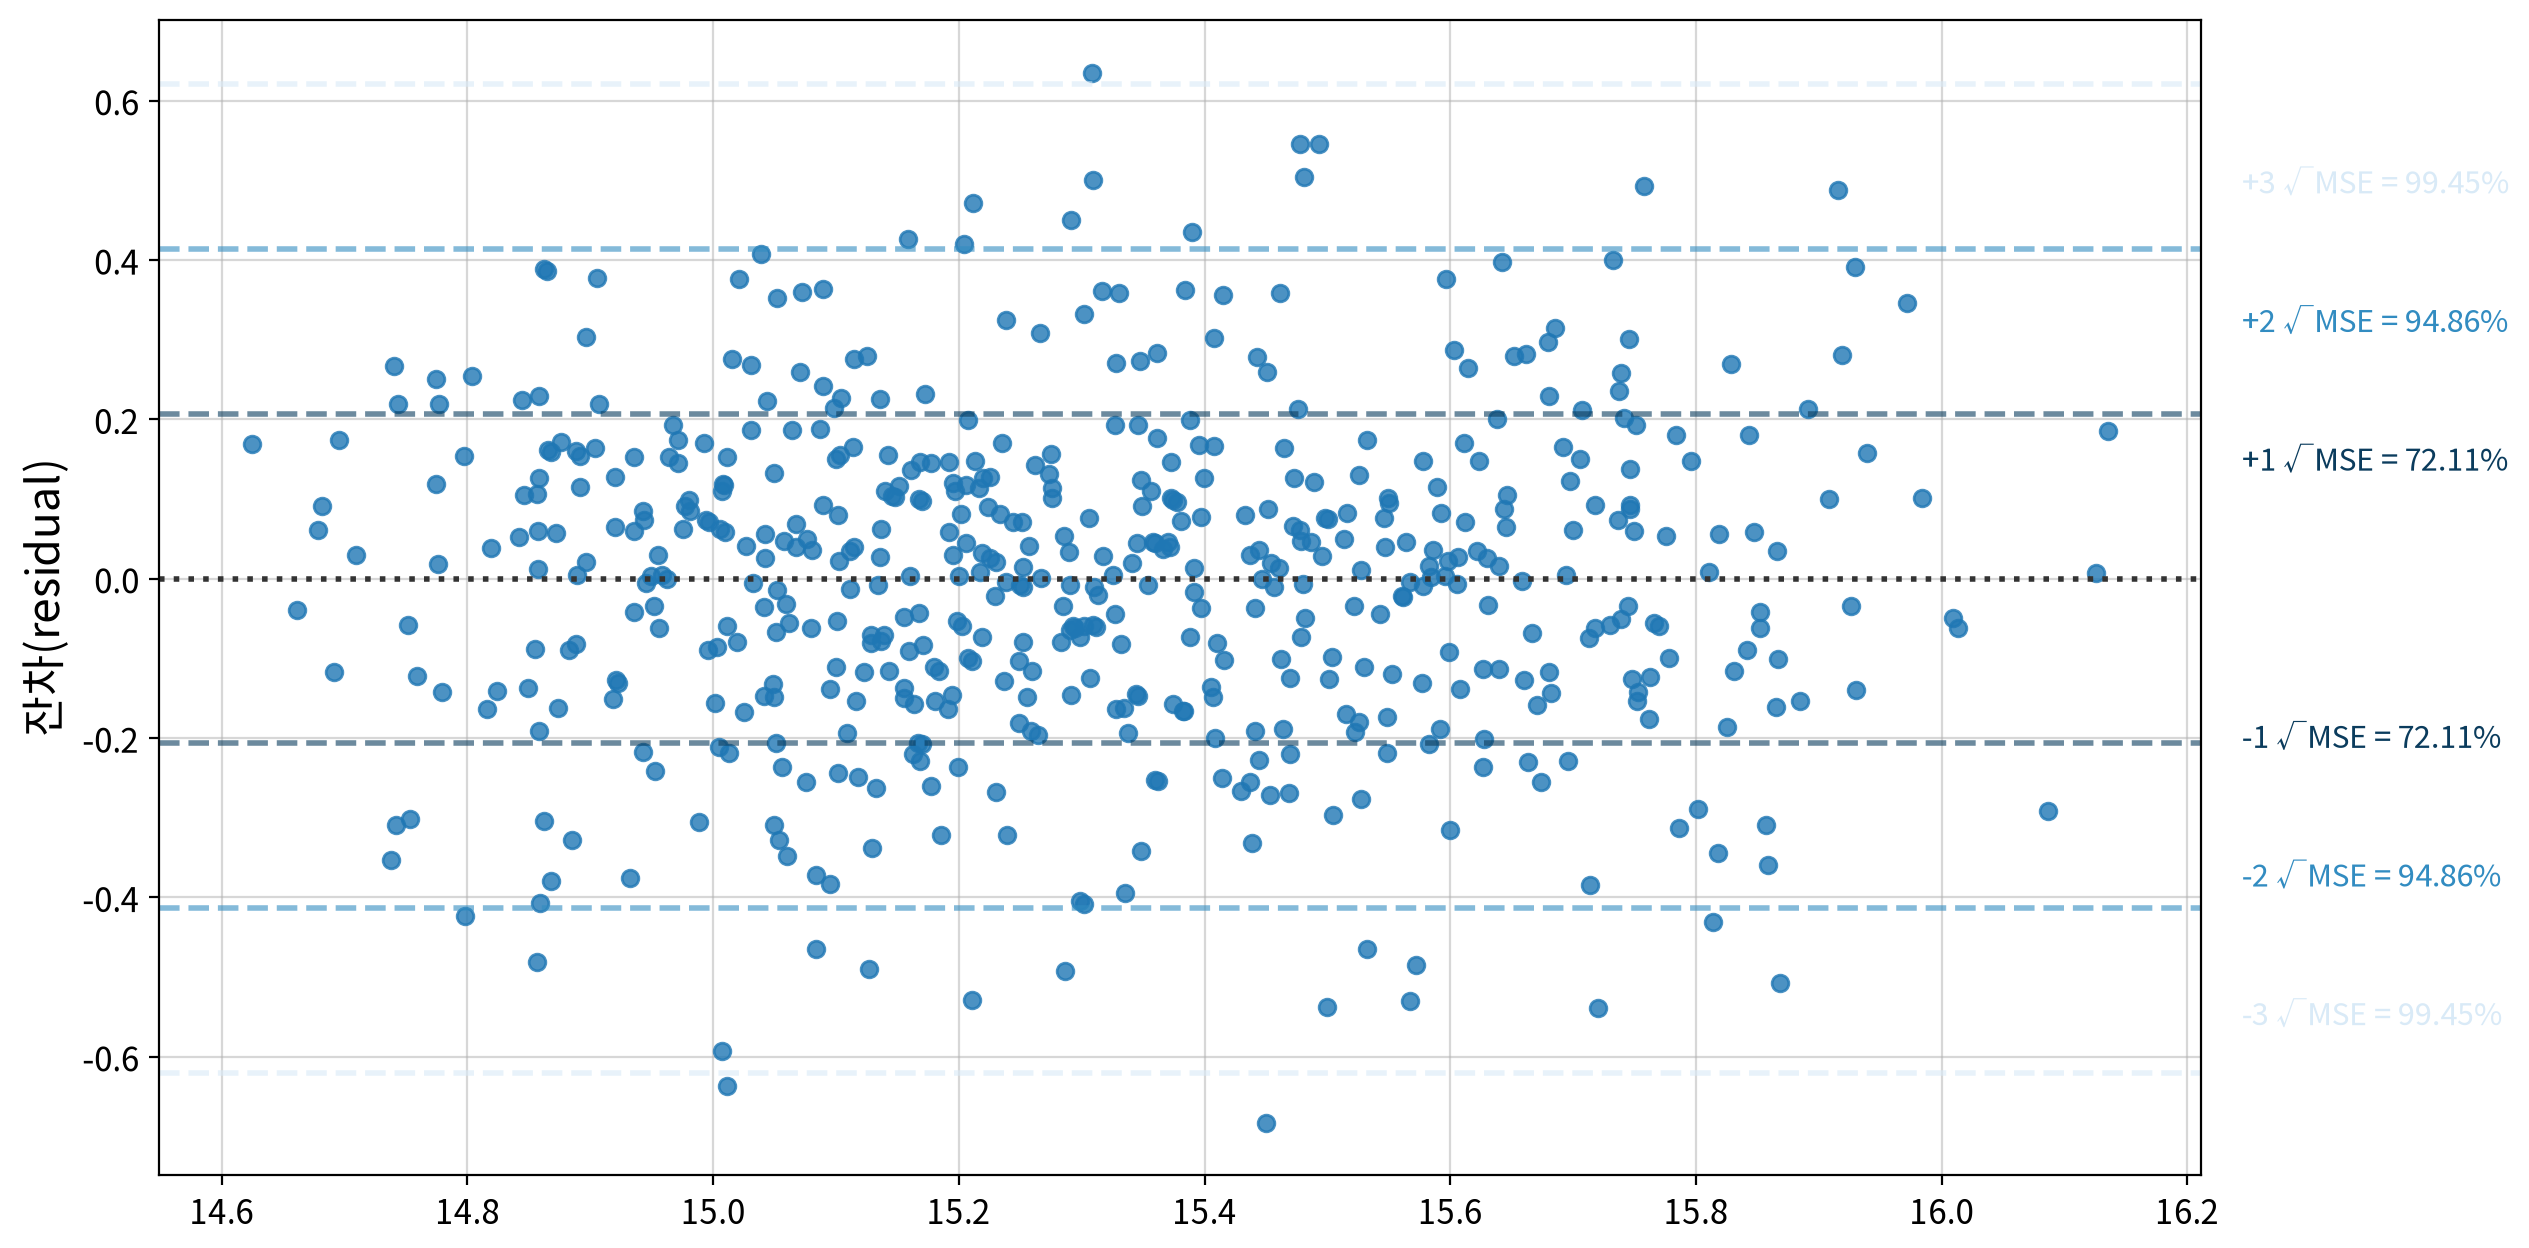

#### 3) 등분산성 검정

,LM Statistic,LM p-value,F Statistic,F p-value,homoscedasticity
Breusch-Pagan,15.090,0.020,2.554,0.019,False


F p-value = 0.0190 · 등분산성 판정: 대립가설 채택 → 등분산성 위배



#### 4) 독립성 검정

,statistic,independence,result
Durbin-Watson,1.310,False,독립성 위반 (양(+)의 자기상관)


In [29]:
my_ols.report_model(final_fit)

> 💡 **인사이트 — 최종 모델**
>
> - 최종 모델은 **`7_도메인_이상치대체`** 다. `log(price)`를 종속변수로, `area` · `bathrooms` · `stories`에 로그를 쓴 모델이다.
> - **F(6, 538) = 204.03, p < .001, R² = 0.695** — log(가격) 변동의 약 70%를 설명한다.
> - 영향력(β): **`amenity`(0.341) ≈ `area`(0.337)** > `stories`(0.237) ≈ `bathrooms`(0.234) > 가구 미비치(−0.147) > `parking`(0.116)
> - 계수 해석 (종속변수가 log라 **% 변화**로 읽는다):
>   - 옵션 1개 추가 → 가격 **+11.2%**
>   - 면적 1% 증가 → 가격 **+0.32%** (탄력성 0.316)
>   - 가구 미비치 → 가구 완비 대비 **−11.0%**
> - 가정 검정: **선형성(RESET p = 0.675) · 정규성(K-S p = 0.331) 충족**, 등분산성은 위배(BP p = 0.019)라 HC3로 보정했다.
> - 독립성(DW = 1.31)도 위배로 나왔다. DW는 **행 순서상 옆 행끼리 오차가 닮았는지**를 보는데, 원본 데이터가 가격이 비싼 집부터 정렬돼 있어 비슷한 오차가 연달아 나타난 것으로 보인다. 서로 다른 집을 모은 데이터라 행 순서에는 의미가 없으므로, 실질적인 문제는 아니다.

---

# 📌 종합 인사이트

### 1. 가격은 '크기'와 '갖춘 것'이 비슷한 비중으로 결정한다
- 영향력 1·2위가 **편의시설 점수(β = 0.341)** 와 **면적(β = 0.337)** 으로 거의 같다.
- 층수 · 욕실 · 가구 비치 · 주차가 뒤를 잇고, 침실 수는 면적 · 층수에 흡수돼 빠졌다.

### 2. 옵션은 '종류'보다 '개수'
- 보유 옵션이 0개 → 5개로 늘면 가격 중앙값이 약 2.1배가 된다. 옵션 6종 모두 '있는 집'이 유의하게 비쌌다(중앙값 +20~48%).
- 6개 더미를 `amenity` 하나로 묶어 **변수 11개 → 6개**, RMSE는 1위 모델과 2.28% 차이에 그쳤다.

### 3. 리모델링 답변: 넓히기보다 설비 하나
- 최종 모델의 계수로 보면, 옵션을 1개 들이면 가격 **+11.2%**, 면적을 10% 넓히면 약 **+3.1%** 로, 가격 효과는 설비 쪽이 3배 이상 크다.
- 옵션 1개만큼 가격을 올리려면 면적을 **약 40%** 넓혀야 한다(최종 모델의 면적 탄력성 0.316으로 환산 : 1.112^(1/0.316) ≈ 1.40). 현실적인 증축 범위에서는 설비 하나가 더 큰 효과를 낸다.
- 다만 공사 비용은 분석하지 않았으므로, 실제 판단은 각 공사의 비용과 함께 따져야 한다.

### 4. 간명성 규칙의 작동
- RMSE 1위와 5% 이내라면 변수가 적은 모델을 고른다. 성능을 2% 남짓 양보하고 변수를 절반 가까이 줄인 모델이, 설명하고 활용하기에는 더 쓸모 있다.

### ⚠️ 한계
- R² 0.695 — 가격의 약 30%는 **입지 세부 정보 · 건축 연도 · 관리 상태** 같은 데이터에 없는 요인이다.
- `amenity`는 옵션의 **개수**만 세기 때문에, 에어컨이든 지하실이든 효과가 같다고 가정한다. 실제로는 EDA에서 옵션마다 가격 차이가 달랐다(중앙값 +20~48%). 변수를 줄이는 대신 옵션별 차이를 포기한 **단순화**다.
- 관측 데이터의 상관관계이므로, 리모델링을 했을 때의 **인과 효과로 단정할 수 없다.**
- 성능은 모델을 학습시킨 데이터로 평가한 값(in-sample)이다. 처음 보는 데이터에서의 예측력은 train/test 분할이나 교차검증으로 확인해야 한다.

### ✅ 최종 모델
| 항목 | 값 |
|---|---|
| 모델 | `7_도메인_이상치대체` |
| 형태 | `log(price)` ~ `log(area)` + `log(bathrooms)` + `log(stories)` + `parking` + `amenity` + 가구 미비치 |
| 성능 | RMSE 1,057,250 · MAE 758,575 · R²(원본 척도) 0.680 |
| 가정 | 선형성 ✅ · 정규성 ✅ · 등분산성 ❌ (HC3 보정) · 독립성 ❌ (행 정렬 영향) |
| 가장 큰 영향 | `amenity` (β = 0.341) ≈ `area` (β = 0.337) |